# Лекция 8. Parameter-efficient fine-tuning VLM

Курс «Современное компьютерное зрение». Блокнот рассчитан на запуск в Google Colab (бесплатный GPU T4) и проверен на CPU в режиме `FAST_DEV_RUN`.

В лекции 6 мы разобрали, как устроена vision-language модель: визуальный энкодер, проектор (коннектор) и языковая модель, а также как её оценивать. В лекции 7 VLM использовалась «как есть» — через промпт и constrained decoding. Эта лекция отвечает на следующий вопрос: что делать, если промпта недостаточно и модель нужно адаптировать под свою задачу, а в распоряжении одна бесплатная видеокарта на 15 ГБ.

Ответ состоит из трёх частей. Во-первых, правильно подготовить данные для supervised fine-tuning (SFT): диалоговый формат, шаблон чата конкретной модели, визуальные токены и маска loss. Во-вторых, обучать не все миллиарды параметров, а небольшую добавку — низкоранговый адаптер LoRA, а замороженную базовую модель хранить в 4 битах (QLoRA). В-третьих, уложить обучение в память приёмами batch size 1, gradient accumulation, gradient checkpointing и memory-efficient attention. И наконец, после адаптации нужно честно проверить, что модель стала лучше на своей задаче, не сломалась на соседних (OOD) и не забыла то, что умела.

LoRA - Low-Rank Adaptation, или низкоранговая адаптация. Метод эффективной тонкой настройки (дообучения) больших предварительно обученных моделей (например, для генерации изображений или работы с текстом), при котором исходные параметры модели остаются неизменными («замороженными»), а обучаются только небольшие дополнительные матрицы.

## Цели лекции

После лекции вы сможете:

1. Подготовить мультимодальный SFT-датасет: записать примеры в формате messages, собрать их шаблоном чата конкретной модели, объяснить роль визуальных токенов и построить маску loss только по ответу ассистента.
2. Вывести LoRA, объяснить смысл ранга $r$, коэффициента $\alpha$, масштаба $\alpha / r$ и $\alpha / \sqrt{r}$ (rsLoRA), выбрать целевые модули и посчитать число обучаемых параметров.
3. Объяснить, как устроены NF4, double quantization и paged optimizers в QLoRA, и оценить память, которую они экономят.
4. Составить бюджет памяти обучения (веса, градиенты, состояния оптимизатора, активации) и уменьшить его с помощью batch size 1, gradient accumulation с правильной нормировкой, gradient checkpointing и memory-efficient attention.
5. Запустить одно и то же обучение через Transformers/PEFT, TRL, LLaMA-Factory или Unsloth и сделать конфигурацию воспроизводимой.
6. Спланировать оценку после адаптации: ID и OOD-наборы, замер катастрофического забывания и способы его ослабить.

## Содержание

Часть I. Теория

1. Когда нужна адаптация и зачем PEFT
2. Семейство методов parameter-efficient fine-tuning
3. SFT мультимодальных моделей: данные и формат
4. Chat templates и специальные визуальные токены
5. Маскирование loss и его нормировка
6. Что замораживать: этапы обучения VLM
7. LoRA: вывод, ранг, α, целевые модули, варианты
8. Квантование и QLoRA: NF4, double quantization, paged optimizers
9. Бюджет памяти обучения
10. Batch size 1 и gradient accumulation
11. Gradient checkpointing
12. Memory-efficient attention и смешанная точность
13. Инструменты: Transformers/PEFT, TRL, LLaMA-Factory, Unsloth
14. Воспроизводимость конфигов
15. Оценка после адаптации: ID и OOD
16. Катастрофическое забывание: измерение и защита
17. Практические рекомендации и типичные ошибки

Часть II. Практика (разделы 0–10, исполняемый код)

Контрольные вопросы, задания и список источников — в конце блокнота.

## Обозначения

| Символ | Смысл |
|---|---|
| $W_0 \in \mathbb{R}^{d_{out} \times d_{in}}$ | замороженная матрица весов линейного слоя |
| $A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$ | матрицы LoRA-адаптера |
| $r$ | ранг адаптера |
| $\alpha$ | коэффициент масштаба LoRA (`lora_alpha`) |
| $x_{1:T}$ | токены последовательности (текст и визуальные токены) |
| $m_t \in \{0, 1\}$ | маска loss: 1, если токен $t$ входит в ответ ассистента |
| $s, b, h, a, L$ | длина последовательности, размер микробатча, скрытая размерность, число голов внимания, число слоёв |
| $K$ | число шагов gradient accumulation |
| $P$ | число параметров модели |

# Часть I. Теория

## 1. Когда нужна адаптация и зачем PEFT

### 1.1. Лестница вмешательств

Перед тем как обучать модель, стоит пройти «лестницу» более дешёвых вмешательств, каждое из которых на порядок проще следующего:

1. Промпт: инструкция, формат ответа, примеры (few-shot) в контексте. Ничего не обучается, изменение вступает в силу сразу.
2. Ограничение вывода: JSON Schema, грамматики, constrained decoding (лекция 7). Гарантирует формат, но не правильность содержания.
3. Retrieval и инструменты: подставить в контекст справочную информацию или дать модели вызвать детектор, OCR, калькулятор.
4. Дообучение (fine-tuning): изменить веса.

Дообучение оправдано, когда выполняется хотя бы одно из условий:

- нужное поведение трудно описать словами, но легко показать на примерах (стиль, тонкие критерии, предметная терминология);
- модель систематически ошибается в восприятии, специфичном для домена: медицинские снимки, промышленные дефекты, спутниковые изображения, схемы и чертежи;
- нужен короткий промпт и низкая задержка: инструкция на тысячу токенов и десять примеров в контексте стоят дорого на каждом запросе, а после SFT поведение «зашито» в веса;
- нужна меньшая модель: дообученная 2B-модель часто заменяет промпт к 30B-модели на узкой задаче;
- данные нельзя отправлять во внешний API, и модель должна работать локально.

Обратная сторона: дообучение требует данных, вычислений, процедуры оценки и несёт риск испортить то, что модель умела (раздел 16).

### 1.2. Почему не полное дообучение

Полное дообучение (full fine-tuning) обновляет все параметры. Для модели с $P$ параметрами в смешанной точности с оптимизатором Adam нужно примерно 16 байт на параметр: веса в bf16 (2 байта), градиенты (2), fp32-копия весов (4) и два момента Adam (8). Для 4B-модели это 64 ГБ без учёта активаций — в четыре раза больше, чем есть на T4. Кроме того, каждая задача порождает полную копию модели: 8 ГБ на диске в bf16.

Parameter-efficient fine-tuning (PEFT) обучает малую долю параметров — обычно от 0.1 до 2% — при замороженной базовой модели. Три следствия:

- градиенты и состояния оптимизатора нужны только для обучаемой части, и основная экономия памяти именно здесь;
- результат обучения — небольшой файл (мегабайты), который хранится отдельно и подключается к одной и той же базовой модели; адаптеры разных задач можно переключать на лету;
- малое число степеней свободы работает как регуляризатор: модель меньше переобучается на малых данных и меньше забывает (раздел 16).

Оригинальная статья LoRA приводит масштаб выгоды для GPT-3 175B: память при обучении снизилась с 1.2 ТБ до 350 ГБ, а размер чекпоинта при $r = 4$ и адаптации только $W_q, W_v$ — примерно в 10 000 раз, с 350 ГБ до 35 МБ ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)).

### 1.3. Пример: когда что выбрать

| Ситуация | Разумный первый шаг |
|---|---|
| Модель отвечает правильно, но не в том формате | промпт + constrained decoding |
| Нужно 20 полей из счёта-фактуры, модель путает поля, есть 2000 размеченных документов | SFT с LoRA |
| Классификация дефектов на снимках, модель «не видит» дефект | сначала проверить, видит ли его визуальный энкодер (linear probe на признаках); если нет — адаптация энкодера или специализированная модель |
| Нужно, чтобы модель отказывалась отвечать вне домена | SFT с примерами отказов или preference-обучение (DPO), это отдельная тема |
| Свежие факты о продуктах компании | retrieval, а не дообучение: факты, внесённые в веса, плохо обновляются |

## 2. Семейство методов parameter-efficient fine-tuning

Методы PEFT различаются тем, куда добавляются обучаемые параметры.

Адаптеры (adapters). Между слоями трансформера вставляются маленькие сети вида down-projection → нелинейность → up-projection с остаточной связью. На GLUE адаптеры отстают от полного дообучения на 0.4 п.п., добавляя 3.6% параметров на задачу ([Houlsby et al., 2019](https://arxiv.org/abs/1902.00751)). Минус — дополнительные последовательные слои, а значит, задержка на инференсе.

Prompt tuning и prefix tuning. Обучаются не веса, а «виртуальные токены»: векторы, добавляемые к входу ([Lester et al., 2021](https://arxiv.org/abs/2104.08691)) или к ключам и значениям в каждом слое ([Li, Liang, 2021](https://arxiv.org/abs/2101.00190)). Очень мало параметров, но эти токены занимают часть контекста и хуже работают на небольших моделях.

Выборочное дообучение. Размораживается часть исходных параметров: только bias (BitFit, [Ben Zaken et al., 2021](https://arxiv.org/abs/2106.10199)), только последние слои, только нормализации. Просто, но ёмкость ограничена выбором подмножества.

(IA)³. Каждому ключу, значению и промежуточной активации MLP сопоставляется обучаемый вектор масштаба, на который поэлементно умножается активация ([Liu et al., 2022](https://arxiv.org/abs/2205.05638)). Параметров ещё меньше, чем у LoRA.

Репараметризация: LoRA и её варианты. Изменение весов $\Delta W$ представляется произведением двух низкоранговых матриц. После обучения его можно прибавить к исходным весам, и инференс не замедляется. Именно LoRA стала стандартом для LLM и VLM, поэтому дальше лекция сосредоточена на ней. Варианты: DoRA разделяет модуль и направление весов ([Liu et al., 2024](https://arxiv.org/abs/2402.09353)), rsLoRA меняет масштаб ([Kalajdzievski, 2023](https://arxiv.org/abs/2312.03732)), QLoRA хранит базовую модель в 4 битах ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

| Метод | Где обучаемые параметры | Задержка на инференсе | Типичная доля параметров |
|---|---|---|---|
| Full FT | все | нет | 100% |
| Adapters | новые блоки между слоями | есть | 1–4% |
| Prompt / prefix tuning | виртуальные токены | занимает контекст | < 0.1% |
| BitFit | bias | нет | < 0.1% |
| (IA)³ | векторы масштаба активаций | нет после слияния | < 0.1% |
| LoRA / DoRA | низкоранговые добавки к весам | нет после слияния | 0.1–2% |

## 3. SFT мультимодальных моделей: данные и формат

### 3.1. Что такое SFT

Supervised fine-tuning — обучение модели продолжать диалог «как в примерах». Обучающий пример — пара (контекст, эталонный ответ), где контекст включает изображения и реплики пользователя. Цель — максимизировать правдоподобие эталонного ответа при данном контексте:

$$
\mathcal{L}(\theta) = -\sum_{t \in \text{answer}} \log p_\theta\left(x_t \mid x_{<t}, I\right),
$$

где $I$ — изображения, $x_{<t}$ — все предыдущие токены, включая визуальные и токены вопроса. Это тот же next-token loss, что и при предобучении, но считается он только по ответу (раздел 5). Именно так обучалась LLaVA: модель учат предсказывать ответы ассистента и место остановки, и только эти токены входят в loss ([Liu et al., 2023](https://arxiv.org/abs/2304.08485)).

### 3.2. Instruction-формат: messages

Данные хранят в нейтральном формате — списке реплик с ролями `system`, `user`, `assistant`. Содержимое мультимодальной реплики — список частей:

```json
{
  "messages": [
    {"role": "system", "content": [{"type": "text", "text": "You are a quality inspector."}]},
    {"role": "user", "content": [
        {"type": "image", "image": "images/part_0042.jpg"},
        {"type": "text", "text": "Is there a defect? Answer with JSON."}]},
    {"role": "assistant", "content": [{"type": "text", "text": "{\"defect\": true, \"type\": \"scratch\"}"}]}
  ]
}
```

Такой формат используют Transformers, TRL и Unsloth ([Unsloth: Vision Fine-tuning](https://docs.unsloth.ai/basics/vision-fine-tuning)); LLaMA-Factory принимает близкий формат sharegpt, где изображение обозначается тегом `<image>` в тексте реплики, а пути к файлам лежат в отдельном столбце `images` ([LLaMA-Factory, data/README](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md)).

Почему не хранить сразу готовую строку промпта? Потому что строка зависит от модели (раздел 4), а данные должны переживать смену модели. Нейтральный формат плюс шаблон модели дают правильную строку автоматически.

### 3.3. Типы мультимодальных SFT-данных

| Тип | Пример инструкции | Чему учит |
|---|---|---|
| Описание | «Опиши изображение подробно» | выравнивание визуальных и текстовых представлений |
| VQA, короткий ответ | «Сколько людей на фото?» | точное восприятие, краткость |
| Структурированное извлечение | «Верни JSON с полями счёта» | формат, внимание к деталям |
| Grounding | «Где находится красная машина? Верни bbox» | локализация (координаты как текст) |
| Рассуждение | «Почему эта конструкция неустойчива?» | цепочки рассуждений по изображению |
| Многоходовой диалог | несколько вопросов к одному изображению | использование контекста диалога |
| Отказ | вопрос не по изображению или вне домена | границы компетенции |

Для узкой задачи обычно достаточно сотен–тысяч примеров одного типа. Но если в данных только один тип, модель «схлопывается» на него: на любой вопрос начинает отвечать в формате задачи. Это первое проявление забывания, и мы увидим его в практике. Поэтому в данные часто добавляют долю общих примеров (replay, раздел 16).

### 3.4. Качество данных важнее количества

Несколько правил, которые в SFT окупаются сильнее подбора гиперпараметров:

- Ответы должны быть согласованными: один и тот же вопрос — один формат, одна точность, одни единицы. Противоречия в разметке модель выучивает как шум.
- Ответ должен опираться на изображение. Если ответ можно угадать по тексту вопроса, модель научится игнорировать изображение (language prior) и будет галлюцинировать.
- Разбиение train/val/test — по исходным объектам (документам, пациентам, сценам), а не по примерам: иначе почти-дубликаты попадут в тест (лекция 7).
- Отложите OOD-набор заранее: данные, похожие на будущий продакшен, но отличающиеся от train по контролируемой оси.

## 4. Chat templates и специальные визуальные токены

### 4.1. Что делает шаблон

Chat template — шаблон на языке Jinja, который хранится в `tokenizer_config.json` или `chat_template.json` модели и превращает список messages в строку. Шаблон добавляет маркеры начала и конца реплик, имена ролей, системный промпт по умолчанию и плейсхолдеры изображений. Вызов `processor.apply_chat_template(messages, add_generation_prompt=True)` добавляет в конец маркер начала ответа ассистента: с этого места модель начнёт генерировать.

Один и тот же диалог в разных моделях (вывод практики, раздел 2.2):

```text
SmolVLM:  <|im_start|>User:<image>Question<end_of_utterance>\nAssistant: Answer<end_of_utterance>\n
Qwen3-VL: <|im_start|>user\n<|vision_start|><|image_pad|><|vision_end|>Question<|im_end|>\n<|im_start|>assistant\nAnswer<|im_end|>\n
```

Ошибки шаблона — одни из самых коварных: модель обучается и даже работает, но хуже. Типичные случаи:

- обучение с одним шаблоном, инференс с другим (например, данные собраны вручную под «похожий» формат, а сервер применяет официальный шаблон);
- отсутствие токена конца реплики в ответе: модель не учится останавливаться и продолжает генерировать;
- двойной BOS-токен: шаблон уже добавил его, а токенизатор добавил ещё раз;
- у моделей с режимом рассуждений шаблон может вставлять блок `<think>...</think>`; в LLaMA-Factory для этого есть отдельные шаблоны, например `qwen3_vl_nothink` в примере конфигурации Qwen3-VL ([LLaMA-Factory, examples](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_sft.yaml)).

Правило: шаблон берётся из процессора той же модели и той же ревизии, что используется на инференсе, и фиксируется в конфиге обучения.

### 4.2. Визуальные токены

Языковая модель не видит пиксели. Визуальный энкодер превращает изображение в последовательность векторов, проектор отображает их в пространство эмбеддингов языковой модели, и эти векторы встают в последовательность на места специальных токенов-плейсхолдеров.

Процесс в два шага:

1. Шаблон вставляет один плейсхолдер на изображение (`<image>` или `<|image_pad|>`).
2. Процессор знает, сколько векторов даст энкодер для данного изображения, и размножает плейсхолдер до этого числа. После прямого прохода эмбеддинги этих позиций заменяются выходами проектора.

Число визуальных токенов зависит от архитектуры:

| Модель | Как считаются токены | Изображение 512×512 |
|---|---|---|
| LLaVA-1.5 | фиксированное число патчей CLIP ViT-L/14 при 336 px | 576 (изображение приводится к 336×336) |
| Qwen2-VL / Qwen3-VL | динамическое разрешение: патчи 16×16 (Qwen3-VL), затем слияние 2×2 | 256 |
| SmolVLM | SigLIP-B/16 даёт 1024 вектора, pixel shuffle сжимает их в 16 раз | 64 (без нарезки на тайлы) |

Qwen2-VL ввела naive dynamic resolution: изображение любого размера превращается в число токенов, пропорциональное площади ([Wang et al., 2024](https://arxiv.org/abs/2409.12191)). Для SmolVLM авторы описывают pixel shuffle, переставляющий пространственные блоки в каналы, и приводят пример: изображение 512×512 при кодировании SigLIP-B/16 даёт 1024 токена до сжатия ([Marafioti et al., 2025](https://arxiv.org/abs/2504.05299)). В практике 512×512-изображение SmolVLM превращается в 64 токена, а 256×256-изображение Qwen3-VL — тоже в 64.

Почему это важно для дообучения:

- визуальные токены — основная часть длины последовательности, и именно они определяют память на активации; ограничение разрешения (`image_max_pixels` в LLaMA-Factory, `max_pixels` в процессоре Qwen) — главный рычаг экономии памяти для VLM;
- при обрезке длинных последовательностей (`max_length`, `cutoff_len`) нельзя отрезать часть визуальных токенов: число плейсхолдеров перестанет совпадать с числом векторов энкодера, и модель упадёт или получит испорченный вход. Документация TRL прямо рекомендует для VLM `max_length=None` ([TRL SFTTrainer](https://huggingface.co/docs/trl/main/en/sft_trainer));
- служебные токены вокруг изображения (`<|vision_start|>`, `<fake_token_around_image>`, `<global-img>`) — часть шаблона, их нельзя опускать.

## 5. Маскирование loss и его нормировка

### 5.1. Маска

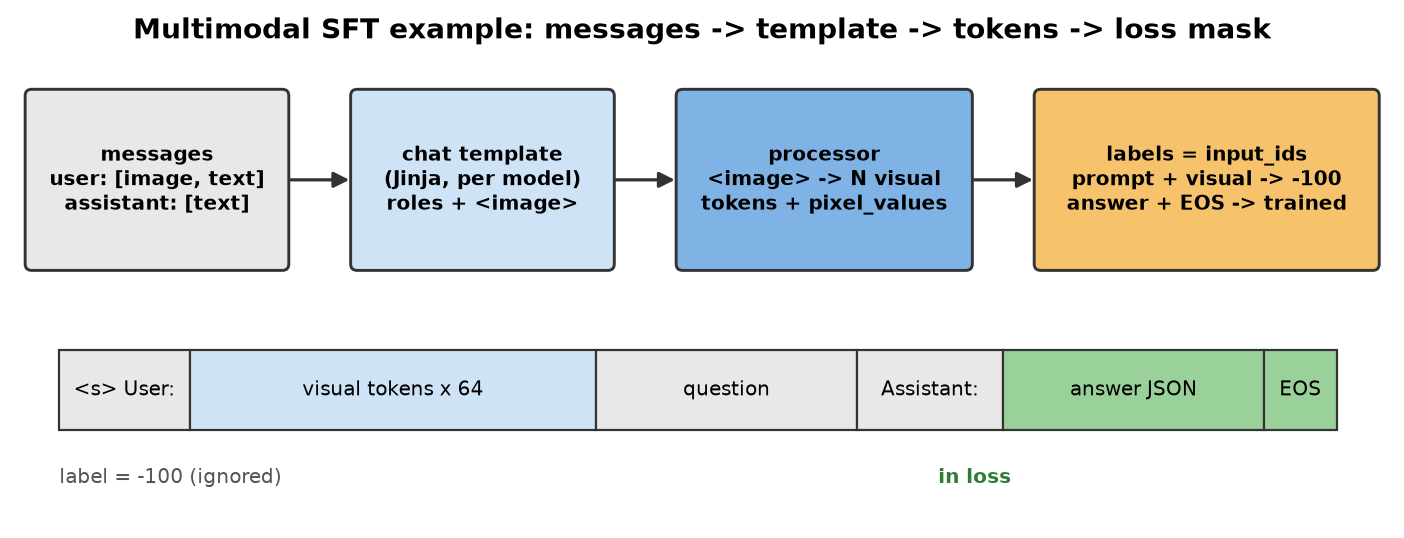

Пусть $m_t = 1$ для токенов ответа ассистента (включая токен конца реплики) и $m_t = 0$ для всего остального: системного промпта, вопроса, визуальных токенов, паддинга. Loss одного примера:

$$
\mathcal{L} = -\frac{1}{\sum_t m_t} \sum_{t=1}^{T} m_t \log p_\theta(x_t \mid x_{<t}).
$$

На практике маску задают через метки: `labels[t] = -100` для позиций с $m_t = 0$. Значение −100 — `ignore_index` функции `CrossEntropyLoss` в PyTorch. Внутри модели метки сдвигаются на одну позицию: логит позиции $t$ предсказывает токен $t+1$.

Как построить маску:

1. Через префикс: строка промпта с `add_generation_prompt=True` — префикс строки полного диалога; число токенов промпта (после развёртывания визуальных токенов) и есть граница. Просто и надёжно для одноходовых диалогов; так сделано в практике.
2. Через разметку шаблона: шаблоны с блоками `{% generation %}...{% endgeneration %}` позволяют `apply_chat_template(..., return_assistant_tokens_mask=True)` вернуть маску ассистентских токенов. На этом основан режим `assistant_only_loss=True` в TRL ([TRL SFTTrainer](https://huggingface.co/docs/trl/main/en/sft_trainer)).
3. Через поиск подпоследовательности: найти токены маркера ответа (например, `<|im_start|>assistant\n`) и открыть маску после каждого вхождения до маркера конца. Работает для многоходовых диалогов, но хрупко: токенизация маркера может зависеть от соседних символов.

### 5.2. Зачем маскировать

Пример из практики: в последовательности SmolVLM 136 токенов, из них 64 визуальных, около 45 токенов шаблона и вопроса, и только 27 — ответ вместе с токеном конца реплики. Без маски:

- loss по визуальным токенам бессмыслен: плейсхолдер — один и тот же токен, на его месте стоит вектор энкодера, а не предсказуемый текст;
- loss по вопросу заставляет модель моделировать распределение вопросов; при одинаковом вопросе во всех примерах эти токены быстро запоминаются, «разбавляют» градиент и уменьшают эффективный вклад ответа;
- в многоходовом диалоге модель учится говорить и за пользователя.

Маскирование ответа — стандарт, но не догма. Shi et al. показали, что loss и по инструкции (Instruction Modelling) в ряде сценариев улучшает результаты текстовых моделей, особенно когда инструкции длинные, ответы короткие, а примеров мало: это снижает переобучение на SFT-данных ([Shi et al., 2024](https://arxiv.org/abs/2405.14394)). Для VLM при этом визуальные токены маскируются в любом случае: предсказывать плейсхолдер бессмысленно. Если вопрос во всех примерах одинаковый, как в нашей практике, loss по нему ничего полезного не даёт.

### 5.3. Нормировка по токенам

Если ответы разной длины, есть два способа усреднить loss по батчу:

$$
\mathcal{L}_{\text{token}} = \frac{\sum_{i} \sum_t m_{i,t}\, \ell_{i,t}}{\sum_i \sum_t m_{i,t}}, \qquad
\mathcal{L}_{\text{sample}} = \frac{1}{B} \sum_i \frac{\sum_t m_{i,t}\, \ell_{i,t}}{\sum_t m_{i,t}}.
$$

Первый даёт одинаковый вес каждому токену (длинные ответы влияют сильнее), второй — каждому примеру (токены коротких ответов весят больше). Стандарт Transformers — первый. Разница становится ошибкой при gradient accumulation: если усреднять loss внутри каждого микробатча, а затем усреднять микробатчи, получается не $\mathcal{L}_{\text{token}}$ и не то, что было бы при большом батче. Эта ошибка была в Transformers и исправлена в 2024 году: правильная нормировка — сумма loss по всем микробатчам шага, делённая на общее число токенов ([Hugging Face, 2024](https://huggingface.co/blog/gradient_accumulation)). В практике (раздел 6.3) мы численно проверяем разницу.

## 6. Что замораживать: этапы обучения VLM

VLM состоит из трёх частей, и для каждой можно решить отдельно, обучать ли её.

| Часть | Типичный размер | Когда обучать |
|---|---|---|
| Визуальный энкодер (ViT, SigLIP) | 0.1–0.6 B | домен сильно отличается от естественных изображений: медицина, спектральные снимки, документы малого шрифта |
| Проектор (MLP) | 1–30 M | почти всегда можно; дёшево |
| Языковая модель | 0.1–70 B | основная часть адаптации: формат, рассуждение, терминология |

Классический рецепт LLaVA — два этапа. На первом обучается только проектор на 595 тысячах пар «изображение — подпись» из CC3M, а энкодер и языковая модель заморожены. На втором энкодер по-прежнему заморожен, а проектор и языковая модель обучаются на 158 тысячах инструкций ([Liu et al., 2023](https://arxiv.org/abs/2304.08485)). LLaVA-1.5 заменила линейный проектор двухслойным MLP и показала, что при 1.2 млн публичных примеров полное обучение занимает около суток на одном узле из 8 A100 ([Liu et al., 2023b](https://arxiv.org/abs/2310.03744)).

При адаптации уже обученной VLM под свою задачу этап выравнивания не нужен: проектор уже обучен. Типичный выбор — LoRA на всех линейных слоях языковой модели, а энкодер и проектор заморожены. В инструментах это отдельные флаги: `finetune_vision_layers` / `finetune_language_layers` в Unsloth ([Unsloth](https://docs.unsloth.ai/basics/vision-fine-tuning)), `freeze_vision_tower` и `freeze_multi_modal_projector` в LLaMA-Factory ([finetuning_args.py](https://github.com/hiyouga/LLaMA-Factory/blob/main/src/llamafactory/hparams/finetuning_args.py)).

Аргументы за заморозку энкодера: он обучен на сотнях миллионов изображений и дает общие признаки, а малые данные легко их испортят. Исследование катастрофического забывания в MLLM показывает, что даже при замороженном энкодере длительное дообучение снижает обобщение, а сами MLLM часто не сохраняют качество классификации, которое даёт их визуальный энкодер ([Zhai et al., 2023](https://arxiv.org/abs/2309.10313)). Обучать энкодер стоит только тогда, когда диагностика показывает, что он не различает нужные признаки: например, linear probe на его признаках не отделяет классы дефектов.

## 7. LoRA: вывод, ранг, α, целевые модули

### 7.1. Гипотеза низкого внутреннего ранга

Авторы LoRA исходят из наблюдения, что изменение весов при адаптации предобученной модели имеет низкий «внутренний ранг»: нужное изменение поведения достигается движением в маломерном подпространстве ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Тогда изменение весов линейного слоя можно искать сразу в виде произведения двух узких матриц:

$$
W = W_0 + \Delta W = W_0 + \frac{\alpha}{r} B A, \qquad B \in \mathbb{R}^{d_{out} \times r},\; A \in \mathbb{R}^{r \times d_{in}},\; r \ll \min(d_{in}, d_{out}).
$$

Прямой проход слоя:

$$
h = W_0 x + \frac{\alpha}{r} B (A x).
$$

Матрица $W_0$ заморожена, обучаются только $A$ и $B$. Вместо $d_{in} d_{out}$ параметров обучается $r (d_{in} + d_{out})$. Пример: для слоя 2048×2048 и $r = 16$ это 65 536 вместо 4 194 304, то есть 1.6%.

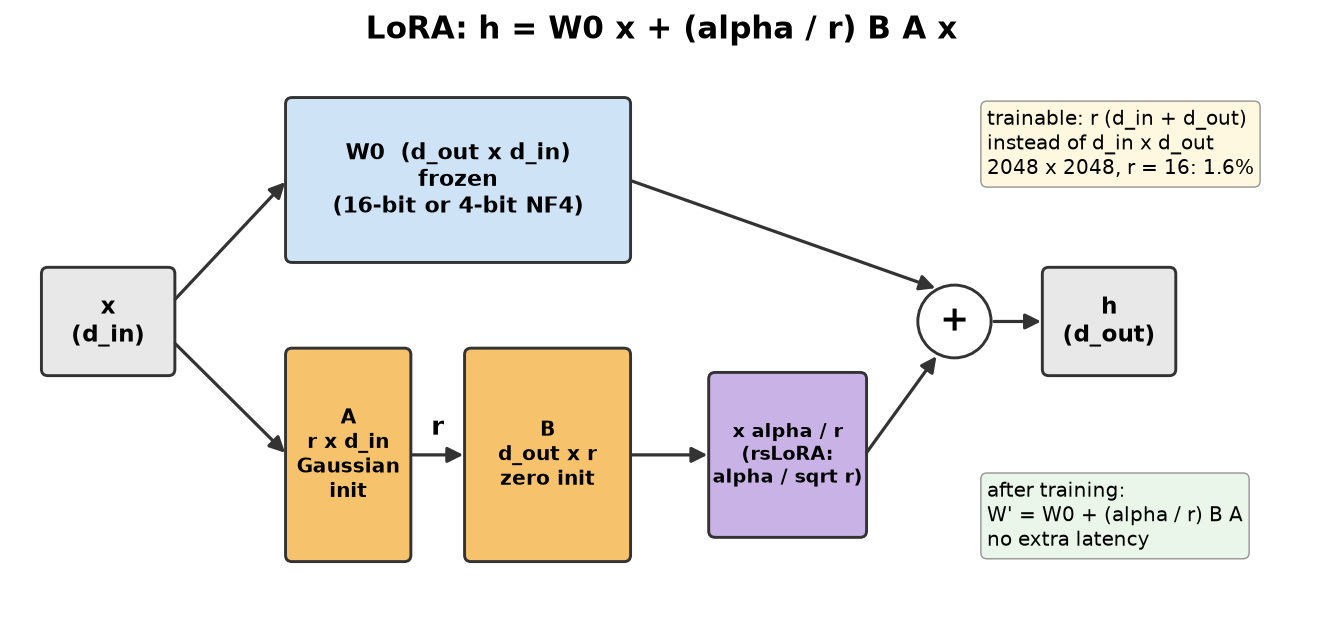

### 7.2. Инициализация

$A$ инициализируется случайно (в статье — гауссовым распределением), $B$ — нулями. Значит, в начале обучения $\Delta W = BA = 0$ и модель в точности совпадает с исходной ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Это важно: обучение начинается из хорошей точки, а не со случайного возмущения. Почему не обе нулями? Градиенты:

$$
\frac{\partial \mathcal{L}}{\partial B} = \frac{\alpha}{r} \frac{\partial \mathcal{L}}{\partial h} (A x)^\top, \qquad
\frac{\partial \mathcal{L}}{\partial A} = \frac{\alpha}{r} B^\top \frac{\partial \mathcal{L}}{\partial h} x^\top.
$$

При $A = 0$ и $B = 0$ оба градиента нулевые, и обучение не сдвинется с места. При $B = 0$, $A \neq 0$ на первом шаге меняется только $B$, а затем начинает расти и $A$. PEFT по умолчанию использует именно такую схему; есть и альтернативы (`init_lora_weights="pissa"`, `"olora"`, `"loftq"` и другие), которые инициализируют адаптер по сингулярному разложению $W_0$ или с учётом ошибки квантования ([документация PEFT](https://huggingface.co/docs/peft/main/en/developer_guides/lora)).

### 7.3. Слияние и отсутствие задержки

После обучения можно вычислить $W' = W_0 + \frac{\alpha}{r} B A$ и заменить слой обычным линейным слоем. Инференс идёт с той же скоростью, что у исходной модели: в отличие от адаптеров, LoRA не добавляет последовательных вычислений ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). В PEFT это `merge_and_unload()`; метод не изменяет модель на месте, а возвращает новую ([документация PEFT](https://huggingface.co/docs/peft/main/en/developer_guides/lora)).

Без слияния адаптер хранится отдельно, и это тоже преимущество: на одной базовой модели можно держать несколько адаптеров и переключать их между запросами. В практике три адаптера обучаются и оцениваются на одной загруженной модели.

Сливать адаптер с 4-битной моделью напрямую нельзя без потерь: сумма $W_0 + \Delta W$ не представима в NF4 без повторного квантования. Обычная практика — загрузить базовую модель в bf16, применить адаптер, слить и при необходимости заново квантовать результат для инференса.

### 7.4. Ранг r

Ранг определяет ёмкость адаптера. В статье LoRA на GPT-3 ранг 1–4 при адаптации $W_q$ и $W_v$ давал результат, сравнимый с большими рангами, а увеличение ранга не всегда помогало ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Исследование QLoRA также сообщает, что при LoRA на всех линейных слоях ранг слабо влияет на качество ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

Но это верно для задач, близких к предобучению (стиль, формат, следование инструкциям). Для задач, требующих много новых знаний (новый язык, программирование, математика), разница между LoRA и полным дообучением заметна: Biderman et al. показали, что полное дообучение находит изменения весов ранга в 10–100 раз выше, чем типичные конфигурации LoRA ([Biderman et al., 2024](https://arxiv.org/abs/2405.09673)).

Практическое правило: начинать с $r = 8$–16 для формата и узкой задачи, 32–64 для новой предметной области; проверять на валидации, а не увеличивать «на всякий случай».

### 7.5. Коэффициент α и масштаб

Множитель $\alpha / r$ задаёт масштаб добавки. Авторы LoRA выбирают $\alpha$ равным первому опробованному $r$ и не подбирают его: при Adam изменение $\alpha$ примерно эквивалентно изменению learning rate ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Деление на $r$ задумано, чтобы при смене ранга не нужно было заново подбирать гиперпараметры.

Kalajdzievski показал, что деление на $r$ слишком сильно: при больших рангах обучение замедляется, и выгода от большого ранга теряется. Он предложил rank-stabilized LoRA (rsLoRA) с масштабом $\alpha / \sqrt{r}$, при котором величина изменений остаётся стабильной при росте ранга ([Kalajdzievski, 2023](https://arxiv.org/abs/2312.03732)). В PEFT это флаг `use_rslora=True` ([документация PEFT](https://huggingface.co/docs/peft/main/en/developer_guides/lora)).

Интуиция. Пусть $A$ инициализирована со строками единичной нормы, $B$ обучается. Выход адаптера — сумма $r$ слагаемых $b_i (a_i^\top x)$. Если вклады независимы, норма суммы растёт как $\sqrt{r}$, а деление на $r$ уменьшает итоговый масштаб как $1/\sqrt{r}$. Деление на $\sqrt{r}$ компенсирует это ровно. В практике (раздел 3) мы обучаем LoRA разных рангов на одной задаче и видим эффект.

Типичные значения: $\alpha = 2r$ (16/32, как в нашей основной конфигурации) или $\alpha = r$. Документация Unsloth рекомендует $\alpha$ не меньше $r$ ([Unsloth](https://docs.unsloth.ai/basics/vision-fine-tuning)). В исследовании QLoRA использовались $r = 64$, $\alpha = 16$ ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

### 7.6. Целевые модули

В трансформере линейных слоёв несколько типов: в блоке внимания $W_q, W_k, W_v, W_o$, в MLP (SwiGLU) — `gate_proj`, `up_proj`, `down_proj`. Исходная статья адаптировала только $W_q$ и $W_v$. QLoRA показала, что для совпадения с качеством полного дообучения в 16 бит LoRA нужна на всех линейных слоях трансформерного блока, и это важнее выбора ранга ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

Для VLM есть третья ось — в какой части модели:

| Целевые модули | Доля параметров (SmolVLM-256M, r=16) | Когда |
|---|---|---|
| q, v языковой модели | около 0.1% | минимальная адаптация формата |
| все линейные слои языковой модели | около 1.9% | стандарт для SFT |
| + проектор | чуть больше | при сильном сдвиге визуального домена |
| + визуальный энкодер | значительно больше | энкодер не различает нужные признаки |

В PEFT целевые модули задаются списком суффиксов имён (`["q_proj", "v_proj"]`), регулярным выражением по полному имени или `"all-linear"`. Важная тонкость: в VLM слои с именами `q_proj` есть и в визуальном энкодере, и в языковой модели, и список суффиксов захватит оба. Чтобы ограничиться языковой моделью, нужно регулярное выражение по пути модуля (так сделано в практике) или флаги инструмента.

Параметр `modules_to_save` делает полностью обучаемыми указанные модули, например `lm_head` и `embed_tokens`, — это нужно, если в словарь добавлены новые токены ([документация PEFT](https://huggingface.co/docs/peft/main/en/developer_guides/lora)). Полная копия эмбеддингов большой модели — сотни миллионов параметров, поэтому без необходимости этого не делают.

### 7.7. Другие гиперпараметры

- Learning rate. Для LoRA он выше, чем для полного дообучения: типично 1e-4 – 3e-4 против 1e-5 – 2e-5. Примеры LLaMA-Factory для Qwen3 и Qwen3-VL используют 1e-4 ([LLaMA-Factory, examples](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_sft.yaml)).
- `lora_dropout` — dropout на входе адаптера, 0–0.1. На малых данных помогает; Unsloth рекомендует 0 ради скорости.
- Число эпох: 1–3. Больше эпох на малых данных — путь к переобучению и забыванию.
- Расписание: линейный warmup 3–10% шагов, затем косинусное убывание.

### 7.8. Варианты LoRA

- DoRA раскладывает вес на модуль и направление $W = m \cdot V / \lVert V \rVert$, направление адаптирует LoRA, модуль — отдельный вектор; это приближает поведение к полному дообучению ценой дополнительных вычислений ([Liu et al., 2024](https://arxiv.org/abs/2402.09353)). В PEFT — `use_dora=True`.
- rsLoRA — масштаб $\alpha / \sqrt{r}$ (раздел 7.5).
- PiSSA, OLoRA — инициализация главными сингулярными компонентами $W_0$.
- LoftQ — инициализация, компенсирующая ошибку квантования базовой модели.

## 8. Квантование и QLoRA

### 8.1. Идея QLoRA

LoRA убирает градиенты и состояния оптимизатора для замороженных весов, но сами веса по-прежнему занимают 2 байта на параметр. QLoRA хранит замороженную модель в 4 битах, а вычисления ведёт в bf16: перед умножением блок весов деквантуется, градиент через него проходит к LoRA-адаптерам, которые хранятся в 16 или 32 битах ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)). Для одного слоя:

$$
Y = X \cdot \mathrm{doubleDequant}\!\left(c_1^{\mathrm{FP32}}, c_2^{k\text{-bit}}, W^{\mathrm{NF4}}\right) + X L_1 L_2.
$$

Результат статьи: дообучение 65B-модели на одной GPU с 48 ГБ вместо более чем 780 ГБ при полном дообучении в 16 битах, без потери качества. Модель Guanaco, полученная так за 24 часа на одной GPU, достигла 99.3% уровня ChatGPT на бенчмарке Vicuna ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

QLoRA состоит из трёх приёмов: тип данных NF4, double quantization и paged optimizers.

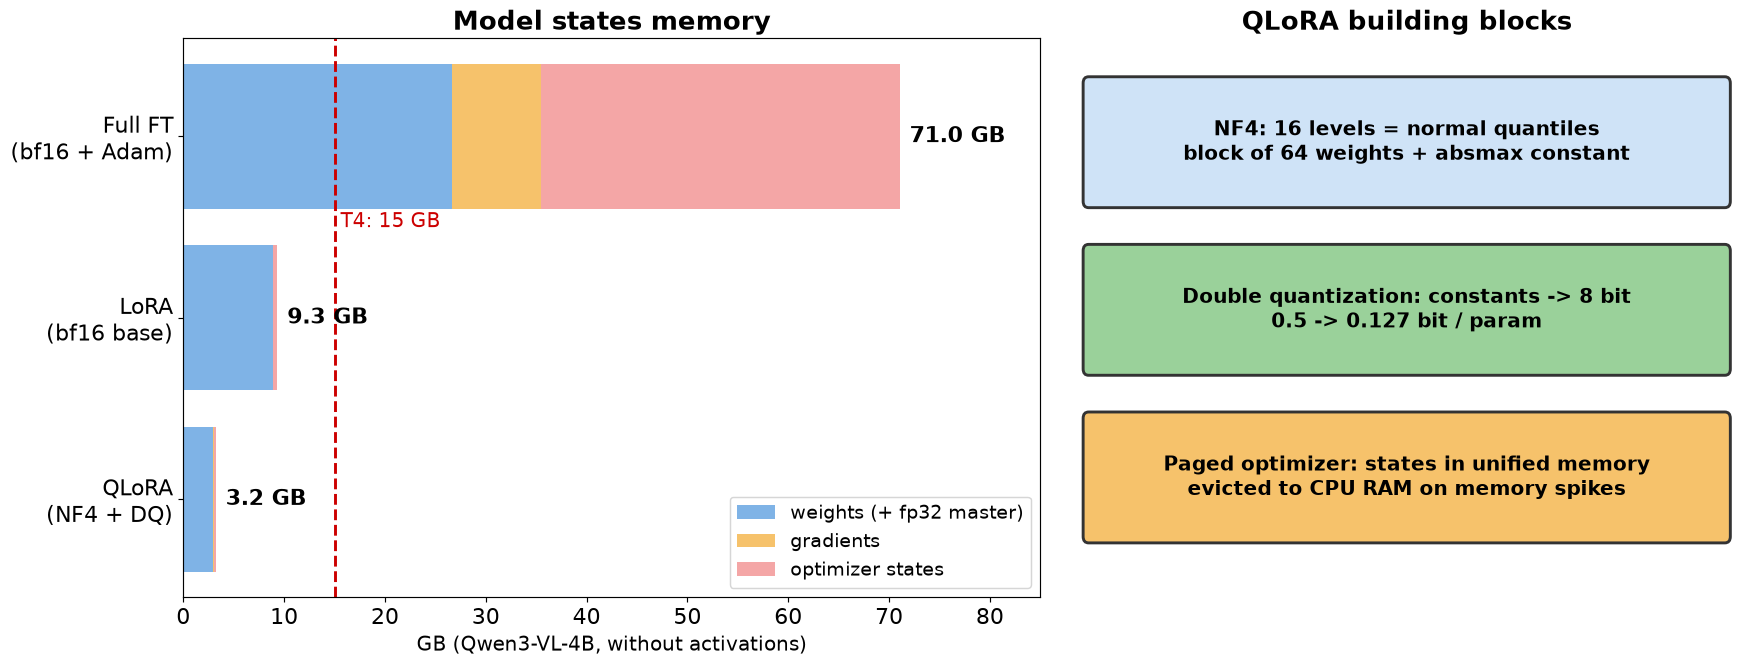

### 8.2. Блочное квантование

Квантование отображает вещественные веса в небольшой набор уровней. Блочное квантование с масштабом absmax: веса делятся на блоки по 64 значения, для каждого блока хранится константа $c = \max_i |w_i|$, а каждое значение заменяется индексом ближайшего уровня:

$$
q_i = \arg\min_j \left| \frac{w_i}{c} - v_j \right|, \qquad \hat w_i = c \cdot v_{q_i}.
$$

Маленький блок нужен, чтобы выброс в одном месте матрицы не «растягивал» шкалу для всех остальных весов. Но за каждый блок хранится константа, и при fp32-константах и блоке 64 это 32/64 = 0.5 бита на параметр сверху ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

### 8.3. NF4: NormalFloat

Веса предобученных сетей распределены примерно нормально с нулевым средним. Если уровни $v_j$ расположить равномерно (как в int4), то в центре, где сосредоточено большинство весов, уровней мало, а на хвостах — с избытком. NormalFloat выбирает уровни как квантили стандартного нормального распределения, так что в каждый интервал квантования попадает одинаковое ожидаемое число значений. Для нормальных данных такой тип информационно-теоретически оптимален ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

Тонкость: симметричный набор из 16 квантилей не содержит точного нуля, а нули важны (паддинг, обнулённые веса). Поэтому NF4 строится асимметрично: 8 квантилей для положительной части и 7 для отрицательной плюс точный 0, итого 16 уровней, нормированных в $[-1, 1]$. В практике мы строим эти уровни через обратную функцию нормального распределения, сравниваем с таблицей bitsandbytes и измеряем ошибку квантования настоящего веса модели в NF4 и в int4.

### 8.4. Double quantization

Double quantization квантует сами константы $c$. Константы первого уровня (fp32, по одной на 64 веса) делятся на блоки по 256, центрируются вычитанием среднего и квантуются в 8 бит. Расход на константы падает с 0.5 до $8/64 + 32/(64 \cdot 256) \approx 0.127$ бита на параметр, то есть на 0.373 бита, — около 3 ГБ для 65B-модели ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)). Итого NF4 с double quantization стоит около 4.127 бита на параметр.

Пример для 4B-модели: 4 · 10⁹ × 0.373 / 8 ≈ 190 МБ экономии. Немного по сравнению с 2 ГБ весов, но на T4 с 15 ГБ это ещё один-два шага увеличения длины последовательности.

### 8.5. Paged optimizers

Даже при малом среднем расходе памяти обучение иногда даёт пики: длинная последовательность, большая картинка, пересчёт при gradient checkpointing. Paged optimizers используют unified memory NVIDIA: состояния оптимизатора выделяются в страничной памяти и автоматически вытесняются в RAM процессора, когда GPU не хватает памяти, и подгружаются обратно в момент шага оптимизатора ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)). Это не уменьшает средний расход, но превращает редкий OOM в редкое замедление. По измерениям авторов, при батче 16 скорость paged-оптимизаторов для 65B-модели на 48 ГБ не отличалась от обычных.

В Transformers это `optim="paged_adamw_8bit"` или `"paged_adamw_32bit"`, в bitsandbytes — класс `bnb.optim.PagedAdamW8bit`.

### 8.6. 8-bit оптимизаторы

Adam хранит два момента на каждый обучаемый параметр, 8 байт в fp32. 8-bit оптимизаторы квантуют эти состояния блочно с динамической шкалой ([Dettmers et al., 2021](https://arxiv.org/abs/2110.02861)). По документации bitsandbytes это сокращает память под состояния на 75% без потери точности, но выигрыш пропорционален числу обучаемых параметров ([bitsandbytes](https://huggingface.co/docs/bitsandbytes/main/en/optimizers)). При LoRA обучаемых параметров мало, поэтому 8-bit Adam экономит десятки мегабайт, а не гигабайты; основной эффект в QLoRA дают 4-битные веса.

### 8.7. Настройка в Transformers

```python
from transformers import BitsAndBytesConfig
bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",            # NF4 вместо fp4
    bnb_4bit_use_double_quant=True,       # double quantization
    bnb_4bit_compute_dtype=torch.bfloat16,  # T4: torch.float16
    llm_int8_skip_modules=["visual", "lm_head"],  # не квантовать визуальную часть и выходной слой
)
model = AutoModelForImageTextToText.from_pretrained(model_id, quantization_config=bnb, device_map={"": 0})
```

Что не квантуют: визуальный энкодер (он мал, а ошибки квантования в нём портят все визуальные токены), `lm_head` и нормализации. Функция `prepare_model_for_kbit_training` из PEFT переводит все неквантованные параметры в fp32 и включает gradient checkpointing. Для VLM на T4 это может быть невыгодно: визуальный энкодер и эмбеддинги в fp32 занимают несколько гигабайт, поэтому в практике мы включаем checkpointing вручную и оставляем неквантованные части в fp16.

Ограничения QLoRA: bitsandbytes 4-bit требует GPU; шаг обучения медленнее, чем в bf16-LoRA, из-за деквантования; слияние адаптера требует перезагрузки базовой модели в 16 битах (раздел 7.3).

## 9. Бюджет памяти обучения

### 9.1. Из чего складывается память

| Компонент | Полное дообучение | LoRA | QLoRA |
|---|---|---|---|
| Веса модели | 2P (bf16) + 4P (fp32-копия) | 2P | ≈ 0.52P (NF4 + DQ) |
| Градиенты | 2P | только адаптер | только адаптер |
| Состояния Adam | 8P | только адаптер | только адаптер (8-bit — вчетверо меньше) |
| Активации | зависят от $s, b, h, L$ | так же | так же |
| Временные буферы, фрагментация | 0.5–2 ГБ | так же | так же |

$P$ — число параметров, значения в байтах. Видно, что LoRA убирает три верхние строки почти целиком, QLoRA сжимает первую ещё в 4 раза, а строка активаций не зависит от метода и при длинных последовательностях становится главной. Для VLM длина последовательности определяется в основном визуальными токенами.

### 9.2. Активации

Korthikanti et al. вывели оценку памяти активаций одного слоя трансформера в 16 битах ([Korthikanti et al., 2022](https://arxiv.org/abs/2205.05198)):

$$
M_{\text{layer}} = s\,b\,h\left(34 + \frac{5\,a\,s}{h}\right) \text{ байт}.
$$

Слагаемое 34 — входы линейных слоёв, нормализаций, нелинейностей и маски dropout; слагаемое $5as/h$ — матрица внимания $s \times s$ для каждой головы (softmax и dropout). Оно растёт квадратично по длине, и при $s$ в несколько тысяч становится главным.

Пример. Qwen3-VL-4B: $L = 36$, $h = 2560$, $a = 32$ (числа берутся из конфигурации модели в практике). Изображение 512×512 даёт 256 визуальных токенов, плюс 100 токенов текста, $s \approx 360$, $b = 1$:

$$
M \approx 36 \cdot 360 \cdot 2560 \cdot (34 + 5 \cdot 32 \cdot 360 / 2560) \approx 36 \cdot 0.92\cdot 10^6 \cdot 56.5 \approx 1.9 \text{ ГБ}.
$$

Изображение 1024×1024 даёт 1024 токена, $s \approx 1100$, и оценка вырастает примерно до 10 ГБ — уже больше, чем остаётся на T4 после загрузки модели. Отсюда три способа экономии: уменьшить $b$ (раздел 10), не хранить активации (раздел 11) и не хранить матрицу внимания (раздел 12). Самый простой способ — уменьшить разрешение изображений.

## 10. Batch size 1 и gradient accumulation

Память на активации пропорциональна размеру микробатча $b$. Минимум — $b = 1$: в этом случае ещё и не нужен паддинг, все токены полезные. Но градиент по одному примеру шумный, а для стабильного обучения нужен эффективный батч 8–64 примера.

Gradient accumulation решает это так: выполнить $K$ прямых и обратных проходов по микробатчам, складывая градиенты, и только потом сделать шаг оптимизатора:

$$
g = \sum_{k=1}^{K} \nabla_\theta \mathcal{L}_k, \qquad \theta \leftarrow \theta - \eta \cdot \mathrm{Adam}(g).
$$

Эффективный батч равен $b \cdot K \cdot n_{\text{GPU}}$. Память — как для микробатча, время шага — в $K$ раз больше.

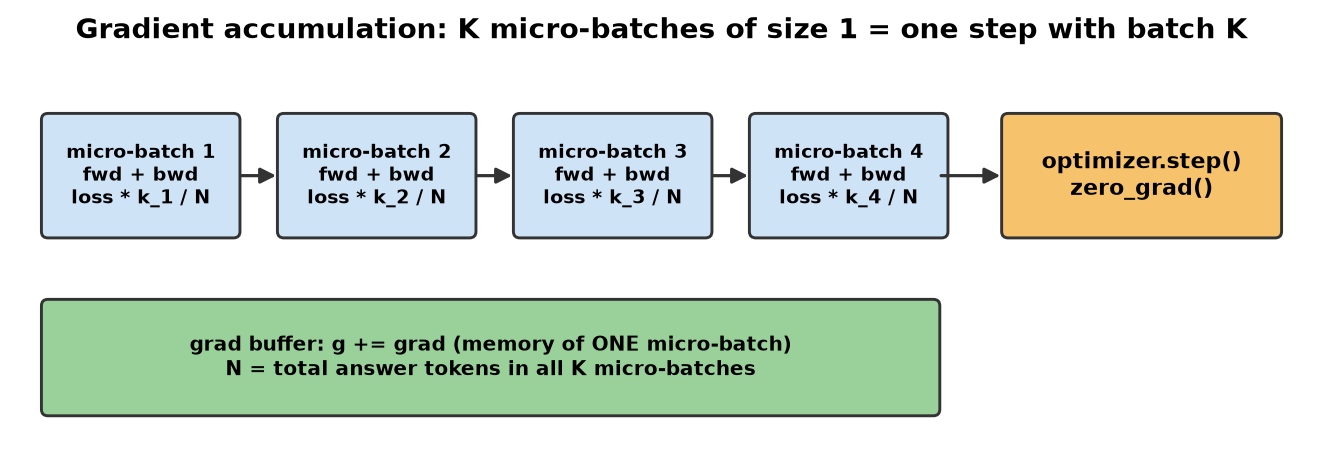

Чтобы накопленный градиент совпал с градиентом большого батча, каждое слагаемое нужно нормировать на общее число токенов в loss за весь шаг, а не на число токенов микробатча (раздел 5.3). В собственном цикле:

```python
n_tok = sum((e["labels"][:, 1:] != -100).sum() for e in micro_batches)   # токены всего шага
for e in micro_batches:
    out = model(**e)
    k = (e["labels"][:, 1:] != -100).sum()
    (out.loss * k / n_tok).backward()        # out.loss — среднее по k токенам микробатча
optimizer.step(); optimizer.zero_grad()
```

Ещё два отличия accumulation от большого батча: BatchNorm видит только микробатч (в трансформерах его нет, там LayerNorm/RMSNorm), а dropout и порядок данных дают немного другую траекторию. Для трансформеров с правильной нормировкой разница несущественна.

## 11. Gradient checkpointing

При обычном обучении все промежуточные активации прямого прохода хранятся до обратного прохода. Gradient checkpointing (activation recomputation) хранит только входы некоторых блоков — «контрольные точки», — а остальное пересчитывает на обратном проходе. Chen et al. показали, что так можно обучать $n$-слойную сеть с памятью $O(\sqrt{n})$ ценой одного дополнительного прямого прохода; в их эксперименте память 1000-слойной ResNet снизилась с 48 до 7 ГБ при росте времени примерно на 30% ([Chen et al., 2016](https://arxiv.org/abs/1604.06174)).

В Transformers контрольная точка ставится на вход каждого слоя декодера. Хранится $2sbh$ байт на слой вместо $sbh(34 + 5as/h)$, плюс активации одного слоя в момент его пересчёта. Цена — повторный прямой проход: шаг дольше примерно на 20–40%.

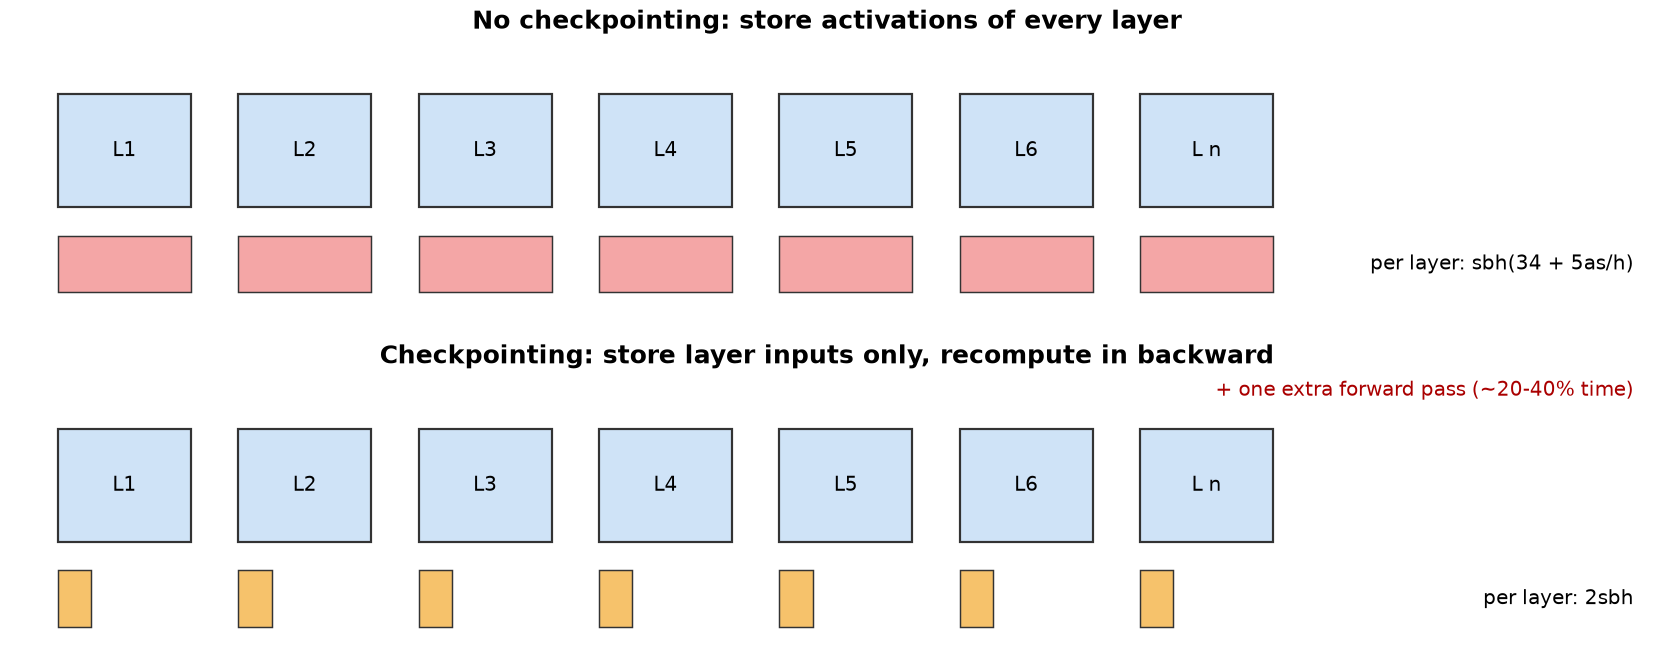

Две реализации в PyTorch:

- reentrant (старая, `use_reentrant=True`): требует, чтобы вход блока имел `requires_grad=True`. При замороженной модели вход первого слоя — эмбеддинги без градиента, и градиенты к LoRA не проходят без хака `enable_input_require_grads()`;
- non-reentrant (`use_reentrant=False`): основана на хуках сохранённых тензоров, работает с замороженными входами, рекомендуется сейчас.

```python
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.config.use_cache = False   # KV-кэш при обучении не нужен
```

Существует и селективный пересчёт: хранить дешёвые в памяти, но дорогие в вычислении тензоры, и пересчитывать только внимание. Korthikanti et al. показали, что вместе с параллелизмом последовательности он сокращает память активаций в 5 раз и почти убирает накладные расходы пересчёта ([Korthikanti et al., 2022](https://arxiv.org/abs/2205.05198)).

## 12. Memory-efficient attention и смешанная точность

### 12.1. Внимание без матрицы s × s

Наивная реализация внимания строит матрицу $S = QK^\top / \sqrt{d}$ размера $s \times s$ для каждой головы, применяет softmax и умножает на $V$. Для обратного прохода хранится матрица вероятностей — та самая квадратичная часть $5as^2b$.

Rabe и Staats показали, что внимание можно считать по блокам ключей, поддерживая текущий максимум и сумму экспонент (online softmax), с памятью $O(\sqrt{n})$ или $O(1)$ на запрос вместо $O(n)$; при длине 16384 это сократило накладные расходы по памяти в 59 раз для инференса и в 32 раза для обучения ([Rabe, Staats, 2021](https://arxiv.org/abs/2112.05682)). FlashAttention добавил к этому учёт иерархии памяти GPU: блоки $Q, K, V$ загружаются в быструю SRAM, результат пишется в HBM один раз, а на обратном проходе матрица внимания пересчитывается по сохранённым статистикам softmax. Это точное, а не приближённое внимание; оно дало ускорение на 15% для BERT-large и в 3 раза для GPT-2 при длине 1K ([Dao et al., 2022](https://arxiv.org/abs/2205.14135)).

В PyTorch все варианты доступны через `torch.nn.functional.scaled_dot_product_attention` (SDPA). Функция выбирает один из бэкендов: FlashAttention-2, memory-efficient attention или эталонная реализация на C++ ([PyTorch](https://docs.pytorch.org/docs/2.12/generated/torch.nn.functional.scaled_dot_product_attention.html)). В Transformers SDPA — реализация по умолчанию (`attn_implementation="sdpa"`); вариант `"flash_attention_2"` требует отдельного пакета `flash-attn`.

Важно для Colab: FlashAttention-2 поддерживает GPU Ampere, Ada и Hopper (A100, RTX 3090/4090, H100), а для Turing (T4) есть только отдельный репозиторий с частью функций ([flash-attention](https://github.com/Dao-AILab/flash-attention)). На T4 используйте SDPA: она выберет memory-efficient бэкенд, который работает и на Turing.

### 12.2. Смешанная точность

| Формат | Биты экспоненты/мантиссы | Диапазон | Где |
|---|---|---|---|
| fp32 | 8 / 23 | ~1e±38 | master-веса, состояния оптимизатора, LoRA-адаптеры |
| bf16 | 8 / 7 | ~1e±38 | вычисления на Ampere и новее |
| fp16 | 5 / 10 | ~6.5e4 | вычисления на T4 и V100 |

bf16 имеет тот же диапазон, что fp32, и обычно обучается без дополнительных мер. У fp16 узкий диапазон: малые градиенты обнуляются (underflow), большие активации переполняются. Поэтому с fp16 нужен loss scaling: loss умножается на большой коэффициент перед backward, градиенты делятся на него перед шагом, а коэффициент уменьшается, если появились inf/NaN (`torch.amp.GradScaler`). T4 не поддерживает bf16 аппаратно, поэтому практика на T4 использует fp16 + GradScaler, а сами LoRA-веса держит в fp32.

### 12.3. Сводка приёмов

| Приём | Что экономит | Цена |
|---|---|---|
| LoRA | градиенты и состояния оптимизатора | ёмкость адаптации |
| 4-bit NF4 + DQ | веса (в 4 раза) | скорость, слияние сложнее |
| 8-bit Adam | состояния оптимизатора (в 4 раза) | почти нет |
| paged optimizer | пики памяти | замедление при пейджинге |
| batch size 1 + accumulation | активации (в b раз) | время, недогруженный GPU |
| gradient checkpointing | активации (в разы) | +20–40% времени |
| SDPA / FlashAttention | квадратичная часть активаций | нет, обычно ускоряет |
| меньше пикселей | длина последовательности | качество на мелких деталях |

## 13. Инструменты

### 13.1. Transformers + PEFT

Базовый уровень, на котором написана практика. `AutoModelForImageTextToText` загружает VLM, `AutoProcessor` — процессор с шаблоном, `peft.LoraConfig` и `get_peft_model` подключают адаптер. Обучение — либо собственный цикл (полный контроль, как в практике), либо `Trainer` с `TrainingArguments`, где все приёмы экономии памяти включаются флагами:

```python
TrainingArguments(per_device_train_batch_size=1, gradient_accumulation_steps=8,
                  gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
                  optim="paged_adamw_8bit", learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=30,
                  bf16=True, num_train_epochs=1, logging_steps=10, seed=0, data_seed=0, report_to="none",
                  remove_unused_columns=False)   # для VLM: иначе Trainer удалит pixel_values
```

### 13.2. TRL

`SFTTrainer` из TRL — надстройка над `Trainer` для SFT. Для VLM он принимает датасет со столбцами `messages` и `images`, сам применяет шаблон и строит маску. `assistant_only_loss=True` включает loss только по ответам ассистента (нужен шаблон с разметкой `{% generation %}`), а для датасетов в формате prompt–completion loss по умолчанию считается только по completion. Для VLM документация рекомендует `max_length=None`, чтобы обрезка не удалила визуальные токены ([TRL SFTTrainer](https://huggingface.co/docs/trl/main/en/sft_trainer)).

### 13.3. LLaMA-Factory

LLaMA-Factory — фреймворк, объединяющий множество методов эффективного дообучения для более чем 100 моделей, с веб-интерфейсом LlamaBoard ([Zheng et al., 2024](https://arxiv.org/abs/2403.13372)). В репозитории перечислены SFT (в том числе мультимодальный), reward modeling, PPO, DPO, KTO, ORPO и режимы full, freeze, LoRA и QLoRA с 2–8-битным квантованием ([LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)). Всё обучение описывается YAML-конфигом и запускается одной командой:

```bash
llamafactory-cli train examples/train_lora/qwen3vl_lora_sft.yaml
```

Датасет — JSON в формате sharegpt со столбцом `images`; число тегов `<image>` в репликах должно совпадать с числом изображений. Датасет регистрируется в `data/dataset_info.json` с указанием `formatting: sharegpt` и соответствия столбцов ([LLaMA-Factory, data/README](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md)). Шаблон для Qwen3-VL называется `qwen3_vl` (вариант без рассуждений — `qwen3_vl_nothink`). В практике (раздел 10) мы экспортируем наши данные и конфиг в этот формат.

Ключи конфига, соответствующие темам лекции: `finetuning_type: lora`, `lora_rank`, `lora_alpha`, `lora_target: all`, `quantization_bit: 4`, `quantization_method: bnb`, `double_quantization`, `per_device_train_batch_size`, `gradient_accumulation_steps`, `image_max_pixels`, `template`, `cutoff_len`.

### 13.4. Unsloth

Unsloth переписывает ключевые операции (внимание, RoPE, кросс-энтропию, LoRA-проекции) собственными ядрами и обещает обучение в 2 раза быстрее с использованием на 70% меньше видеопамяти без потери точности ([Unsloth](https://github.com/unslothai/unsloth)). Для VLM есть класс `FastVisionModel`, где целевые модули выбираются флагами по частям модели:

```python
from unsloth import FastVisionModel
model, tokenizer = FastVisionModel.from_pretrained("unsloth/Qwen3-VL-4B-Instruct-unsloth-bnb-4bit",
                                                   load_in_4bit=True, use_gradient_checkpointing="unsloth")
model = FastVisionModel.get_peft_model(model,
    finetune_vision_layers=False, finetune_language_layers=True,
    finetune_attention_modules=True, finetune_mlp_modules=True,
    r=16, lora_alpha=16, lora_dropout=0, bias="none", random_state=3407, use_rslora=False)
```

Аргументы `get_peft_model` взяты из документации Unsloth ([Unsloth: Vision Fine-tuning](https://docs.unsloth.ai/basics/vision-fine-tuning)); там же — формат данных: messages, где часть `{"type": "image", "image": ...}` содержит само изображение. Загрузка и обучение повторяют официальный скрипт Unsloth для Qwen3-VL: `FastVisionModel.from_pretrained(..., load_in_4bit=True, use_gradient_checkpointing="unsloth")`, затем `SFTTrainer` из TRL с коллатором `UnslothVisionDataCollator(model, tokenizer, train_on_responses_only=True, instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")` — это и есть маска loss по ответам, построенная поиском маркеров ролей ([unsloth/jobs, sft-qwen3-vl.py](https://huggingface.co/datasets/unsloth/jobs/blob/main/sft-qwen3-vl.py)). Заявления о скорости — собственные бенчмарки разработчиков; проверяйте их на своей задаче.

### 13.5. Как выбрать

| Нужно | Инструмент |
|---|---|
| понять, что происходит, нестандартный loss или цикл | Transformers + PEFT, свой цикл |
| стандартный SFT с минимумом кода | TRL `SFTTrainer` |
| много экспериментов по конфигам, без кода, DPO/PPO | LLaMA-Factory |
| максимум скорости на одной GPU | Unsloth |

Все четыре используют PEFT-совместимый формат адаптеров, поэтому адаптер, обученный в одном инструменте, загружается через `PeftModel.from_pretrained` в другом.

## 14. Воспроизводимость конфигов

Эксперимент воспроизводим, если по сохранённым артефактам можно повторить его и получить те же числа (или в пределах известного разброса). Для дообучения это означает фиксацию:

1. Модели: идентификатор и ревизия (commit hash) на Hub, а не просто имя: веса и шаблон могут обновиться.
2. Кода и библиотек: версии torch, transformers, peft, bitsandbytes, trl; commit своего кода.
3. Данных: хеш файла датасета или манифест с хешами примеров; версия генератора и сид для синтетики.
4. Гиперпараметров: полный конфиг (LoRA, оптимизатор, расписание, длины, разрешение изображений), сохранённый рядом с адаптером.
5. Случайности: сиды Python, NumPy, PyTorch, порядок данных. Полный детерминизм на GPU требует `torch.use_deterministic_algorithms(True)` и замедляет обучение; обычно достаточно зафиксировать сиды и повторить 2–3 запуска, чтобы знать разброс.
6. Результатов: хеш файла адаптера и таблица метрик с указанием наборов и их версий.

Конфиг удобно хранить в YAML: его читают LLaMA-Factory, Hydra, Axolotl. В практике мы собираем такой конфиг автоматически из переменных блокнота.

Разброс между сидами — не формальность. На малых данных разные сиды LoRA могут давать разницу в несколько пунктов; если сравнение двух конфигураций меньше этого разброса, вывод делать нельзя. Рисунок 2 статьи QLoRA показывает именно такой разброс по сидам для LLaMA-7B на Alpaca ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)).

## 15. Оценка после адаптации: ID и OOD

### 15.1. Три вопроса оценки

1. Стала ли модель лучше на целевой задаче? Отложенный тест из того же распределения (ID).
2. Устойчив ли выигрыш к сдвигу? OOD-наборы, отличающиеся по одной контролируемой оси.
3. Что модель потеряла? Замеры общих способностей до и после (раздел 16).

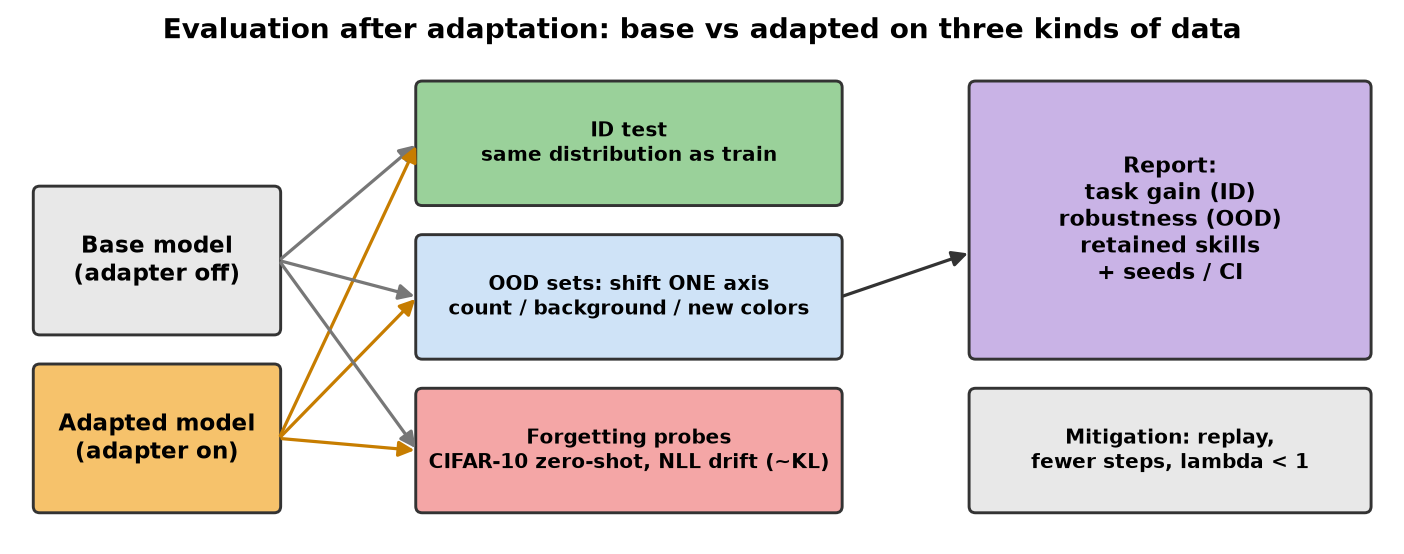

### 15.2. Как строить OOD-наборы

Хороший OOD-набор меняет ровно одну ось, чтобы падение можно было интерпретировать:

| Ось сдвига | Пример для нашей задачи | Пример в реальном проекте |
|---|---|---|
| ковариатный (вход) | текстурный фон | другая камера, освещение, сканер |
| экстраполяция по параметру | 5–6 фигур при обучении на 1–4 | более длинные документы, больше объектов |
| новые значения атрибута | новые цвета | новые классы дефектов, новые бренды |
| формат вопроса | перефразированная инструкция | пользователи пишут иначе, чем в данных |
| источник | реальные фото вместо синтетики | другой клиент, другая страна |

Сдвиг по новым значениям атрибута особенно показателен: если модель выучила «словарь» ответов (четыре цвета), она будет подставлять ближайшее знакомое слово вместо нового цвета, даже если базовая модель этот цвет различает.

### 15.3. Почему OOD важен именно для дообучения

Kumar et al. показали, что полное дообучение искажает предобученные признаки: на ID оно в среднем лучше linear probing примерно на 2%, а на OOD хуже примерно на 7%. Предложенная ими схема LP-FT (сначала обучить голову, затем всё) сохраняет признаки лучше ([Kumar et al., 2022](https://arxiv.org/abs/2202.10054)). Для LoRA эффект слабее, но качественно тот же: адаптация «подстраивает» модель под распределение обучения.

### 15.4. Метрики для структурированных ответов

Метрика должна разделять типы ошибок, иначе непонятно, что чинить:

- валидность формата (парсится ли ответ, есть ли обязательные поля);
- точное совпадение (строгая метрика для продакшена);
- частичное совпадение по полям или объектам (F1), чтобы видеть прогресс до exact match;
- отдельные метрики по полям (здесь — счёт).

Малые выборки дают большой разброс: при 24 примерах доверительный интервал для доли 0.5 — примерно ±0.2. Для выводов используйте не меньше нескольких сотен примеров на набор, а в учебном CPU-режиме смотрите на качественную картину.

## 16. Катастрофическое забывание: измерение и защита

### 16.1. Что такое забывание

Катастрофическое забывание — потеря ранее приобретённых способностей при обучении новой задаче. Для LLM при continual instruction tuning оно наблюдалось у моделей от 1B до 7B параметров, причём с ростом размера в этом диапазоне забывание усиливалось ([Luo et al., 2023](https://arxiv.org/abs/2308.08747)). Для мультимодальных моделей Zhai et al. показали, что ранняя стадия дообучения на одной задаче может даже улучшать другие, а дальнейшее дообучение ведёт к галлюцинациям и потере обобщения ([Zhai et al., 2023](https://arxiv.org/abs/2309.10313)).

Проявления у VLM:

- схлопывание формата: на любой вопрос модель отвечает в формате задачи («Describe this image» → JSON со списком фигур);
- потеря знаний: хуже классифицирует, хуже читает текст, хуже отвечает на общие вопросы;
- рост галлюцинаций: модель «видит» объекты из словаря задачи там, где их нет;
- поломка следования инструкциям: игнорирует просьбу ответить одним словом.

### 16.2. Как измерять

1. Набор «старых» задач, на которых модель не обучалась: общий VQA, классификация, OCR. Замер до и после на одних и тех же примерах. В практике — zero-shot CIFAR-10.
2. Дрейф распределения: NLL собственных ответов базовой модели на общих вопросах. Если $y \sim p_{\text{base}}(\cdot \mid x)$, то
$$
\mathbb{E}_y\left[\log p_{\text{base}}(y \mid x) - \log p_{\text{new}}(y \mid x)\right] = \mathrm{KL}\left(p_{\text{base}} \,\|\, p_{\text{new}}\right),
$$
то есть рост NLL на ответах базовой модели — оценка KL-дивергенции. Метрика не требует разметки и чувствительна даже к небольшим изменениям. Строго равенство выполняется, когда ответы $y$ сэмплированы из базовой модели. В практике ответы получены жадным декодированием и их немного, поэтому величина — приближённая оценка: она может слегка уйти в минус, если адаптер случайно повысил вероятность именно этих ответов. Значимы разница между конфигурациями и порядок величины, а не знак малых значений.
3. Качественная проверка: несколько общих вопросов до и после, глазами.

### 16.3. Как защищаться

| Способ | Идея | Цена |
|---|---|---|
| PEFT вместо full FT | малая ёмкость изменения | ниже потолок качества на задаче |
| Меньше шагов, меньше lr | меньше уход от исходных весов | возможный недообучение |
| Replay | подмешать общие данные (или ответы самой базовой модели) | время обучения, нужны данные |
| Регуляризация к исходным весам | штраф за отклонение, например EWC с весами по информации Фишера ([Kirkpatrick et al., 2017](https://arxiv.org/abs/1612.00796)) | вычисление важностей |
| Интерполяция весов | $W_0 + \lambda \Delta W$, $\lambda \in [0, 1]$ | подбор $\lambda$ |
| Отдельные адаптеры | адаптер включается только для своей задачи | нужна маршрутизация запросов |

Biderman et al. сравнили LoRA и полное дообучение: LoRA учит меньше, но и забывает меньше, и это сохранение исходных способностей сильнее, чем у стандартных регуляризаторов вроде weight decay и dropout ([Biderman et al., 2024](https://arxiv.org/abs/2405.09673)).

Интерполяция весов — идея WiSE-FT: усреднить веса исходной и дообученной моделей. Это дало прирост 4–6 п.п. точности при сдвиге распределения при сохранении или улучшении качества на исходном распределении ([Wortsman et al., 2022](https://arxiv.org/abs/2109.01903)). Для LoRA интерполяция бесплатна: достаточно умножить масштаб адаптера на $\lambda$. В практике мы строим кривую «качество задачи — сохранение общих способностей» по $\lambda$.

Replay в варианте self-distillation: базовая модель генерирует ответы на общие вопросы, и эти пары подмешиваются к обучающим данным. Модель учится сохранять своё же поведение на общих запросах. Внешние данные не нужны, и стиль ответов не меняется.

Отдельные адаптеры — самый надёжный способ: если адаптер подключается только к запросам своей задачи, забывание на других запросах равно нулю. Цена — нужно решать, какой запрос к какой задаче относится.

## 17. Практические рекомендации и типичные ошибки

### 17.1. Рецепт для одной GPU T4

1. Базовая модель: 2–4B VLM (Qwen3-VL-2B/4B, SmolVLM-2B), загрузка в NF4 с double quantization, визуальный энкодер в 16 битах.
2. Данные: messages + изображения, 500–5000 примеров, отложенные val, test и OOD; ограничить разрешение (например, 512×512, что даёт 256 визуальных токенов у Qwen3-VL).
3. LoRA: все линейные слои языковой модели, $r = 16$, $\alpha = 16$–32, dropout 0.05.
4. Обучение: batch size 1, accumulation 8–16, lr 1e-4 – 2e-4, warmup 5–10%, косинус, 1–3 эпохи, fp16 + GradScaler, gradient checkpointing, SDPA, `paged_adamw_8bit`.
5. Маска loss только по ответам; проверить маску глазами на 2–3 примерах.
6. Оценка: base vs adapted на ID, OOD и наборе для забывания; 2–3 сида.
7. Сохранить адаптер, конфиг, версии, ревизию модели, хеши данных.

### 17.2. Частые ошибки

| Симптом | Вероятная причина |
|---|---|
| loss падает, а генерация не меняется | на инференсе другой шаблон или не подключён адаптер |
| модель не останавливается | токен конца реплики не в loss или не в данных |
| loss сразу почти 0 | ответ виден в промпте (утечка) или маска перевёрнута |
| loss NaN на T4 | fp16 без GradScaler или bf16 на Turing |
| градиенты LoRA нулевые | reentrant checkpointing без `enable_input_require_grads` или адаптер не активен |
| OOM на отдельных примерах | слишком большие изображения; ограничить max_pixels |
| ошибка числа image tokens | обрезка последовательности по `max_length` отрезала визуальные токены |
| отличное ID-качество, провал на новых данных | переобучение на узкое распределение; нужен OOD-набор и меньше шагов |
| на любой вопрос ответ в формате задачи | схлопывание формата; replay или отдельный адаптер |

# Часть II. Практика

В практике мы проходим весь цикл адаптации VLM под узкую задачу: от подготовки данных в формате диалога до оценки забывания.

Задача — структурированное описание сцены. На синтетическом изображении 1–4 фигуры (круг, квадрат, треугольник) четырёх цветов. Модель должна вернуть JSON с числом фигур и их списком слева направо, например `{"count": 2, "objects": ["red circle", "blue square"]}`. Задача выбрана намеренно:

- данные генерируются кодом, поэтому эталон известен точно, а выборку любого размера можно получить за секунды;
- легко построить контролируемые OOD-сдвиги: больше фигур, чем в обучении, текстурный фон, новые цвета;
- базовая модель решает задачу плохо, и эффект дообучения хорошо виден даже после нескольких минут обучения на CPU;
- строгий формат ответа — типичная причина дообучения VLM в реальных проектах (извлечение полей из документов, разметка, агентные сценарии).

| Раздел | Что делаем |
|---|---|
| 0. Установка | версии, режим запуска, выбор модели |
| 1. Данные | генератор сцен, ID- и OOD-наборы |
| 2. SFT-формат | messages, chat template, визуальные токены, маска loss |
| 3. LoRA с нуля | реализация, слияние, число параметров, масштаб α/r и α/√r |
| 4. Квантование | NF4 и double quantization на настоящих весах |
| 5. Базовая модель | zero-shot качество и замеры для оценки забывания |
| 6. PEFT-модель и память | LoRA-адаптер, калькулятор памяти, gradient accumulation, checkpointing, attention |
| 7. Обучение | три конфигурации LoRA: основная, малая, с replay |
| 8. Оценка | ID, OOD, забывание, интерполяция весов |
| 9. Адаптер | сохранение, загрузка, слияние |
| 10. Воспроизводимость | конфиг, хеши, экспорт в LLaMA-Factory, Unsloth и TRL |

Режимы запуска:

- GPU (Colab T4, 15 ГБ) — QLoRA: Qwen3-VL-4B-Instruct в 4-bit NF4, при нехватке памяти автоматический переход на 2B.
- CPU — режим проверки кода (`FAST_DEV_RUN = True`): SmolVLM-256M-Instruct в fp32, обычная LoRA без квантования, малые выборки. Выводы, сохранённые в блокноте, получены именно в этом режиме на 2 ядрах CPU. Числа на выборках по 24 примера шумные: разница в 1–2 примера — это 4–8 п.п.

## 0. Установка и конфигурация

In [1]:
import importlib, subprocess, sys

def ensure(pkg, spec=None):
    """Импортирует пакет, а если его нет — ставит через pip."""
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=False)
        return importlib.import_module(pkg)

import torch
HAS_GPU = torch.cuda.is_available()

# Qwen3-VL поддерживается в transformers начиная с 4.57
import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.57.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57", "accelerate"], check=False)
    print("transformers обновлён: перезапустите среду (Runtime → Restart session) и запустите блокнот заново.")
for pkg, spec in [("accelerate", None), ("peft", "peft>=0.17"), ("pandas", None), ("pyarrow", None), ("yaml", "pyyaml")]:
    ensure(pkg, spec)
if HAS_GPU:
    ensure("bitsandbytes")

import importlib.metadata as md
PKGS = ["torch", "transformers", "peft", "accelerate", "numpy"] + (["bitsandbytes"] if HAS_GPU else [])
VERSIONS = {p: md.version(p) for p in PKGS}
print(VERSIONS, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "нет")

{'torch': '2.14.1+cpu', 'transformers': '5.19.0', 'peft': '0.21.2', 'accelerate': '1.15.0', 'numpy': '2.5.2'} | GPU: нет


In [2]:
import os, gc, io, re, json, time, math, random, hashlib, platform, copy
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from transformers import AutoProcessor, AutoModelForImageTextToText

SEED = 0
def seed_everything(seed):
    """Фиксирует все генераторы случайных чисел, от которых зависит обучение."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if HAS_GPU:
        torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

FAST_DEV_RUN = not HAS_GPU
def n_(gpu, cpu):
    """Размер выборки: полный на GPU, уменьшенный в режиме FAST_DEV_RUN."""
    return cpu if FAST_DEV_RUN else gpu

if HAS_GPU:
    MODEL_CANDIDATES = ["Qwen/Qwen3-VL-4B-Instruct", "Qwen/Qwen3-VL-2B-Instruct"]   # 4B → 2B при нехватке памяти
    USE_4BIT = True
    COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16   # T4 → fp16
else:
    MODEL_CANDIDATES = ["HuggingFaceTB/SmolVLM-256M-Instruct"]
    USE_4BIT = False             # bitsandbytes 4-bit требует GPU
    COMPUTE_DTYPE = torch.float32
DEVICE = "cuda" if HAS_GPU else "cpu"
VRAM_BUDGET_GB = None            # None — вся память GPU; например 6, чтобы увидеть переход 4B → 2B

N_TRAIN   = n_(1200, 160)   # обучающих диалогов (= микрошагов за одну эпоху)
N_EVAL    = n_(100, 24)     # примеров в каждом оценочном наборе
N_CIFAR   = n_(200, 60)     # изображений CIFAR-10 для замера забывания
N_GENERAL = n_(60, 16)      # общих вопросов для замера дрейфа (и столько же для replay)
IMG_SIDE  = 256
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
RESULTS = []                     # итоговая таблица: (раздел, метрика, значение)
def record(section, metric, value):
    RESULTS.append(dict(section=section, metric=metric, value=value))
print("DEVICE:", DEVICE, "| dtype:", COMPUTE_DTYPE, "| 4-bit:", USE_4BIT, "| FAST_DEV_RUN:", FAST_DEV_RUN)

DEVICE: cpu | dtype: torch.float32 | 4-bit: False | FAST_DEV_RUN: True


## 1. Данные: генератор сцен, ID и OOD

Генератор рисует на изображении 256×256 от 1 до 4 непересекающихся фигур. Каждый параметр сцены — отдельная «ось» распределения, и OOD-наборы получаются сдвигом ровно одной оси:

| Набор | Число фигур | Фон | Цвета | Размер фигур | Что проверяет |
|---|---|---|---|---|---|
| ID test | 1–4 | однотонный светлый | red, green, blue, yellow | 36–60 px | качество на распределении обучения |
| OOD count | 5–6 | однотонный | те же | 30–44 px | экстраполяцию счёта за пределы обучения |
| OOD texture | 1–4 | шум и полосы | те же | 26–40 px | устойчивость к смене фона (covariate shift) |
| OOD color | 1–4 | однотонный | purple, orange | 36–60 px | новые значения атрибута (новые «слова» в ответе) |

Ответ упорядочен слева направо по центру фигуры: так у каждой сцены ровно один правильный ответ и можно считать exact match.

train: 160 | val: 8 | {'ID': 24, 'OOD count': 24, 'OOD texture': 24, 'OOD color': 24}
распределение числа фигур в train: [(1, 39), (2, 43), (3, 33), (4, 45)]
пример ответа: {"count": 4, "objects": ["red triangle", "yellow square", "red square", "yellow circle"]}


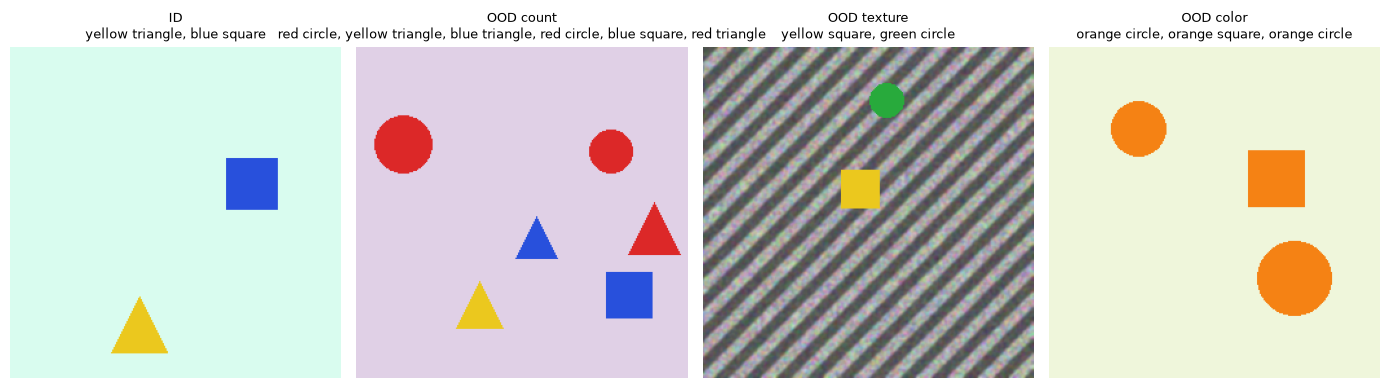

In [3]:
SHAPES = ["circle", "square", "triangle"]
COLORS = {"red": (220, 40, 40), "green": (40, 170, 60), "blue": (40, 80, 220), "yellow": (235, 200, 30)}
OOD_COLORS = {"purple": (140, 50, 180), "orange": (245, 130, 20)}
QUESTION = 'List the shapes in the image from left to right. Answer with JSON: {"count": N, "objects": ["<color> <shape>", ...]}.'

def draw_shape(d, shape, cx, cy, s, rgb):
    if shape == "circle":
        d.ellipse([cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2], fill=rgb)
    elif shape == "square":
        d.rectangle([cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2], fill=rgb)
    else:
        d.polygon([(cx, cy - s / 2), (cx - s / 2, cy + s / 2), (cx + s / 2, cy + s / 2)], fill=rgb)

def make_scene(rng, n_range=(1, 4), size=(36, 60), colors=COLORS, background="plain"):
    """Возвращает (изображение, эталонный ответ-словарь)."""
    W = IMG_SIDE
    if background == "plain":
        bg = tuple(int(v) for v in rng.integers(200, 256, 3))
        img = Image.new("RGB", (W, W), bg)
    else:   # шум + диагональные полосы: сдвиг фона
        arr = rng.integers(90, 256, (W, W, 3)).astype(np.uint8)
        yy, xx = np.mgrid[0:W, 0:W]
        arr[((xx + yy) // 12) % 2 == 0] //= 2
        img = Image.fromarray(arr).filter(ImageFilter.GaussianBlur(1))
    d = ImageDraw.Draw(img)
    n = int(rng.integers(n_range[0], n_range[1] + 1))
    objs, boxes = [], []
    while len(objs) < n:
        s = int(rng.integers(size[0], size[1] + 1))
        cx, cy = rng.integers(s // 2 + 4, W - s // 2 - 4, 2)
        if any(abs(cx - bx) < (s + bs) / 2 + 6 and abs(cy - by) < (s + bs) / 2 + 6 for bx, by, bs in boxes):
            continue
        if any(abs(cx - bx) < 8 for bx, _, _ in boxes):      # однозначный порядок слева направо
            continue
        shape = SHAPES[rng.integers(3)]; color = list(colors)[rng.integers(len(colors))]
        draw_shape(d, shape, cx, cy, s, colors[color])
        boxes.append((cx, cy, s)); objs.append((int(cx), f"{color} {shape}"))
    objs.sort()
    return img, {"count": n, "objects": [o for _, o in objs]}

def answer_text(target):
    return json.dumps(target)          # {"count": 2, "objects": ["red circle", "blue square"]}

def make_set(n, seed, **kw):
    rng = np.random.default_rng(seed)
    return [dict(zip(("image", "target"), make_scene(rng, **kw))) for _ in range(n)]

SETS = {
    "ID":          make_set(N_EVAL, 101),
    "OOD count":   make_set(N_EVAL, 102, n_range=(5, 6), size=(30, 44)),
    "OOD texture": make_set(N_EVAL, 103, background="texture", size=(26, 40)),
    "OOD color":   make_set(N_EVAL, 104, colors=OOD_COLORS),
}
train_set = make_set(N_TRAIN, 1)
val_set = make_set(n_(40, 8), 2)
# проверка утечки: ни одна оценочная сцена не совпадает с обучающей побайтно
h = lambda ex: hashlib.sha256(ex["image"].tobytes()).hexdigest()
train_hashes = {h(e) for e in train_set}
assert not any(h(e) in train_hashes for s in SETS.values() for e in s)
print("train:", len(train_set), "| val:", len(val_set), "|", {k: len(v) for k, v in SETS.items()})
print("распределение числа фигур в train:", sorted(Counter(e["target"]["count"] for e in train_set).items()))
print("пример ответа:", answer_text(train_set[0]["target"]))

fig, axs = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, (name, s) in zip(axs, SETS.items()):
    ax.imshow(s[0]["image"]); ax.axis("off")
    ax.set_title(name + "\n" + ", ".join(s[0]["target"]["objects"]), fontsize=9)
plt.tight_layout(); plt.show()

## 2. SFT-формат мультимодального диалога

### 2.1. Загрузка модели

На GPU модель загружается сразу в 4-bit NF4 (раздел 4 теории): `BitsAndBytesConfig` с `bnb_4bit_quant_type="nf4"`, `bnb_4bit_use_double_quant=True` и вычислениями в bf16 (Ampere и новее) или fp16 (T4). Визуальный энкодер и `lm_head` не квантуем (`llm_int8_skip_modules`): энкодер небольшой и чувствителен к ошибкам квантования, а `lm_head` определяет распределение по словарю.

Перед обучением делаем memory probe: если после загрузки свободной памяти меньше запаса на активации и состояния оптимизатора, освобождаем память и берём следующую, меньшую модель.

На CPU загружаем SmolVLM-256M-Instruct в fp32. Параметр `do_image_splitting=False` отключает нарезку изображения на тайлы: иначе процессор увеличивает картинку до 2048 пикселей по большей стороне и превращает её в 17 тайлов по 64 токена, что на CPU не помещается в память при обучении.

In [4]:
TRAIN_HEADROOM_GB = 3.0     # запас под активации, LoRA-градиенты и состояния оптимизатора

def gpu_budget_gb():
    free, total = torch.cuda.mem_get_info()
    return total / 2**30 if VRAM_BUDGET_GB is None else VRAM_BUDGET_GB

def load_model(mid):
    kw = {"do_image_splitting": False} if "SmolVLM" in mid else {}
    proc = AutoProcessor.from_pretrained(mid, **kw)
    if USE_4BIT:
        from transformers import BitsAndBytesConfig
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                 bnb_4bit_compute_dtype=COMPUTE_DTYPE, llm_int8_skip_modules=["visual", "lm_head"])
        model = AutoModelForImageTextToText.from_pretrained(mid, quantization_config=bnb, dtype=COMPUTE_DTYPE,
                                                            device_map={"": 0}, attn_implementation="sdpa")
    else:
        model = AutoModelForImageTextToText.from_pretrained(mid, dtype=COMPUTE_DTYPE, attn_implementation="sdpa")
    model.eval()
    return proc, model

for MODEL_ID in MODEL_CANDIDATES:
    try:
        t0 = time.time()
        processor, model = load_model(MODEL_ID)
        if HAS_GPU:
            used = torch.cuda.memory_allocated() / 2**30
            print(f"{MODEL_ID}: веса {used:.2f} ГБ, бюджет {gpu_budget_gb():.1f} ГБ")
            if used + TRAIN_HEADROOM_GB > gpu_budget_gb() and MODEL_ID != MODEL_CANDIDATES[-1]:
                print("  не хватает запаса на обучение → берём меньшую модель")
                del model; gc.collect(); torch.cuda.empty_cache(); continue
        break
    except torch.cuda.OutOfMemoryError:
        print(MODEL_ID, "OOM при загрузке"); gc.collect(); torch.cuda.empty_cache()

from huggingface_hub import model_info
try:
    MODEL_REVISION = model_info(MODEL_ID).sha
except Exception:
    MODEL_REVISION = "unknown"
tok = processor.tokenizer
n_params = sum(p.numel() for p in model.parameters())
print(f"модель: {MODEL_ID} | ревизия {MODEL_REVISION[:12]} | параметров {n_params/1e6:.1f} M | загрузка {time.time()-t0:.0f} с")

модель: HuggingFaceTB/SmolVLM-256M-Instruct | ревизия 7e3e67edbbed | параметров 256.5 M | загрузка 1 с


### 2.2. Messages и chat template

Обучающий пример — это диалог в формате `messages`: список реплик с ролями, где содержимое реплики — список частей `{"type": "image"}` и `{"type": "text", ...}`. Chat template (шаблон Jinja, хранится вместе с процессором) превращает диалог в строку со служебными токенами ролей и плейсхолдером изображения. Затем процессор заменяет плейсхолдер на нужное число визуальных токенов, а `pixel_values` уходят в визуальный энкодер.

Посмотрим, как один и тот же диалог выглядит в шаблонах двух разных моделей. Шаблоны различаются всем: маркерами ролей, концом реплики, обёрткой изображения. Поэтому данные хранят в нейтральном формате messages, а строку собирают шаблоном конкретной модели. Ручная сборка строки под «похожую» модель — частая причина тихой деградации.

In [5]:
def to_messages(ex, with_answer=True, question=QUESTION):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    if with_answer:
        msgs.append({"role": "assistant", "content": [{"type": "text", "text": answer_text(ex["target"])}]})
    return msgs

demo = {"image": None, "target": {"count": 1, "objects": ["red circle"]}}
print("Шаблон", MODEL_ID.split("/")[-1], ":\n", repr(processor.apply_chat_template(to_messages(demo), tokenize=False)), "\n")
OTHER_ID = "HuggingFaceTB/SmolVLM-256M-Instruct" if "Qwen" in MODEL_ID else "Qwen/Qwen3-VL-2B-Instruct"
try:
    other = AutoProcessor.from_pretrained(OTHER_ID)
    print("Шаблон", OTHER_ID.split("/")[-1], ":\n", repr(other.apply_chat_template(to_messages(demo), tokenize=False)))
    other_img_tokens = [t for t in other.tokenizer.all_special_tokens if any(k in t for k in ("image", "vision", "fake", "global"))]
    print("служебные визуальные токены:", other_img_tokens[:8])
except Exception as e:
    print("второй процессор недоступен:", type(e).__name__)

Шаблон SmolVLM-256M-Instruct :
 '<|im_start|>User:<image>List the shapes in the image from left to right. Answer with JSON: {"count": N, "objects": ["<color> <shape>", ...]}.<end_of_utterance>\nAssistant: {"count": 1, "objects": ["red circle"]}<end_of_utterance>\n' 



Шаблон Qwen3-VL-2B-Instruct :
 '<|im_start|>user\n<|vision_start|><|image_pad|><|vision_end|>List the shapes in the image from left to right. Answer with JSON: {"count": N, "objects": ["<color> <shape>", ...]}.<|im_end|>\n<|im_start|>assistant\n{"count": 1, "objects": ["red circle"]}<|im_end|>\n'
служебные визуальные токены: ['<|vision_start|>', '<|vision_end|>', '<|vision_pad|>', '<|image_pad|>']


### 2.3. Визуальные токены и маска loss

Функция `build_example` делает из диалога тензоры для обучения:

1. `full` — шаблон полного диалога, `prompt` — шаблон только реплики пользователя с `add_generation_prompt=True` (заканчивается маркером начала ответа ассистента).
2. Проверяем, что `prompt` — префикс `full`. Если это не так (некоторые шаблоны по-разному оформляют последнюю реплику), длину префикса считать нельзя и нужна маска через `{% generation %}`-разметку шаблона или поиск подпоследовательности токенов.
3. Токенизируем обе строки вместе с изображением: плейсхолдер разворачивается в визуальные токены, и длина промпта в токенах включает их.
4. `labels = input_ids`, но позиции промпта (системные токены, вопрос, все визуальные токены) получают −100 — индекс, который `CrossEntropyLoss` игнорирует. Модель учится только на токенах ответа и на токене конца реплики: без него она не научится останавливаться. Перевод строки, который шаблон ставит после маркера конца, тоже маскируем: это оформление шаблона, а не часть ответа.

In [6]:
IGNORE = -100
IMAGE_TOKEN_IDS = {tok.convert_tokens_to_ids(t) for t in ("<image>", "<|image_pad|>") if t in tok.get_vocab()}
END_ID = next(tok.convert_tokens_to_ids(t) for t in ("<end_of_utterance>", "<|im_end|>") if t in tok.get_vocab())   # конец реплики

def build_example(ex, question=QUESTION, answer=None):
    msgs = to_messages(ex, question=question)
    if answer is not None:
        msgs[1]["content"][0]["text"] = answer
    full = processor.apply_chat_template(msgs, tokenize=False)
    prompt = processor.apply_chat_template(msgs[:1], tokenize=False, add_generation_prompt=True)
    assert full.startswith(prompt), "промпт не является префиксом полного диалога"
    enc = processor(text=[full], images=[[ex["image"]]] if "SmolVLM" in MODEL_ID else [ex["image"]], return_tensors="pt")
    n_prompt = processor(text=[prompt], images=[[ex["image"]]] if "SmolVLM" in MODEL_ID else [ex["image"]],
                         return_tensors="pt")["input_ids"].shape[1]
    labels = enc["input_ids"].clone()
    labels[:, :n_prompt] = IGNORE
    ends = (labels[0] == END_ID).nonzero()
    if len(ends):                                  # перевод строки после маркера конца реплики — часть шаблона
        labels[:, int(ends[-1]) + 1:] = IGNORE
    enc["labels"] = labels
    return enc

enc = build_example(train_set[0])
ids, lab = enc["input_ids"][0], enc["labels"][0]
n_img = int(sum((ids == t).sum() for t in IMAGE_TOKEN_IDS))
print({k: tuple(v.shape) for k, v in enc.items()})
print(f"всего токенов {len(ids)} | визуальных {n_img} | в loss {int((lab != IGNORE).sum())} | доля ответа {(lab != IGNORE).float().mean():.0%}")
rows = []
for i, (t, l) in enumerate(zip(ids.tolist(), lab.tolist())):
    s = tok.convert_ids_to_tokens(t)
    if t in IMAGE_TOKEN_IDS and i > 0 and ids[i - 1].item() in IMAGE_TOKEN_IDS:
        continue                                     # схлопываем серию визуальных токенов
    rows.append((i, s if t not in IMAGE_TOKEN_IDS else f"{s} ×{n_img}", "loss" if l != IGNORE else "—"))
print(pd.DataFrame(rows, columns=["pos", "token", "в loss"]).to_string(index=False, max_rows=60))

{'input_ids': (1, 136), 'attention_mask': (1, 136), 'pixel_values': (1, 1, 3, 512, 512), 'pixel_attention_mask': (1, 1, 512, 512), 'labels': (1, 136)}
всего токенов 136 | визуальных 64 | в loss 27 | доля ответа 20%
 pos                     token в loss
   0              <|im_start|>      —
   1                      User      —
   2                         :      —
   3 <fake_token_around_image>      —
   4              <global-img>      —
   5               <image> ×64      —
  69 <fake_token_around_image>      —
  70                      List      —
  71                      Ġthe      —
  72                   Ġshapes      —
  73                       Ġin      —
  74                      Ġthe      —
  75                    Ġimage      —
  76                     Ġfrom      —
  77                     Ġleft      —
  78                       Ġto      —
  79                    Ġright      —
  80                         .      —
  81                   ĠAnswer      —
  82                     

Визуализируем маску: каждая клетка — токен, цвет — участвует ли он в loss. Большая часть последовательности — визуальные токены и промпт; при обучении на всей последовательности модель тратила бы ёмкость на предсказание собственного вопроса и (бессмысленно) плейсхолдеров изображения.

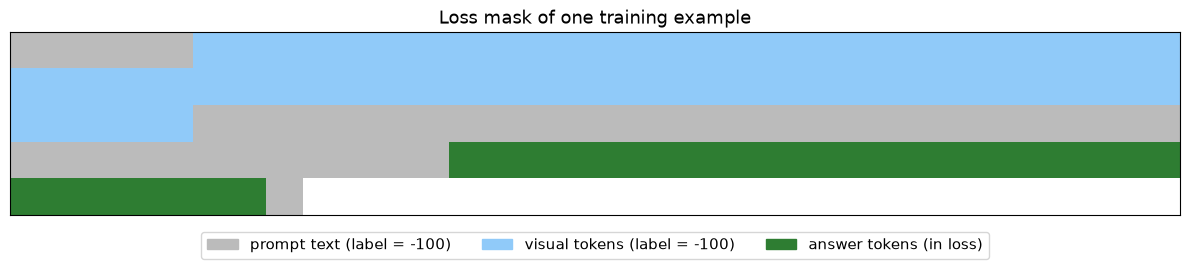

In [7]:
kind = np.array([2 if t in IMAGE_TOKEN_IDS else (1 if l != IGNORE else 0) for t, l in zip(ids.tolist(), lab.tolist())])
cols = 32
grid = np.full(int(np.ceil(len(kind) / cols)) * cols, -1); grid[:len(kind)] = kind
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["white", "#bbbbbb", "#2e7d32", "#90caf9"])
plt.figure(figsize=(12, 2.2 + 0.25 * len(grid) / cols))
plt.imshow(grid.reshape(-1, cols), cmap=cmap, vmin=-1, vmax=2)
plt.xticks([]); plt.yticks([])
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="#bbbbbb", label="prompt text (label = -100)"), Patch(color="#90caf9", label="visual tokens (label = -100)"),
                    Patch(color="#2e7d32", label="answer tokens (in loss)")], loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=11)
plt.title("Loss mask of one training example", fontsize=13); plt.tight_layout(); plt.show()

## 3. LoRA с нуля

Прежде чем пользоваться PEFT, реализуем LoRA-слой сами — это 20 строк. Проверим три свойства из теории:

1. При $B = 0$ слой в точности совпадает с исходным.
2. После обучения добавку можно слить в веса: $W' = W_0 + \frac{\alpha}{r} BA$, и выход не изменится.
3. Число обучаемых параметров — $r(d_{in} + d_{out})$.

In [8]:
import torch.nn as nn

class LoRALinear(nn.Module):
    """Линейный слой с замороженными весами и низкоранговой добавкой (alpha / r) * B @ A."""
    def __init__(self, base: nn.Linear, r=8, alpha=16, dropout=0.0, rslora=False):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))   # гауссова инициализация
        self.B = nn.Parameter(torch.zeros(base.out_features, r))                                # нули → ΔW = 0
        self.scale = alpha / math.sqrt(r) if rslora else alpha / r
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * (self.drop(x) @ self.A.T @ self.B.T)

    @torch.no_grad()
    def merged(self):
        m = nn.Linear(self.base.in_features, self.base.out_features, bias=self.base.bias is not None)
        m.weight.copy_(self.base.weight + self.scale * self.B @ self.A)
        if self.base.bias is not None:
            m.bias.copy_(self.base.bias)
        return m

torch.manual_seed(0)
d_in, d_out = 256, 192
base = nn.Linear(d_in, d_out)
lora = LoRALinear(base, r=8, alpha=16)
x = torch.randn(32, d_in)
print("1) при B = 0 выход совпадает с исходным:", torch.equal(lora(x), base(x)))

# немного обучим на случайной регрессии, чтобы B и A стали ненулевыми
target = torch.randn(d_out, d_in) * 0.05
opt_ = torch.optim.Adam([lora.A, lora.B], lr=1e-2)
for _ in range(100):
    xb = torch.randn(64, d_in)
    loss = ((lora(xb) - (base(xb) + xb @ target.T)) ** 2).mean()
    opt_.zero_grad(); loss.backward(); opt_.step()
merged = lora.merged()
print(f"2) после обучения: |ΔW| = {(lora.scale * lora.B @ lora.A).norm():.3f}, "
      f"максимальная разница выходов LoRA и слитого слоя = {(lora(x) - merged(x)).abs().max():.2e}")
n_train = sum(p.numel() for p in lora.parameters() if p.requires_grad)
print(f"3) обучаемых параметров: {n_train} = r (d_in + d_out) = {8 * (d_in + d_out)}; у полного слоя {d_in * d_out} ({n_train / (d_in * d_out):.1%})")

1) при B = 0 выход совпадает с исходным: True
2) после обучения: |ΔW| = 3.951, максимальная разница выходов LoRA и слитого слоя = 2.03e-06
3) обучаемых параметров: 3584 = r (d_in + d_out) = 3584; у полного слоя 49152 (7.3%)


Сколько параметров обучает LoRA на реальных моделях? Ниже — расчёт по размерам слоёв языковой модели загруженной VLM и двух моделей Qwen3-VL для разных рангов и наборов целевых модулей.

In [9]:
def lm_linear_shapes(m):
    """(in, out) линейных слоёв одного блока языковой модели по их суффиксам."""
    shapes = {}
    for n, mod in m.named_modules():
        if isinstance(mod, nn.Linear) and re.search(r"(text_model|language_model).*layers\.0\.", n):
            shapes[n.split(".")[-1]] = (mod.in_features, mod.out_features)
    return shapes

shapes = lm_linear_shapes(model)
n_layers = len({re.search(r"layers\.(\d+)\.", n).group(1) for n, _ in model.named_modules() if re.search(r"(text_model|language_model).*layers\.\d+\.", n)})
print("слои одного блока:", shapes, "| блоков:", n_layers)
rows = []
for targets in [("q_proj", "v_proj"), ("q_proj", "k_proj", "v_proj", "o_proj"), tuple(shapes)]:
    for r in [4, 16, 64]:
        k = n_layers * sum(r * (shapes[t][0] + shapes[t][1]) for t in targets if t in shapes)
        rows.append(dict(targets="all linear" if len(targets) == len(shapes) else "+".join(t[0] for t in targets), r=r,
                         trainable_M=k / 1e6, share=k / n_params))
print(pd.DataFrame(rows).to_string(index=False, formatters={"share": "{:.3%}".format, "trainable_M": "{:.2f}".format}))

слои одного блока: {'q_proj': (576, 576), 'k_proj': (576, 192), 'v_proj': (576, 192), 'o_proj': (576, 576), 'gate_proj': (576, 1536), 'up_proj': (576, 1536), 'down_proj': (1536, 576)} | блоков: 30
   targets  r trainable_M  share
       q+v  4        0.23 0.090%
       q+v 16        0.92 0.359%
       q+v 64        3.69 1.437%
   q+k+v+o  4        0.46 0.180%
   q+k+v+o 16        1.84 0.719%
   q+k+v+o 64        7.37 2.875%
all linear  4        1.22 0.476%
all linear 16        4.88 1.904%
all linear 64       19.54 7.618%


### 3.1. Масштаб α/r против α/√r (rsLoRA)

Проверим утверждение rsLoRA на игрушечной задаче. Восстанавливаем «настоящее» изменение весов $\Delta W^*$ ранга 32 адаптерами разного ранга при одинаковых $\alpha$, learning rate и числе шагов. При масштабе $\alpha / r$ адаптеры большого ранга обучаются медленнее: их вклад в выход уменьшается как $1/\sqrt{r}$. При $\alpha / \sqrt{r}$ вклад адаптера не уменьшается с ростом ранга, и дополнительная ёмкость большого ранга используется сразу.

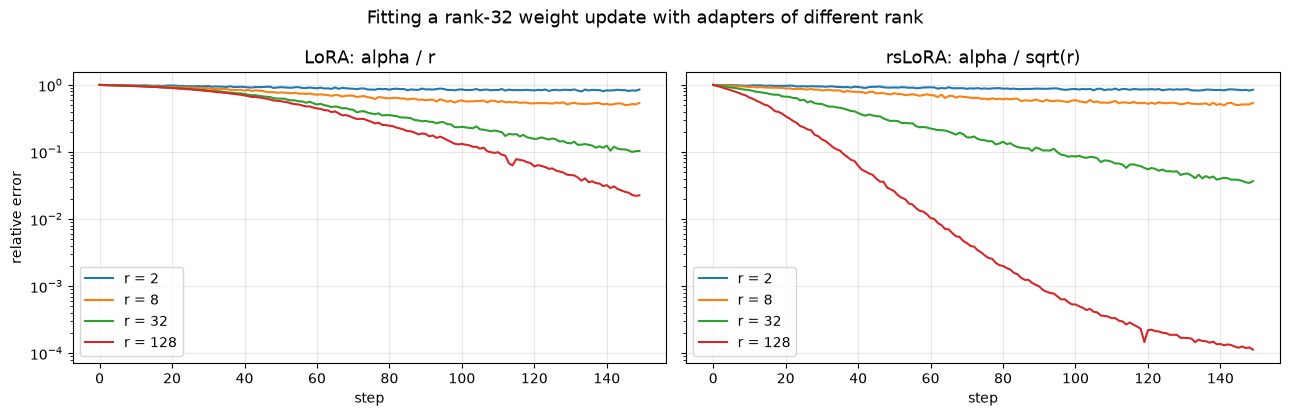

scale  alpha/r  alpha/sqrt(r)
r                            
2        0.832          0.842
8        0.518          0.517
32       0.109          0.038
128      0.026          0.000


In [10]:
def fit_lora(r, rslora, steps=150, d=128, true_rank=32, alpha=8, lr=2e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    W0 = nn.Linear(d, d, bias=False)
    dW = (torch.randn(d, true_rank, generator=g) @ torch.randn(true_rank, d, generator=g)) / d
    layer = LoRALinear(W0, r=r, alpha=alpha, rslora=rslora)
    opt_ = torch.optim.Adam([layer.A, layer.B], lr=lr)
    losses = []
    for _ in range(steps):
        xb = torch.randn(128, d, generator=g)
        loss = ((layer(xb) - W0(xb) - xb @ dW.T) ** 2).mean() / (xb @ dW.T).pow(2).mean().item()
        opt_.zero_grad(); loss.backward(); opt_.step(); losses.append(loss.item())
    return losses

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
final = []
for ax, rs in zip(axs, [False, True]):
    for r in [2, 8, 32, 128]:
        l = fit_lora(r, rs)
        ax.plot(l, label=f"r = {r}"); final.append(dict(scale="alpha/sqrt(r)" if rs else "alpha/r", r=r, final_rel_error=np.mean(l[-10:])))
    ax.set_title("rsLoRA: alpha / sqrt(r)" if rs else "LoRA: alpha / r", fontsize=13); ax.set_xlabel("step"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=0.3)
axs[0].set_ylabel("relative error")
plt.suptitle("Fitting a rank-32 weight update with adapters of different rank", fontsize=13); plt.tight_layout(); plt.show()
print(pd.DataFrame(final).pivot(index="r", columns="scale", values="final_rel_error").round(3).to_string())

## 4. Квантование: NF4 и double quantization своими руками

Реализуем блочное квантование из раздела 8 теории на NumPy/PyTorch и применим его к настоящей матрице весов модели. Это позволяет увидеть, откуда берутся числа 4.5 и 4.127 бита на параметр и почему NF4 точнее int4 при том же числе бит.

### 4.1. Уровни NF4

Строим 16 уровней NF4 как квантили стандартного нормального распределения: 8 для положительной половины, 7 для отрицательной и точный ноль, затем нормируем в $[-1, 1]$. Константа `offset = 0.9677` — крайняя вероятность, при которой берётся последний квантиль (сам квантиль уровня 1 бесконечен). Сравниваем с таблицей из приложения E статьи QLoRA ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)), которая используется в bitsandbytes.

In [11]:
from torch.distributions import Normal
NF4_TABLE = [-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635,
             -0.18477343022823334, -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141124725,
             0.24611230194568634, 0.33791524171829224, 0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0]

def nf4_levels(offset=0.9677083):
    N01 = Normal(0.0, 1.0)
    pos = N01.icdf(torch.linspace(offset, 0.5, 9)[:-1])      # 8 положительных квантилей
    neg = -N01.icdf(torch.linspace(offset, 0.5, 8)[:-1])     # 7 отрицательных
    v = torch.cat([pos, torch.zeros(1), neg])
    return torch.sort(v / v.max()).values

NF4 = nf4_levels()
INT4 = torch.arange(-7, 8, dtype=torch.float32) / 7         # симметричный int4 с absmax: 15 равномерных уровней
print("макс. отличие от таблицы bitsandbytes:", float((NF4 - torch.tensor(NF4_TABLE)).abs().max()))
print("NF4: ", np.round(NF4.numpy(), 3))
print("int4:", np.round(INT4.numpy(), 3))

макс. отличие от таблицы bitsandbytes: 5.960464477539063e-08
NF4:  [-1.    -0.696 -0.525 -0.395 -0.284 -0.185 -0.091  0.     0.08   0.161
  0.246  0.338  0.441  0.563  0.723  1.   ]
int4: [-1.    -0.857 -0.714 -0.571 -0.429 -0.286 -0.143  0.     0.143  0.286
  0.429  0.571  0.714  0.857  1.   ]


### 4.2. Квантование настоящего веса

Берём матрицу весов линейного слоя модели (на GPU языковая модель уже квантована, поэтому используем слой визуального энкодера, оставленный в 16 битах; на CPU — первый слой языковой модели). Делим на блоки по 64, считаем absmax каждого блока, нормируем, заменяем каждое значение ближайшим уровнем и восстанавливаем.

Double quantization: константы absmax (fp32, по одной на блок) делим на блоки по 256, вычитаем среднее и квантуем линейно в 8 бит с собственным absmax. В статье для второго уровня используется 8-битный float; линейный 8-битный вариант проще и даёт тот же расход памяти.

вес: model.text_model.layers.0.self_attn.q_proj (576, 576) | среднее 0.0000, std 0.2183
          format bits_per_param rel_MSE  used_levels
     int4 absmax          4.500 0.01698           15
int4 absmax + DQ          4.127 0.01701           15
             NF4          4.500 0.01011           16
        NF4 + DQ          4.127 0.01013           16
относительная ошибка выхода слоя с NF4 + DQ: 0.0986


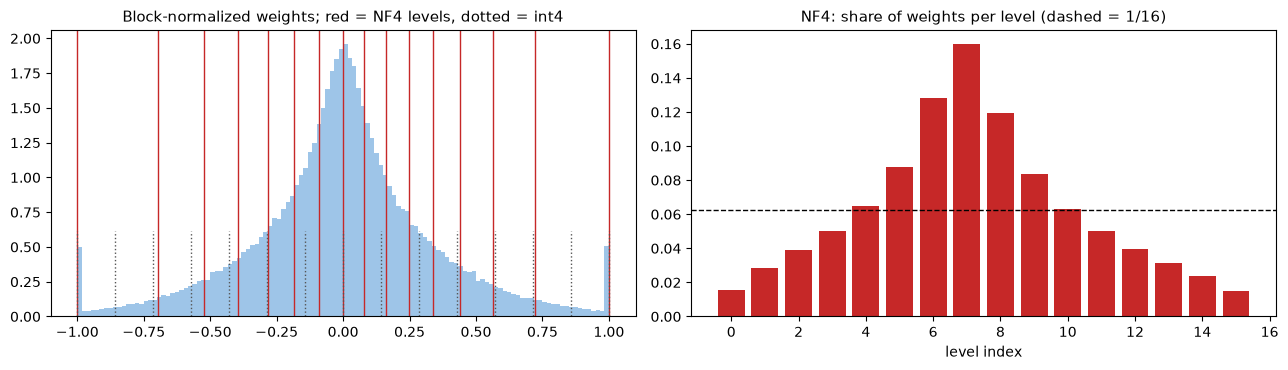

In [12]:
def pick_weight(m):
    for n, mod in m.named_modules():
        w = getattr(mod, "weight", None)
        if isinstance(mod, nn.Linear) and w is not None and w.dtype.is_floating_point and min(w.shape) >= 256:
            if HAS_GPU and not ("visual" in n or "vision" in n):
                continue
            if not HAS_GPU and not ("text_model" in n or "language_model" in n):
                continue
            return n, w.detach().float().cpu()
name_w, Wt = pick_weight(model)
print("вес:", name_w, tuple(Wt.shape), f"| среднее {Wt.mean():.4f}, std {Wt.std():.4f}")

def quantize_blockwise(w, levels, block=64):
    flat = w.flatten()
    pad = (-len(flat)) % block
    blocks = torch.cat([flat, flat.new_zeros(pad)]).view(-1, block)
    absmax = blocks.abs().max(dim=1, keepdim=True).values.clamp_min(1e-12)
    idx = ((blocks / absmax).unsqueeze(-1) - levels).abs().argmin(-1)          # индекс ближайшего уровня (4 бита)
    return idx, absmax.squeeze(1), pad

def dequantize_blockwise(idx, absmax, levels, pad, shape):
    flat = (levels[idx] * absmax.unsqueeze(1)).flatten()
    return flat[:len(flat) - pad].view(shape) if pad else flat.view(shape)

def double_quant(absmax, block=256):
    """8-битное линейное квантование констант absmax блоками по 256 после вычитания среднего."""
    mean = absmax.mean()
    c = absmax - mean
    pad = (-len(c)) % block
    cb = torch.cat([c, c.new_zeros(pad)]).view(-1, block)
    s = cb.abs().max(dim=1, keepdim=True).values.clamp_min(1e-12) / 127
    q = torch.round(cb / s).clamp(-127, 127)
    rec = (q * s).flatten()[:len(c)] + mean
    return rec

rows = []
for qname, levels in [("int4 absmax", INT4), ("NF4", NF4)]:
    idx, absmax, pad = quantize_blockwise(Wt, levels)
    W_hat = dequantize_blockwise(idx, absmax, levels, pad, Wt.shape)
    W_dq = dequantize_blockwise(idx, double_quant(absmax), levels, pad, Wt.shape)
    for dq, Wr, bits in [(False, W_hat, 4 + 32 / 64), (True, W_dq, 4 + 8 / 64 + 32 / (64 * 256))]:
        err = (Wr - Wt).pow(2).mean() / Wt.pow(2).mean()
        rows.append(dict(format=qname + (" + DQ" if dq else ""), bits_per_param=bits, rel_MSE=err.item(),
                         used_levels=int(torch.unique(idx).numel())))
qt = pd.DataFrame(rows)
print(qt.to_string(index=False, formatters={"bits_per_param": "{:.3f}".format, "rel_MSE": "{:.5f}".format}))
x_in = torch.randn(64, Wt.shape[1])
idx, absmax, pad = quantize_blockwise(Wt, NF4)
W_nf4 = dequantize_blockwise(idx, double_quant(absmax), NF4, pad, Wt.shape)
y, y_hat = x_in @ Wt.T, x_in @ W_nf4.T
print(f"относительная ошибка выхода слоя с NF4 + DQ: {((y_hat - y).norm() / y.norm()).item():.4f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
blocks = Wt.flatten()[: (Wt.numel() // 64) * 64].view(-1, 64)
normed = (blocks / blocks.abs().max(1, keepdim=True).values).flatten().numpy()
axs[0].hist(normed, bins=120, color="#9ec5e8", density=True)
for v in NF4.numpy():
    axs[0].axvline(v, color="#c62828", lw=1)
for v in INT4.numpy():
    axs[0].axvline(v, color="#555", lw=1, ls=":", ymax=0.3)
axs[0].set_title("Block-normalized weights; red = NF4 levels, dotted = int4", fontsize=11)
counts = np.bincount(idx.flatten().numpy(), minlength=16) / idx.numel()
axs[1].bar(range(16), counts, color="#c62828"); axs[1].axhline(1 / 16, color="k", ls="--", lw=1)
axs[1].set_title("NF4: share of weights per level (dashed = 1/16)", fontsize=11); axs[1].set_xlabel("level index")
plt.tight_layout(); plt.show()

Что показывают цифры (CPU-прогон, слой `text_model.layers.0.self_attn.q_proj` SmolVLM, 576×576).

- Построенные квантили совпадают с таблицей NF4 из bitsandbytes с точностью до $6 \cdot 10^{-8}$, то есть константа смещения 0.9677083 из статьи QLoRA действительно задаёт именно эти уровни.
- При одинаковом бюджете 4.5 бита на параметр NF4 даёт относительную MSE около 0.0101 против 0.0170 у равномерного int4 — ошибка меньше примерно в 1.7 раза. Причина видна на левом графике: нормированные веса сосредоточены около нуля, и NF4 ставит туда больше уровней, а int4 тратит уровни на редкие хвосты.
- Правый график: доли весов по уровням NF4 близки к 1/16 в середине диапазона — это и есть смысл квантильного квантования (каждый уровень используется примерно одинаково часто). Крайние уровни ±1 заняты реже: в них попадает только максимум каждого блока.
- Double quantization снижает накладные расходы с 0.5 до примерно 0.127 бита на параметр (итого 4.127 вместо 4.5), а MSE почти не меняется (0.01011 → 0.01013). Экономия 0.373 бита на параметр — около 3 ГБ на модели 65B, как и указано в [статье QLoRA](https://arxiv.org/abs/2305.14314).
- Относительная ошибка выхода слоя около 10% кажется большой, но она относится к одному слою с замороженными весами; в QLoRA градиенты идут через деквантованные веса, а адаптер LoRA в bf16 компенсирует систематическую часть ошибки во время обучения.

In [13]:
if HAS_GPU and USE_4BIT:
    import bitsandbytes as bnb
    q_layers = [m for m in model.modules() if isinstance(m, bnb.nn.Linear4bit)]
    qs = q_layers[0].weight.quant_state
    print(f"слоёв Linear4bit: {len(q_layers)} | тип: {qs.quant_type} | размер блока: {qs.blocksize} | "
          f"double quant (nested): {qs.nested} | compute dtype: {q_layers[0].compute_dtype}")
    print(f"занятая память модели: {model.get_memory_footprint() / 2**30:.2f} ГБ")
else:
    print("на CPU bitsandbytes 4-bit недоступен; на GPU здесь печатаются параметры quant_state реальной модели")

на CPU bitsandbytes 4-bit недоступен; на GPU здесь печатаются параметры quant_state реальной модели


## 5. Базовая модель: отправная точка и замеры для оценки забывания

До обучения фиксируем три вещи.

1. Качество базовой модели на ID- и OOD-наборах. Без этой точки отсчёта нельзя сказать, что дало дообучение.
2. Общие способности, которые не должны пострадать: zero-shot-классификация CIFAR-10 (модель видела такие задачи при instruction tuning, а в нашем SFT их нет) и ответы на общие вопросы об изображениях.
3. Собственные ответы базовой модели на общие вопросы. Они нужны дважды: как эталон для измерения дрейфа (насколько адаптированная модель «разучилась» отвечать как раньше) и как replay-данные для одной из конфигураций обучения (self-distillation replay).

Метрики задачи считаем по распарсенному JSON:

- valid JSON — ответ парсится и содержит ключи `count` и `objects` нужных типов;
- exact match — список объектов совпадает с эталоном полностью, с учётом порядка;
- count accuracy — правильное число фигур (поле `count`);
- object F1 — F1 по мультимножеству строк «цвет фигура» без учёта порядка: частичный кредит за частично верный ответ.

In [14]:
tok.padding_side = "left"          # для батчевой генерации промпты выравниваются по правому краю
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
GEN_MAX_NEW = 64
GEN_BS = n_(16, 8)

def _images_arg(imgs):
    return [[im] for im in imgs] if "SmolVLM" in MODEL_ID else list(imgs)

@torch.no_grad()
def generate(m, images, question=QUESTION, max_new_tokens=GEN_MAX_NEW, bs=GEN_BS):
    """Жадная генерация ответов батчами; возвращает список строк."""
    outs = []
    m.eval()
    for i in range(0, len(images), bs):
        chunk = images[i:i + bs]
        prompt = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}],
                                               tokenize=False, add_generation_prompt=True)
        enc = processor(text=[prompt] * len(chunk), images=_images_arg(chunk), return_tensors="pt", padding=True).to(DEVICE)
        if "pixel_values" in enc and enc["pixel_values"].is_floating_point():
            enc["pixel_values"] = enc["pixel_values"].to(m.dtype if not USE_4BIT else COMPUTE_DTYPE)
        gen = m.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += [s.strip() for s in tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return outs

def parse_answer(s):
    m = re.search(r"\{.*\}", s, flags=re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except Exception:
        return None
    if not (isinstance(d, dict) and isinstance(d.get("count"), int) and isinstance(d.get("objects"), list)):
        return None
    return d

def score(preds, data):
    v = em = cnt = 0; f1s = []
    for p, ex in zip(preds, data):
        t, d = ex["target"], parse_answer(p)
        if d is None:
            f1s.append(0.0); continue
        v += 1
        objs = [str(o).strip().lower() for o in d["objects"]]
        em += objs == t["objects"]
        cnt += d["count"] == t["count"]
        inter = sum((Counter(objs) & Counter(t["objects"])).values())
        f1s.append(2 * inter / (len(objs) + len(t["objects"])) if objs or t["objects"] else 1.0)
    n = len(data)
    return {"valid JSON": v / n, "exact match": em / n, "count acc": cnt / n, "object F1": float(np.mean(f1s))}

def eval_task(m, sets=SETS):
    res, raw = {}, {}
    for name, data in sets.items():
        preds = generate(m, [e["image"] for e in data])
        res[name], raw[name] = score(preds, data), preds
    return pd.DataFrame(res).T, raw

t0 = time.time()
base_task, base_raw = eval_task(model)
print(f"базовая модель, {time.time()-t0:.0f} с"); print(base_task.round(3).to_string())
for p, ex in list(zip(base_raw["ID"], SETS["ID"]))[:3]:
    print("эталон:", answer_text(ex["target"]), "\n  ответ:", p[:160])

базовая модель, 180 с
             valid JSON  exact match  count acc  object F1
ID                  0.0          0.0        0.0        0.0
OOD count           0.0          0.0        0.0        0.0
OOD texture         0.0          0.0        0.0        0.0
OOD color           0.0          0.0        0.0        0.0
эталон: {"count": 2, "objects": ["yellow triangle", "blue square"]} 
  ответ: {
    "object": {
        "name": "<color>",
        "type": "shape",
        "object_id": "10000000",
        "description": "<color> <shape>",
        "items"
эталон: {"count": 4, "objects": ["red square", "green triangle", "blue square", "yellow square"]} 
  ответ: {
    "object": [
        {
            "name": "<color>"
        },
        {
            "name": "<blue>"
        },
        {
            "name": "<yellow>"

эталон: {"count": 3, "objects": ["yellow triangle", "red circle", "green square"]} 
  ответ: {
    "object": {
        "name": "<color> <shape>",
        "object_id": "1000000

### 5.1. Замер общих способностей

CIFAR-10 zero-shot. Задаём вопрос со списком из десяти классов и сравниваем логиты первого токена каждого названия класса на первой позиции ответа. Генерация не нужна: один прямой проход на изображение, и ответ всегда один из классов. Изображения 32×32 увеличиваются процессором, поэтому абсолютная точность невысока; нас интересует её изменение после адаптации.

Дрейф на общих вопросах. На изображениях CIFAR-10 задаём три общих вопроса (описать изображение, назвать главный объект, назвать цвета), генерируем ответы базовой моделью и сохраняем их. После адаптации считаем среднюю отрицательную логарифмическую правдоподобность (NLL на токен) этих же ответов. Рост NLL означает, что модель «отошла» от своего исходного поведения на задачах, которых не было в SFT. Это дешёвая аппроксимация KL-дивергенции между старым и новым распределением ответов: по построению $\mathrm{NLL}_{\text{new}} - \mathrm{NLL}_{\text{base}}$ — это оценка Монте-Карло величины $\mathrm{KL}(p_{\text{base}} \,\|\, p_{\text{new}})$ на ответах, взятых из $p_{\text{base}}$ (для жадных ответов — приближённо).

In [15]:
from huggingface_hub import hf_hub_download
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
cifar = pd.read_parquet(hf_hub_download("uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet", repo_type="dataset"))
rng = np.random.default_rng(7)
idx = rng.permutation(len(cifar))
cifar_eval = [(Image.open(io.BytesIO(cifar.img[i]["bytes"])).convert("RGB"), int(cifar.label[i])) for i in idx[:N_CIFAR]]
cifar_gen  = [Image.open(io.BytesIO(cifar.img[i]["bytes"])).convert("RGB") for i in idx[N_CIFAR:N_CIFAR + 2 * N_GENERAL]]
CIFAR_Q = "What is shown in this image? Answer with one word from this list: " + ", ".join(CLASSES) + "."
CLASS_FIRST_TOK = [tok(" " + c if "SmolVLM" in MODEL_ID else c, add_special_tokens=False)["input_ids"][0] for c in CLASSES]
assert len(set(CLASS_FIRST_TOK)) == 10, "первые токены классов должны различаться"

@torch.no_grad()
def cifar_accuracy(m, data=cifar_eval, bs=GEN_BS):
    m.eval(); correct = 0
    prompt = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": CIFAR_Q}]}],
                                           tokenize=False, add_generation_prompt=True)
    for i in range(0, len(data), bs):
        imgs, ys = zip(*data[i:i + bs])
        enc = processor(text=[prompt] * len(imgs), images=_images_arg(imgs), return_tensors="pt", padding=True).to(DEVICE)
        logits = m(**enc).logits[:, -1, :]
        pred = logits[:, CLASS_FIRST_TOK].argmax(-1).cpu().numpy()
        correct += int((pred == np.array(ys)).sum())
    return correct / len(data)

GENERAL_QS = ["Describe this image in one sentence.", "What is the main object in this image?", "What colors dominate this image?"]
def general_items(imgs, offset=0):
    return [{"image": im, "question": GENERAL_QS[(k + offset) % 3]} for k, im in enumerate(imgs)]
general_eval = general_items(cifar_gen[:N_GENERAL])            # для измерения дрейфа
general_replay = general_items(cifar_gen[N_GENERAL:], offset=1)  # для replay (другие изображения)

def answer_general(m, items):
    out = []
    for q in GENERAL_QS:
        sub = [it for it in items if it["question"] == q]
        ans = generate(m, [it["image"] for it in sub], question=q, max_new_tokens=40)
        for it, a in zip(sub, ans):
            out.append({**it, "answer": a})
    return out

t0 = time.time()
general_eval = answer_general(model, general_eval)
general_replay = answer_general(model, general_replay)
base_cifar = cifar_accuracy(model)

@torch.no_grad()
def answer_nll(m, items):
    """Средняя NLL на токен ответов базовой модели под моделью m."""
    m.eval(); tot, n = 0.0, 0
    for it in items:
        enc = build_example({"image": it["image"], "target": None}, question=it["question"], answer=it["answer"]).to(DEVICE)
        out = m(**enc)
        k = int((enc["labels"] != IGNORE).sum())
        tot += out.loss.item() * k; n += k
    return tot / n

base_nll = answer_nll(model, general_eval)
print(f"CIFAR-10 zero-shot: {base_cifar:.3f} (случайное угадывание 0.100) | NLL собственных ответов: {base_nll:.3f} | {time.time()-t0:.0f} с")
for it in general_eval[:3]:
    print(f"Q: {it['question']}\nA: {it['answer']}")
record("base", "CIFAR-10 zero-shot", base_cifar)

CIFAR-10 zero-shot: 0.167 (случайное угадывание 0.100) | NLL собственных ответов: 1.199 | 139 с
Q: Describe this image in one sentence.
A: In this image there is a frog on the ground.
Q: Describe this image in one sentence.
A: In this image, there is a person wearing a red and blue color dress.
Q: Describe this image in one sentence.
A: In this image, there is a person wearing a black dress and a white shirt.


## 6. PEFT-модель и экономия памяти

### 6.1. Подключение LoRA через PEFT

`LoraConfig` задаёт ранг, α, dropout и целевые модули. Целевые модули указываем регулярным выражением, которое PEFT сопоставляет с полным именем модуля (`re.fullmatch`): так адаптеры встают только в языковую модель, а визуальный энкодер, у которого тоже есть слои с именами `q_proj`/`v_proj`, остаётся нетронутым. Вариант `target_modules="all-linear"` выбрал бы все линейные слои, кроме выходного, включая визуальный энкодер и проектор ([документация PEFT](https://huggingface.co/docs/peft/main/en/developer_guides/lora)).

Gradient checkpointing включаем в варианте `use_reentrant=False`: он корректно работает, когда входы блока не требуют градиента (базовая модель заморожена). `enable_input_require_grads()` нужен для старого reentrant-варианта; вызываем его для совместимости. `use_cache=False`: KV-кэш при обучении не нужен и несовместим с checkpointing.

In [16]:
from peft import LoraConfig, get_peft_model, PeftModel

LM_REGEX = r".*(?:text_model|language_model).*\.(?:{})"
print("типы линейных слоёв:", sorted({n.split(".")[-1] for n, m in model.named_modules() if isinstance(m, torch.nn.Linear)}))
main_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", init_lora_weights=True,
                      target_modules=LM_REGEX.format("q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj"))
model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()
peft_model = get_peft_model(model, main_cfg, adapter_name="main")
peft_model.print_trainable_parameters()
lora_mods = [n for n, m in peft_model.named_modules() if hasattr(m, "lora_A") and "main" in m.lora_A]
print("модулей с LoRA:", len(lora_mods), "| пример:", lora_mods[0])
print("в визуальном энкодере:", sum(("vision" in n or "visual" in n) for n in lora_mods))

типы линейных слоёв: ['down_proj', 'fc1', 'fc2', 'gate_proj', 'k_proj', 'lm_head', 'o_proj', 'out_proj', 'proj', 'q_proj', 'up_proj', 'v_proj']
trainable params: 4,884,480 || all params: 261,369,408 || trainable%: 1.8688
модулей с LoRA: 210 | пример: base_model.model.model.text_model.layers.0.self_attn.q_proj
в визуальном энкодере: 0


### 6.2. Калькулятор памяти: полное дообучение, LoRA, QLoRA

Оценим память для трёх размеров Qwen3-VL по формулам раздела 9 теории. Число параметров берём из метаданных safetensors на Hugging Face Hub, размеры языковой модели — из конфигурации.

Допущения расчёта:

- полное дообучение в смешанной точности с Adam: 2 (веса bf16) + 2 (градиенты) + 4 (fp32-копия весов) + 8 (два момента Adam в fp32) = 16 байт на параметр;
- LoRA: замороженные веса 2 байта на параметр, обучаемые LoRA-параметры — 16 байт;
- QLoRA: замороженные веса 4.127 бита на параметр (NF4 + double quantization) для языковой модели, визуальный энкодер в 16 бит; LoRA-параметры — 16 байт, а с 8-bit Adam — 2 + 4 + 2 = 8 байт (веса fp32, градиенты bf16, два момента по байту);
- активации — по формуле Korthikanti et al. $sbh(34 + 5as/h)$ байт на слой ([arXiv:2205.05198](https://arxiv.org/abs/2205.05198)); с memory-efficient attention слагаемое $5as^2b$ пропадает, а с полным checkpointing хранятся только входы слоёв, $2sbh$ байт на слой, плюс активации одного слоя при пересчёте. Формула выведена для GPT-подобного блока, для SwiGLU-MLP это грубая, но разумная оценка.

In [17]:
from transformers import AutoConfig
from huggingface_hub import get_safetensors_metadata

def lm_dims(cfg):
    c = getattr(cfg, "text_config", cfg)
    return c.num_hidden_layers, c.hidden_size, c.num_attention_heads, c.intermediate_size, c.num_key_value_heads

def lora_params_per_layer(h, inter, n_kv, n_heads, r):
    hd = h // n_heads
    shapes = [(h, h), (h, n_kv * hd), (h, n_kv * hd), (h, h), (h, inter), (h, inter), (inter, h)]   # q k v o gate up down
    return sum(r * (i + o) for i, o in shapes)

def memory_table(mid, total_params, seq=512, b=1, r=16, gb=2**30):
    L, h, a, inter, n_kv = lm_dims(AutoConfig.from_pretrained(mid))
    lora = L * lora_params_per_layer(h, inter, n_kv, a, r)
    vis = 0.45e9 if "4B" in mid or "8B" in mid else 0.4e9           # примерный размер визуальной части
    act_eager = L * seq * b * h * (34 + 5 * a * seq / h)
    act_flash = L * seq * b * h * 34
    act_ckpt = L * 2 * seq * b * h + seq * b * h * 34
    rows = {
        "full FT (bf16 + Adam fp32)": (16 * total_params, act_flash),
        "LoRA r=16 (bf16 base)":      (2 * total_params + 16 * lora, act_flash),
        "QLoRA r=16 (NF4+DQ, 8-bit Adam)": ((total_params - vis) * 4.127 / 8 + 2 * vis + 8 * lora, act_flash),
        "QLoRA + checkpointing":      ((total_params - vis) * 4.127 / 8 + 2 * vis + 8 * lora, act_ckpt),
    }
    out = pd.DataFrame({k: {"states GB": s / gb, "activations GB": act / gb, "total GB": (s + act) / gb} for k, (s, act) in rows.items()}).T
    return out, lora, act_eager / gb

for mid in ["Qwen/Qwen3-VL-2B-Instruct", "Qwen/Qwen3-VL-4B-Instruct", "Qwen/Qwen3-VL-8B-Instruct"]:
    try:
        meta = get_safetensors_metadata(mid)
        total = sum(meta.parameter_count.values())
        tab, lora, eager = memory_table(mid, total)
        print(f"\n{mid}: {total/1e9:.2f} B параметров, LoRA r=16 на всех линейных слоях LM: {lora/1e6:.1f} M ({lora/total:.2%})")
        print(f"  активации при eager attention (s=512): {eager:.2f} ГБ")
        print(tab.round(2).to_string())
    except Exception as e:
        print(mid, "метаданные недоступны:", type(e).__name__)


Qwen/Qwen3-VL-2B-Instruct: 2.13 B параметров, LoRA r=16 на всех линейных слоях LM: 17.4 M (0.82%)
  активации при eager attention (s=512): 1.48 ГБ
                                 states GB  activations GB  total GB
full FT (bf16 + Adam fp32)           31.70            0.93     32.63
LoRA r=16 (bf16 base)                 4.22            0.93      5.15
QLoRA r=16 (NF4+DQ, 8-bit Adam)       1.70            0.93      2.63
QLoRA + checkpointing                 1.70            0.09      1.79



Qwen/Qwen3-VL-4B-Instruct: 4.44 B параметров, LoRA r=16 на всех линейных слоях LM: 30.8 M (0.69%)
  активации при eager attention (s=512): 2.90 ГБ
                                 states GB  activations GB  total GB
full FT (bf16 + Adam fp32)           66.13            1.49     67.62
LoRA r=16 (bf16 base)                 8.73            1.49     10.22
QLoRA r=16 (NF4+DQ, 8-bit Adam)       2.98            1.49      4.48
QLoRA + checkpointing                 2.98            0.13      3.11



Qwen/Qwen3-VL-8B-Instruct: 8.77 B параметров, LoRA r=16 на всех линейных слоях LM: 43.6 M (0.50%)
  активации при eager attention (s=512): 3.80 ГБ
                                 states GB  activations GB  total GB
full FT (bf16 + Adam fp32)          130.64            2.39    133.03
LoRA r=16 (bf16 base)                16.98            2.39     19.37
QLoRA r=16 (NF4+DQ, 8-bit Adam)       5.16            2.39      7.55
QLoRA + checkpointing                 5.16            0.21      5.37


Как читать таблицы. Для Qwen3-VL-4B полное дообучение требует около 68 ГБ — это не помещается даже в одну A100 80 ГБ с запасом на длинные последовательности. LoRA снимает 16 байт на параметр со всей модели (остаются 2 байта замороженных весов) и даёт около 10 ГБ; QLoRA с NF4 и 8-bit Adam — около 4.5 ГБ, а вместе с gradient checkpointing — около 3.1 ГБ, то есть более чем в 20 раз меньше полного дообучения. Для 8B на T4 (15 ГБ) обычная LoRA в 16 битах уже не помещается (около 19 ГБ), а QLoRA с checkpointing (около 5.4 ГБ) — помещается.

Отдельно видно, что даёт memory-efficient attention: для 4B при $s = 512$ активации с eager attention около 2.9 ГБ против 1.5 ГБ без матриц внимания. Это оценка снизу: в неё не входят CUDA-контекст (0.5–1 ГБ), фрагментация аллокатора, логиты размера $s \times |V|$ (у Qwen3-VL словарь около 151 тыс. токенов) и временные буферы ядер. Поэтому на практике к оценке стоит добавлять 20–30%.

### 6.3. Gradient accumulation и нормировка loss

Gradient accumulation суммирует градиенты нескольких микробатчей перед шагом оптимизатора. Эквивалентность большому батчу выполняется, только если нормировать на общее число токенов в loss во всём шаге, а не усреднять средние по микробатчам ([Hugging Face, 2024](https://huggingface.co/blog/gradient_accumulation)). Ответы разной длины дают разное число токенов, и наивное усреднение даёт коротким ответам больший вес.

Проверим это на реальной модели и четырёх примерах с разной длиной ответа: посчитаем градиент LoRA для батча из 4 (эталон: один проход с паддингом не нужен, достаточно суммы по токенам), для накопления «сумма/токены» и для наивного «среднее средних».

In [18]:
def lora_grad_vector():
    return torch.cat([p.grad.flatten() for n, p in peft_model.named_parameters() if p.requires_grad and p.grad is not None])

acc_examples = [build_example(e) for e in sorted(train_set[:12], key=lambda e: e["target"]["count"])[::3][:4]]
ks = [int((e["labels"][:, 1:] != IGNORE).sum()) for e in acc_examples]
print("токенов в loss по примерам:", ks)
peft_model.eval()      # dropout выключен, чтобы сравнение было детерминированным; градиенты всё равно считаются

def accumulate(weights):
    peft_model.zero_grad(set_to_none=True)
    for e, w in zip(acc_examples, weights):
        out = peft_model(**e.to(DEVICE))
        (out.loss * w).backward()
    return lora_grad_vector().clone()

N = sum(ks)
# эталон: loss = (сумма NLL по всем токенам всех примеров) / N — то же, что один батч без паддинга
g_ref = accumulate([k / N for k in ks])
g_naive = accumulate([1 / len(ks)] * len(ks))
# проверка эталона: сумма по токенам, посчитанная явно через logits одного примера за раз
peft_model.zero_grad(set_to_none=True)
for e in acc_examples:
    e = e.to(DEVICE)
    logits = peft_model(**{k: v for k, v in e.items() if k != "labels"}).logits
    nll = torch.nn.functional.cross_entropy(logits[0, :-1], e["labels"][0, 1:], ignore_index=IGNORE, reduction="sum")
    (nll / N).backward()
g_manual = lora_grad_vector().clone()
cos = lambda a, b: torch.nn.functional.cosine_similarity(a, b, dim=0).item()
rel = lambda a, b: ((a - b).norm() / b.norm()).item()
print(f"сумма/токены vs явный расчёт: относительная разница {rel(g_ref, g_manual):.2e}")
print(f"наивное среднее vs эталон:   относительная разница {rel(g_naive, g_ref):.3f}, косинус {cos(g_naive, g_ref):.4f}")
peft_model.zero_grad(set_to_none=True); _ = peft_model.eval()

токенов в loss по примерам: [15, 19, 23, 27]


сумма/токены vs явный расчёт: относительная разница 0.00e+00
наивное среднее vs эталон:   относительная разница 0.096, косинус 0.9960


Результат проверки. Сумма NLL по токенам, делённая на общее число токенов, совпадает с явным расчётом с точностью до ошибок округления. Наивный вариант — усреднить loss внутри каждого микробатча, а потом поделить на число шагов накопления — даёт градиент, отличающийся на 9.6% по норме при косинусе 0.996: направление почти то же, но короткие ответы (15 токенов) получают такой же вес, как длинные (27 токенов), то есть каждый их токен весит почти вдвое больше. Это и есть ошибка, исправленная в Transformers в октябре 2024 года ([Hugging Face](https://huggingface.co/blog/gradient_accumulation)); в собственном цикле нормировку на общее число токенов шага нужно делать самому.

### 6.4. Gradient checkpointing: память активаций и время

Измерим, сколько байт сохраняется для обратного прохода. Для этого используем `torch.autograd.graph.saved_tensors_hooks`: хук вызывается для каждого тензора, который autograd сохраняет на backward, и мы суммируем их размеры. Это работает одинаково на CPU и GPU. Тензоры внутри checkpoint-блоков не сохраняются (они будут пересчитаны), поэтому хук их не видит. На GPU дополнительно печатаем пик `torch.cuda.max_memory_allocated`.

In [19]:
def measure_step(enc, checkpointing, repeats=2):
    if checkpointing:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    else:
        model.gradient_checkpointing_disable()
    peft_model.train()
    times, saved = [], 0
    for r in range(repeats):
        seen = {}
        def pack(t):
            key = (t.data_ptr(), tuple(t.shape), t.dtype)
            seen[key] = t.numel() * t.element_size()
            return t
        if HAS_GPU:
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
            with torch.autocast(DEVICE, dtype=COMPUTE_DTYPE, enabled=HAS_GPU):
                out = peft_model(**enc)
        out.loss.backward()
        if HAS_GPU:
            torch.cuda.synchronize()
        times.append(time.time() - t0); saved = sum(seen.values())
        peft_model.zero_grad(set_to_none=True)
    peak = torch.cuda.max_memory_allocated() / 2**30 if HAS_GPU else float("nan")
    return dict(saved_MB=saved / 2**20, sec=min(times), peak_GB=peak)

enc_long = build_example(max(train_set, key=lambda e: e["target"]["count"])).to(DEVICE)
ck = pd.DataFrame({"no checkpointing": measure_step(enc_long, False), "checkpointing": measure_step(enc_long, True)}).T
print(ck.round(3).to_string())
print(f"сохранённые активации уменьшились в {ck.saved_MB.iloc[0] / ck.saved_MB.iloc[1]:.1f} раза, время шага выросло в {ck.sec.iloc[1] / ck.sec.iloc[0]:.2f} раза")
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); _ = peft_model.eval()

                  saved_MB    sec  peak_GB
no checkpointing  1543.745  3.109      NaN
checkpointing      209.129  4.184      NaN
сохранённые активации уменьшились в 7.4 раза, время шага выросло в 1.35 раза


Результат: сохраняемые для обратного прохода тензоры уменьшились примерно с 1.5 ГБ до 0.2 ГБ (в 7.4 раза), а шаг стал медленнее в 1.35 раза. Это согласуется с теорией: при checkpointing каждый блок проходит прямой проход дважды, а прямой проход — около трети стоимости шага, поэтому ожидаемое замедление — около 30–35%. Остаток памяти — входы блоков, которые checkpointing хранит всегда, и активации визуального энкодера.

### 6.5. Eager attention против memory-efficient (SDPA)

Сравним «наивное» внимание, которое явно строит матрицу $QK^\top$ размера $s \times s$ для каждой головы, и `torch.nn.functional.scaled_dot_product_attention` (SDPA). PyTorch выбирает для SDPA один из бэкендов: FlashAttention, memory-efficient attention или эталонную математическую реализацию на C++; на CPU есть своя fused-реализация. Те же хуки показывают, сколько памяти каждая реализация сохраняет для обратного прохода.

In [20]:
import torch.nn.functional as F
def eager_attention(q, k, v):
    w = (q @ k.transpose(-1, -2)) / math.sqrt(q.shape[-1])
    w = w + torch.triu(torch.full(w.shape[-2:], float("-inf"), device=q.device), 1)
    return torch.softmax(w, dim=-1) @ v

def bench_attn(fn, s, heads=8, d=64, dtype=COMPUTE_DTYPE):
    q, k, v = (torch.randn(1, heads, s, d, device=DEVICE, dtype=dtype, requires_grad=True) for _ in range(3))
    seen = {}
    def pack(t):
        seen[(t.data_ptr(), tuple(t.shape))] = t.numel() * t.element_size(); return t
    t0 = time.time()
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        o = fn(q, k, v)
    o.sum().backward()
    if HAS_GPU:
        torch.cuda.synchronize()
    return time.time() - t0, sum(seen.values()) / 2**20

sdpa = lambda q, k, v: F.scaled_dot_product_attention(q, k, v, is_causal=True)
q = torch.randn(1, 2, 64, 32, device=DEVICE)
print("SDPA совпадает с eager:", torch.allclose(eager_attention(q, q, q), sdpa(q, q, q), atol=1e-5))
rows = []
for s in [256, 1024, 2048, 4096]:
    for name, fn in [("eager", eager_attention), ("SDPA", sdpa)]:
        bench_attn(fn, 128)                                   # прогрев
        sec, mb = bench_attn(fn, s)
        rows.append(dict(seq=s, impl=name, sec=sec, saved_MB=mb))
att = pd.DataFrame(rows).pivot(index="seq", columns="impl", values=["saved_MB", "sec"])
print(att.round(3).to_string())

SDPA совпадает с eager: True


     saved_MB            sec       
impl     SDPA   eager   SDPA  eager
seq                                
256     2.008     5.5  0.003  0.004
1024    8.031    70.0  0.029  0.052
2048   16.062   268.0  0.093  0.437
4096   32.125  1048.0  0.338  1.879


Результат. Оба варианта дают одинаковый выход, но память различается принципиально. У eager attention сохраняемая память растёт квадратично: при удвоении длины последовательности — примерно в 4 раза (5.5 → 70 → 268 → 1048 МБ для $s$ = 256 … 4096), потому что для обратного прохода хранится матрица внимания $s \times s$ на каждую голову. У SDPA рост линейный (2 → 8 → 16 → 32 МБ): хранятся только $Q, K, V$, выход и статистики softmax, а матрица пересчитывается блоками. При $s = 4096$ разница в 33 раза по памяти и в 5–6 раз по времени даже на CPU. Для VLM это особенно важно: одно изображение даёт сотни–тысячи визуальных токенов, поэтому длина последовательности быстро доходит до нескольких тысяч.

## 7. Обучение: три конфигурации LoRA

Обучаем три адаптера на одной и той же замороженной базовой модели. PEFT позволяет держать несколько адаптеров в одной модели и переключать их, поэтому базовые веса загружаются один раз.

| Адаптер | Целевые модули | r | α | Данные | Зачем |
|---|---|---|---|---|---|
| `main` | все линейные слои языковой модели (q, k, v, o, gate, up, down) | 16 | 32 | только задача | основная конфигурация (рекомендация QLoRA: все линейные слои) |
| `small` | только q и v | 4 | 8 | только задача | исходная конфигурация статьи LoRA; меньше ёмкость |
| `replay` | как у `main` | 16 | 32 | задача + 20% общих диалогов с ответами базовой модели | защита от забывания |

Цикл обучения написан вручную, чтобы были видны все элементы экономии памяти: batch size 1, gradient accumulation с нормировкой на число токенов во всём шаге, gradient checkpointing, warmup и косинусное расписание, клиппинг градиента. На GPU с fp16 (T4) добавляется `GradScaler` (масштабирование loss против потери малых градиентов), с bf16 он не нужен. Оптимизатор — `paged_adamw_8bit` из bitsandbytes на GPU и обычный AdamW на CPU.

Визуальный энкодер и проектор заморожены: задача требует распознавать простые формы и цвета, с которыми энкодер справляется, а проблема базовой модели — в формате и счёте, то есть в языковой части. Это и дешевле, и безопаснее с точки зрения забывания.

In [21]:
TRAIN_CFG = dict(micro_batch=1, grad_accum=8, lr=3e-4, warmup_ratio=0.1, epochs=1, max_grad_norm=1.0,
                 weight_decay=0.0, lora_dropout=0.05, replay_frac=0.2, seed=SEED)
ADAPTERS = {
    "main":   dict(r=16, alpha=32, targets=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"], replay=False),
    "small":  dict(r=4,  alpha=8,  targets=["q_proj", "v_proj"], replay=False),
    "replay": dict(r=16, alpha=32, targets=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"], replay=True),
}

def lora_config(spec):
    return LoraConfig(r=spec["r"], lora_alpha=spec["alpha"], lora_dropout=TRAIN_CFG["lora_dropout"], bias="none",
                      target_modules=LM_REGEX.format("|".join(spec["targets"])), init_lora_weights=True)

for name, spec in ADAPTERS.items():
    if name not in peft_model.peft_config:
        peft_model.add_adapter(name, lora_config(spec))

def adapter_params(name):
    return [p for n, p in peft_model.named_parameters() if f".{name}." in n and "lora_" in n]

def make_optimizer(params, lr):
    if HAS_GPU:
        import bitsandbytes as bnb
        return bnb.optim.PagedAdamW8bit(params, lr=lr, weight_decay=TRAIN_CFG["weight_decay"])
    return torch.optim.AdamW(params, lr=lr, weight_decay=TRAIN_CFG["weight_decay"])

def train_adapter(name):
    spec = ADAPTERS[name]
    seed_everything(TRAIN_CFG["seed"])
    peft_model.set_adapter(name)
    for n, p in peft_model.named_parameters():          # обучаем только активный адаптер
        p.requires_grad_(f".{name}." in n and "lora_" in n)
    params = adapter_params(name)
    data = [("task", e) for e in train_set]
    if spec["replay"]:
        k = int(round(TRAIN_CFG["replay_frac"] * len(data)))
        data += [("replay", general_replay[i % len(general_replay)]) for i in range(k)]
    order = np.random.default_rng(TRAIN_CFG["seed"]).permutation(len(data))
    data = [data[i] for i in order] * TRAIN_CFG["epochs"]
    ga = TRAIN_CFG["grad_accum"]
    n_steps = math.ceil(len(data) / ga)
    opt = make_optimizer(params, TRAIN_CFG["lr"])
    warm = max(1, int(TRAIN_CFG["warmup_ratio"] * n_steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, n_steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=HAS_GPU and COMPUTE_DTYPE == torch.float16)
    peft_model.train()
    log, t0 = [], time.time()
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    for step in range(n_steps):
        group = data[step * ga:(step + 1) * ga]
        encs = []
        for kind, ex in group:
            if kind == "task":
                encs.append(build_example(ex))
            else:
                encs.append(build_example({"image": ex["image"], "target": None}, question=ex["question"], answer=ex["answer"]))
        n_tok = sum(int((e["labels"][:, 1:] != IGNORE).sum()) for e in encs)   # токены в loss во всём шаге
        loss_sum = 0.0
        for e in encs:
            e = e.to(DEVICE)
            k = int((e["labels"][:, 1:] != IGNORE).sum())
            with torch.autocast(DEVICE, dtype=COMPUTE_DTYPE, enabled=HAS_GPU):
                out = peft_model(**e)
            loss = out.loss * k / n_tok          # среднее по токенам → сумма, делённая на токены всего шага
            scaler.scale(loss).backward()
            loss_sum += loss.item()
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(params, TRAIN_CFG["max_grad_norm"]).item()
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        log.append(dict(step=step + 1, loss=loss_sum, lr=sched.get_last_lr()[0], grad_norm=gnorm, sec=time.time() - t0))
        if (step + 1) % max(1, n_steps // 5) == 0 or step == n_steps - 1:
            print(f"[{name}] шаг {step+1}/{n_steps} loss {loss_sum:.3f} |g| {gnorm:.2f} lr {log[-1]['lr']:.2e} {time.time()-t0:.0f} с")
    peft_model.eval()
    peak = torch.cuda.max_memory_allocated() / 2**30 if HAS_GPU else float("nan")
    return pd.DataFrame(log), dict(adapter=name, examples=len(data), opt_steps=n_steps, minutes=(time.time() - t0) / 60,
                                   trainable=sum(p.numel() for p in params), peak_gb=peak)

LOGS, TRAIN_INFO = {}, []
for name in ADAPTERS:
    LOGS[name], info = train_adapter(name)
    TRAIN_INFO.append(info)
print(pd.DataFrame(TRAIN_INFO).round(3).to_string(index=False))

[main] шаг 4/20 loss 0.511 |g| 1.18 lr 2.91e-04 136 с


[main] шаг 8/20 loss 0.245 |g| 0.74 lr 2.25e-04 272 с


[main] шаг 12/20 loss 0.126 |g| 0.55 lr 1.24e-04 408 с


[main] шаг 16/20 loss 0.237 |g| 0.80 lr 3.51e-05 542 с


[main] шаг 20/20 loss 0.109 |g| 0.66 lr 0.00e+00 678 с


...

[replay] шаг 8/24 loss 0.660 |g| 0.71 lr 2.48e-04 269 с


[replay] шаг 12/24 loss 0.150 |g| 0.75 lr 1.71e-04 403 с


[replay] шаг 16/24 loss 0.378 |g| 0.53 lr 8.77e-05 539 с


[replay] шаг 20/24 loss 0.430 |g| 0.67 lr 2.38e-05 674 с


[replay] шаг 24/24 loss 0.661 |g| 0.55 lr 0.00e+00 811 с
adapter  examples  opt_steps  minutes  trainable  peak_gb
   main       160         20   11.292    4884480      NaN
  small       160         20   10.079     230400      NaN
 replay       192         24   13.513    4884480      NaN


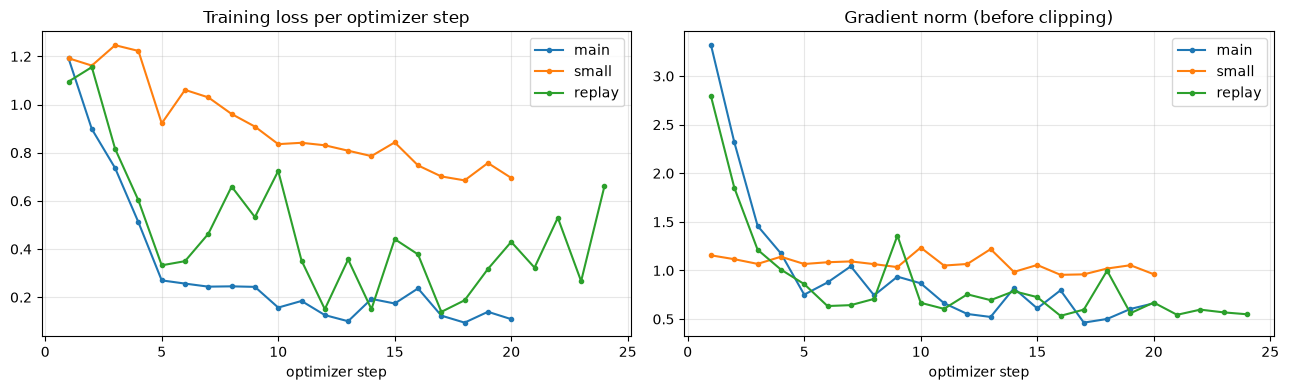

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for name, df in LOGS.items():
    axs[0].plot(df.step, df.loss, marker="o", ms=3, label=name)
    axs[1].plot(df.step, df.grad_norm, marker="o", ms=3, label=name)
axs[0].set_title("Training loss per optimizer step", fontsize=12); axs[0].set_xlabel("optimizer step")
axs[1].set_title("Gradient norm (before clipping)", fontsize=12); axs[1].set_xlabel("optimizer step")
for a in axs:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Оценка после адаптации

### 8.1. Целевая задача: ID и OOD

Оцениваем все три адаптера на тех же наборах, что и базовую модель. Переключение адаптера — `set_adapter`, базовая модель — контекст `disable_adapter()`, загружать модели заново не нужно.

In [23]:
TASK, RAW = {"base": base_task}, {"base": base_raw}
t0 = time.time()
for name in ADAPTERS:
    peft_model.set_adapter(name)
    TASK[name], RAW[name] = eval_task(peft_model)
print(f"оценка трёх адаптеров: {time.time()-t0:.0f} с")
task_tab = pd.concat({k: v for k, v in TASK.items()}, names=["model", "set"])
for metric in ["valid JSON", "exact match", "count acc", "object F1"]:
    print(f"\n{metric}:"); print(task_tab[metric].unstack("set")[list(SETS)].round(3).to_string())
for name, tab in TASK.items():
    for s in SETS:
        record(name, f"{s} exact match", tab.loc[s, "exact match"]); record(name, f"{s} object F1", tab.loc[s, "object F1"])

оценка трёх адаптеров: 473 с

valid JSON:
set      ID  OOD count  OOD texture  OOD color
model                                         
base    0.0      0.000          0.0      0.000
main    1.0      1.000          1.0      1.000
small   0.0      0.042          0.0      0.000
replay  1.0      1.000          1.0      0.958

exact match:
set        ID  OOD count  OOD texture  OOD color
model                                           
base    0.000        0.0        0.000      0.000
main    0.333        0.0        0.375      0.375
small   0.000        0.0        0.000      0.000
replay  0.375        0.0        0.458      0.333

count acc:
set        ID  OOD count  OOD texture  OOD color
model                                           
base    0.000      0.000        0.000      0.000
main    0.792      0.042        0.417      0.708
small   0.000      0.000        0.000      0.000
replay  0.750      0.042        0.458      0.667

object F1:
set        ID  OOD count  OOD texture  OOD color
m

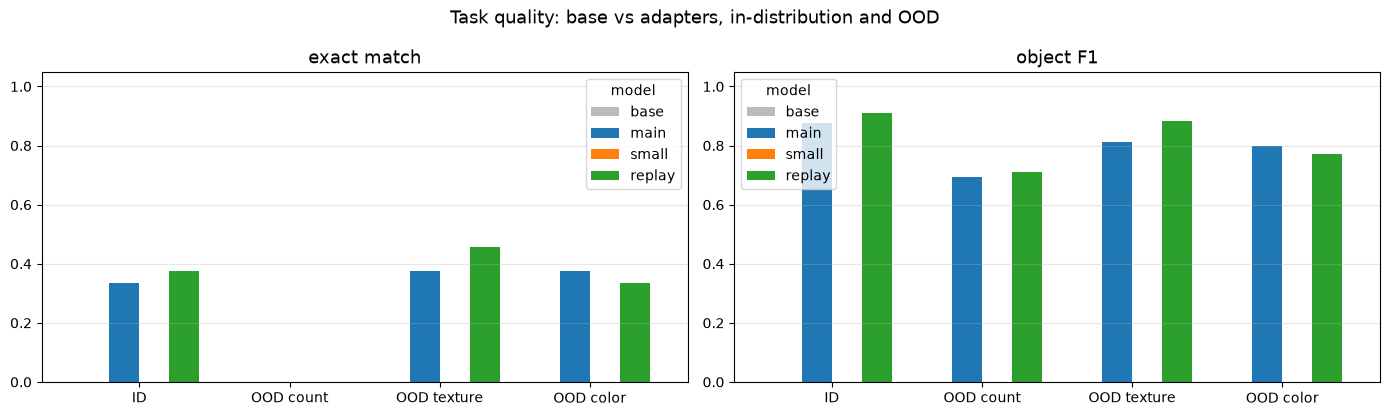

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axs, ["exact match", "object F1"]):
    t = task_tab[metric].unstack("set")[list(SETS)]
    t.T.plot.bar(ax=ax, rot=0, width=0.8, color=["#bbbbbb", "#1f77b4", "#ff7f0e", "#2ca02c"])
    ax.set_title(metric, fontsize=13); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3); ax.set_xlabel("")
plt.suptitle("Task quality: base vs adapters, in-distribution and OOD", fontsize=13); plt.tight_layout(); plt.show()

Посмотрим на ответы основного адаптера на OOD-примерах: какие именно ошибки он делает при каждом сдвиге.

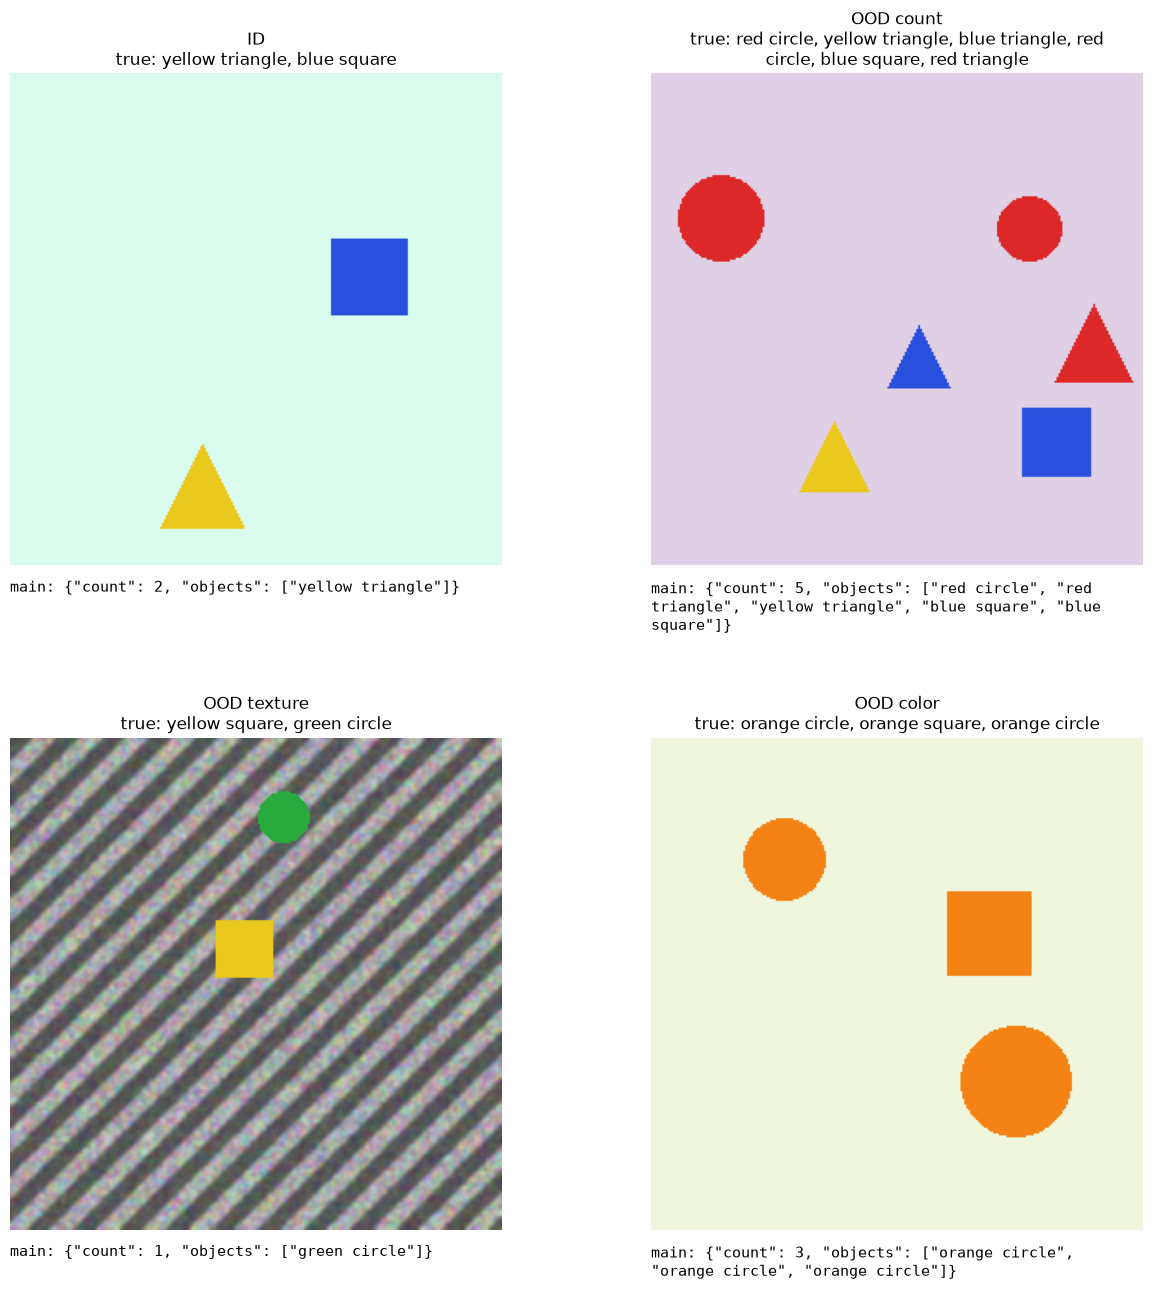

ID           {'wrong number of objects': 6, 'wrong color/shape': 5, 'wrong order': 5, 'correct': 8}
OOD count    {'wrong number of objects': 23, 'wrong color/shape': 1}
OOD texture  {'wrong number of objects': 14, 'correct': 9, 'wrong color/shape': 1}
OOD color    {'wrong color/shape': 6, 'wrong number of objects': 7, 'wrong order': 2, 'correct': 9}


In [25]:
import textwrap
fig, axs = plt.subplots(2, 2, figsize=(13, 13))
for ax, s in zip(axs.flat, ["ID", "OOD count", "OOD texture", "OOD color"]):
    k = next((i for i, (p, e) in enumerate(zip(RAW["main"][s], SETS[s])) if parse_answer(p) is None or
              [o.lower() for o in parse_answer(p)["objects"]] != e["target"]["objects"]), 0)
    ex = SETS[s][k]
    ax.imshow(ex["image"]); ax.axis("off")
    ax.set_title(s + "\n" + textwrap.fill("true: " + ", ".join(ex["target"]["objects"]), 60), fontsize=12)
    ax.text(0.0, -0.03, textwrap.fill("main: " + RAW["main"][s][k][:200], 52), transform=ax.transAxes,
            fontsize=11, va="top", family="monospace")
plt.tight_layout(); plt.subplots_adjust(hspace=0.35); plt.show()
for s in SETS:
    errs = Counter()
    for p, e in zip(RAW["main"][s], SETS[s]):
        d = parse_answer(p)
        if d is None:
            errs["invalid JSON"] += 1; continue
        pred = [o.lower() for o in d["objects"]]
        if pred == e["target"]["objects"]:
            errs["correct"] += 1
        elif len(pred) != len(e["target"]["objects"]):
            errs["wrong number of objects"] += 1
        elif sorted(pred) == sorted(e["target"]["objects"]):
            errs["wrong order"] += 1
        else:
            errs["wrong color/shape"] += 1
    print(f"{s:12s}", dict(errs))

Что показывают цифры (CPU-прогон: 160 обучающих примеров, 20 шагов оптимизатора, по 24 примера в каждом тестовом наборе; один пример — это 0.042 в долях, поэтому разницу меньше 0.1 между адаптерами не стоит считать значимой).

Формат. Базовая модель ни разу не выдала разбираемый JSON нужной схемы: она пересказывает шаблон из вопроса (`"<color> <shape>"`) и придумывает свои поля. После 20 шагов основной адаптер `main` выдаёт корректный JSON в 100% случаев на всех четырёх наборах, включая OOD. Формат ответа — самое лёгкое, чему учит SFT: это поведение, а не знание.

Ёмкость адаптера. Малый адаптер `small` (r = 4, только q и v, 0.23 M параметров) за те же 20 шагов формат не выучил: loss остановился около 0.7 против 0.11 у `main`, валидного JSON почти нет. Это согласуется с выводом статьи QLoRA: чтобы приблизиться к качеству полного дообучения, адаптеры нужно ставить на все линейные слои, а не только на $W_q, W_v$ ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)). Конфигурация из исходной статьи LoRA рассчитана на гораздо большее число шагов.

ID. У `main` F1 по объектам 0.88, точность числа объектов 0.79, но точное совпадение всего списка — 0.33: модель уже видит фигуры и цвета, но ошибается в одном элементе (пропуск, перестановка, путаница цвета) — разбор ошибок выше делит их примерно поровну между этими типами. Это недообучение: в полном режиме (1200 примеров) exact match растёт.

Три вида сдвига ведут себя по-разному.

- OOD count (5–6 фигур при обучении на 1–4): точное совпадение 0, точность счёта 0.04, 23 из 24 ошибок — неверное число объектов. Модель выучила распределение ответов «1–4 объекта» и не экстраполирует счёт. При этом F1 по объектам 0.69: отдельные фигуры она распознаёт. Это типичная ошибка SFT на узком распределении — выученный prior длины ответа.
- OOD texture (полосатый шумный фон): F1 0.81, но точность счёта падает с 0.79 до 0.42 — фон «съедает» часть фигур (в примере выше пропущен жёлтый квадрат). Визуальный энкодер заморожен, и адаптер в языковой модели не может исправить то, что энкодер плохо передаёт.
- OOD color (purple и orange, не встречались в обучении): F1 0.80, точность счёта 0.71. Модель называет новые цвета правильными словами (в примере — «orange»), хотя в обучающих ответах этих слов не было. Знание цветов сохранилось из предобучения, а адаптер выучил только формат и порядок перечисления — это положительный пример переноса.

`replay` по качеству на задаче практически не отличается от `main` (разница в пределах одного–двух примеров на набор): 20% общих диалогов в обучении не мешают выучить задачу.

### 8.2. Забывание: CIFAR-10 и дрейф общих ответов

In [26]:
FORGET = [dict(model="base", cifar_acc=base_cifar, nll_general=base_nll)]
for name in ADAPTERS:
    peft_model.set_adapter(name)
    FORGET.append(dict(model=name, cifar_acc=cifar_accuracy(peft_model), nll_general=answer_nll(peft_model, general_eval)))
forget = pd.DataFrame(FORGET).set_index("model")
forget["Δ cifar"] = forget.cifar_acc - base_cifar
forget["KL estimate"] = forget.nll_general - base_nll
print(forget.round(3).to_string())
for name, row in forget.iterrows():
    record(name, "CIFAR-10 zero-shot", row.cifar_acc); record(name, "KL estimate (general answers)", row["KL estimate"])

        cifar_acc  nll_general  Δ cifar  KL estimate
model                                               
base        0.167        1.199    0.000        0.000
main        0.250        1.220    0.083        0.020
small       0.167        1.203    0.000        0.004
replay      0.167        1.050    0.000       -0.150


Качественная проверка: общие вопросы, которых не было в обучении. Это самый наглядный способ увидеть схлопывание формата.

In [27]:
probe_imgs = [general_eval[i]["image"] for i in range(2)] + [SETS["ID"][0]["image"]]
probe_q = "Describe this image in one sentence."
answers = {"base": None}
with peft_model.disable_adapter():
    answers["base"] = generate(peft_model, probe_imgs, question=probe_q, max_new_tokens=40)
for name in ADAPTERS:
    peft_model.set_adapter(name)
    answers[name] = generate(peft_model, probe_imgs, question=probe_q, max_new_tokens=40)
for i in range(len(probe_imgs)):
    print(f"--- изображение {i + 1} ({'CIFAR-10' if i < 2 else 'фигуры'}) | Q: {probe_q}")
    for name, a in answers.items():
        print(f"  {name:7s}: {a[i][:150]}")

--- изображение 1 (CIFAR-10) | Q: Describe this image in one sentence.
  base   : In this image there is a frog on the ground.
  main   : A turtle is laying on the ground.
  small  : In this image there is a frog on the ground.
  replay : In this image there is a frog on the ground.
--- изображение 2 (CIFAR-10) | Q: Describe this image in one sentence.
  base   : In this image, there is a person wearing a red and blue color dress.
  main   : In this image there is a boat on the ground.
  small  : In this image, there is a person wearing a red and blue color dress.
  replay : In this image there is a boat on the ground.
--- изображение 3 (фигуры) | Q: Describe this image in one sentence.
  base   : In this image, there is a person wearing a blue shirt and a yellow triangle.
  main   : In this image there is a yellow triangle on the right side.
  small  : In this image, there is a person wearing a blue shirt.
  replay : In this image there is a yellow triangle on the right side.


Что показывают цифры.

CIFAR-10. На 60 изображениях базовая модель угадывает 0.167 (случайное угадывание — 0.1), `main` — 0.250, `small` и `replay` — 0.167. Забывания по этой метрике не видно; рост у `main` — 5 изображений из 60, при стандартной ошибке доли около 0.05 это в пределах шума. После 20 шагов на синтетических фигурах катастрофического забывания нет — оно проявляется при более долгом обучении и больших learning rate (задание 7).

Дрейф общих ответов. Оценка KL у `main` 0.020, у `small` 0.004 — малые положительные значения: адаптер немного сдвинул распределение ответов на общие вопросы, малый адаптер — меньше. Качественные примеры показывают, что сдвиг реальный: на втором изображении `main` вместо описания человека пишет «a boat on the ground», то есть ответ изменился по содержанию. Метрика это видит слабо, потому что мерит только вероятность старых ответов.

Почему у `replay` оценка отрицательная (−0.150). Replay-данные — это жадные ответы базовой модели на те же три типа вопросов на других изображениях CIFAR-10. Обучаясь на них, адаптер делает распределение более «острым» вокруг типичных фраз базовой модели («In this image there is …»), поэтому вероятность её жадных ответов на тестовых изображениях становится даже выше, чем у самой базовой модели. Формула из раздела 16.2 теории даёт KL только для ответов, сэмплированных из базовой модели; для жадных ответов разность NLL может быть отрицательной. Вывод для практики: replay снижает дрейф NLL, но не гарантирует сохранения поведения — на втором и третьем изображениях `replay` отвечает так же, как `main`, а не как база. Поэтому оценку забывания всегда дополняют задачами с правильными ответами (здесь — CIFAR-10) и просмотром примеров.

### 8.3. Интерполяция: масштаб адаптера λ

Для LoRA интерполяция между базовой и дообученной моделью бесплатна: $W = W_0 + \lambda \frac{\alpha}{r} BA$. При $\lambda = 0$ — базовая модель, при $\lambda = 1$ — адаптированная. Меняем множитель `scaling` у всех LoRA-слоёв основного адаптера и для каждого $\lambda$ измеряем качество задачи (ID) и сохранение общих способностей.

 lam  exact_match  object_F1  valid_JSON  cifar_acc  kl_est
0.00        0.000      0.000       0.000      0.167   0.000
0.25        0.083      0.340       0.708      0.183  -0.007
0.50        0.458      0.879       1.000      0.217  -0.006
0.75        0.375      0.860       1.000      0.267   0.005
1.00        0.333      0.876       1.000      0.250   0.020


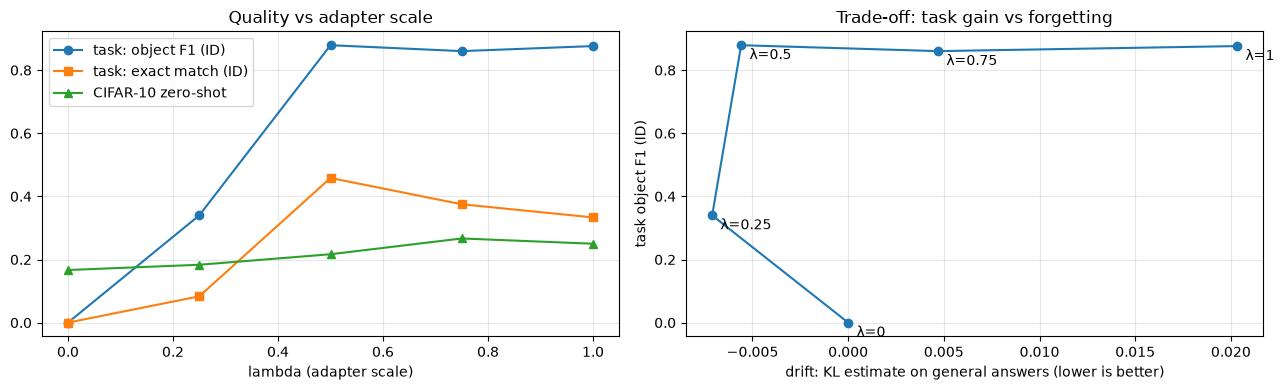

In [28]:
from contextlib import contextmanager

@contextmanager
def lora_scale(name, lam):
    mods = [m for m in peft_model.modules() if hasattr(m, "scaling") and isinstance(m.scaling, dict) and name in m.scaling]
    orig = [m.scaling[name] for m in mods]
    for m in mods:
        m.scaling[name] *= lam
    try:
        yield
    finally:
        for m, o in zip(mods, orig):
            m.scaling[name] = o

peft_model.set_adapter("main")
curve = []
for lam in [0.0, 0.25, 0.5, 0.75, 1.0]:
    with lora_scale("main", lam):
        preds = generate(peft_model, [e["image"] for e in SETS["ID"]])
        sc = score(preds, SETS["ID"])
        curve.append(dict(lam=lam, exact_match=sc["exact match"], object_F1=sc["object F1"], valid_JSON=sc["valid JSON"],
                          cifar_acc=cifar_accuracy(peft_model), kl_est=answer_nll(peft_model, general_eval) - base_nll))
curve = pd.DataFrame(curve)
print(curve.round(3).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(curve.lam, curve.object_F1, "o-", label="task: object F1 (ID)")
axs[0].plot(curve.lam, curve.exact_match, "s-", label="task: exact match (ID)")
axs[0].plot(curve.lam, curve.cifar_acc, "^-", label="CIFAR-10 zero-shot")
axs[0].set_xlabel("lambda (adapter scale)"); axs[0].legend(); axs[0].grid(alpha=0.3); axs[0].set_title("Quality vs adapter scale", fontsize=12)
axs[1].plot(curve.kl_est, curve.object_F1, "o-")
for _, r in curve.iterrows():
    axs[1].annotate(f"λ={r.lam:g}", (r.kl_est, r.object_F1), textcoords="offset points", xytext=(6, -10), fontsize=10)
axs[1].set_xlabel("drift: KL estimate on general answers (lower is better)"); axs[1].set_ylabel("task object F1 (ID)")
axs[1].set_title("Trade-off: task gain vs forgetting", fontsize=12); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Что показывают цифры. Масштаб $\lambda$ линейно интерполирует веса между базовой моделью ($\lambda = 0$) и адаптированной ($\lambda = 1$), как в WiSE-FT ([Wortsman et al., 2021](https://arxiv.org/abs/2109.01903)).

- При $\lambda = 0.25$ модель выдаёт валидный JSON в 71% случаев, но F1 только 0.34 — четверти поправки мало.
- При $\lambda = 0.5$ уже достигнуто всё качество задачи: F1 0.88 (как при $\lambda = 1$), валидный JSON 100%, а exact match даже выше — 0.46 против 0.33 (это 11 против 8 примеров из 24, то есть разница на уровне шума).
- Оценка дрейфа до $\lambda = 0.5$ остаётся около нуля (−0.006) и растёт до 0.020 только к $\lambda = 1$. CIFAR-10 меняется в пределах шума (0.167–0.267).

Правый график показывает компромисс: точка $\lambda = 0.5$ находится в левом верхнем углу — почти всё качество задачи при минимальном дрейфе. Практический вывод: масштаб адаптера — дешёвый гиперпараметр, который подбирают на валидации после обучения, без переобучения (как функция `lora_scale` выше; в PEFT для комбинации адаптеров с весами есть `add_weighted_adapter`).

## 9. Адаптер: сохранение, загрузка, слияние

`save_pretrained` у PEFT-модели сохраняет только веса адаптера и его конфигурацию (`adapter_config.json`), но не базовую модель. Загрузим сохранённый адаптер под другим именем в ту же модель и проверим, что логиты совпадают. В разделе 10.4 на CPU (без квантования) сольём адаптер в веса через `merge_and_unload()` и проверим, что результат не изменился. На GPU с 4-битной базой слияние пропускаем: сумма $W_0 + \Delta W$ не представима в NF4 без повторного квантования (раздел 7.3 теории).

In [29]:
ADAPTER_DIR = ART / "adapter_main"
peft_model.save_pretrained(str(ART / "adapters"), selected_adapters=["main"])
saved = next((ART / "adapters").rglob("adapter_model.safetensors"))
ADAPTER_DIR = saved.parent
files = {p.name: p.stat().st_size for p in ADAPTER_DIR.iterdir()}
ADAPTER_SHA = hashlib.sha256(saved.read_bytes()).hexdigest()
print("каталог:", ADAPTER_DIR, "| файлы:", {k: f"{v/2**20:.2f} МБ" for k, v in files.items()})
print(f"размер адаптера {files['adapter_model.safetensors']/2**20:.1f} МБ против {n_params * (0.52 if USE_4BIT else 2) / 2**20:.0f} МБ базовой модели"
      f"{' в NF4' if USE_4BIT else ' в bf16'} | sha256 {ADAPTER_SHA[:16]}")
print(json.dumps({k: v for k, v in json.load(open(ADAPTER_DIR / "adapter_config.json")).items()
                  if k in ("r", "lora_alpha", "lora_dropout", "target_modules", "base_model_name_or_path", "use_rslora", "use_dora")}, indent=1))

peft_model.load_adapter(str(ADAPTER_DIR), adapter_name="main_reloaded")
enc = build_example(SETS["ID"][0]).to(DEVICE)
with torch.no_grad():
    peft_model.set_adapter("main"); l1 = peft_model(**enc).logits.float()
    peft_model.set_adapter("main_reloaded"); l2 = peft_model(**enc).logits.float()
print("логиты после перезагрузки адаптера совпадают:", torch.allclose(l1, l2, atol=1e-5), f"(макс. разница {(l1 - l2).abs().max():.1e})")
peft_model.delete_adapter("main_reloaded"); peft_model.set_adapter("main")

каталог: artifacts/adapters/main | файлы: {'adapter_config.json': '0.00 МБ', 'adapter_model.safetensors': '18.69 МБ'}
размер адаптера 18.7 МБ против 489 МБ базовой модели в bf16 | sha256 d6acb6336dc977f8
{
 "base_model_name_or_path": "HuggingFaceTB/SmolVLM-256M-Instruct",
 "lora_alpha": 32,
 "lora_dropout": 0.05,
 "r": 16,
 "target_modules": ".*(?:text_model|language_model).*\\.(?:q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)",
 "use_dora": false,
 "use_rslora": false
}


логиты после перезагрузки адаптера совпадают: True (макс. разница 0.0e+00)


## 10. Воспроизводимость и экспорт в инструменты

### 10.1. Конфиг эксперимента

Собираем всё, что нужно для повтора эксперимента, в один словарь и сохраняем как YAML и JSON рядом с адаптером: модель и её ревизия, версии библиотек, сиды, параметры генератора данных и хеш обучающего набора, гиперпараметры, хеш адаптера, итоговые метрики.

In [30]:
import yaml
def dataset_hash(data):
    h = hashlib.sha256()
    for e in data:
        h.update(hashlib.sha256(e["image"].tobytes()).digest()); h.update(answer_text(e["target"]).encode())
    return h.hexdigest()

RUN_CONFIG = {
    "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "load_in_4bit": USE_4BIT, "compute_dtype": str(COMPUTE_DTYPE),
              "attn_implementation": "sdpa", "processor_kwargs": {"do_image_splitting": False} if "SmolVLM" in MODEL_ID else {}},
    "environment": {"python": platform.python_version(), **VERSIONS, "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu"},
    "data": {"generator": "make_scene v1", "train_seed": 1, "n_train": len(train_set), "img_side": IMG_SIDE,
             "train_sha256": dataset_hash(train_set), "eval_seeds": {"ID": 101, "OOD count": 102, "OOD texture": 103, "OOD color": 104},
             "question": QUESTION, "loss_mask": "assistant answer + end-of-turn token"},
    "training": TRAIN_CFG,
    "adapters": {k: {**v, "target_regex": LM_REGEX.format("|".join(v["targets"]))} for k, v in ADAPTERS.items()},
    "artifacts": {"adapter_main_sha256": ADAPTER_SHA},
    "results": {f"{r['section']} | {r['metric']}": round(float(r["value"]), 4) for r in RESULTS},
}
(ART / "run_config.yaml").write_text(yaml.safe_dump(RUN_CONFIG, allow_unicode=True, sort_keys=False))
(ART / "run_config.json").write_text(json.dumps(RUN_CONFIG, ensure_ascii=False, indent=1))
print("\n".join((ART / "run_config.yaml").read_text().splitlines()[:48]))
print("...")

model:
  id: HuggingFaceTB/SmolVLM-256M-Instruct
  revision: 7e3e67edbbed1bf9888184d9df282b700a323964
  load_in_4bit: false
  compute_dtype: torch.float32
  attn_implementation: sdpa
  processor_kwargs:
    do_image_splitting: false
environment:
  python: 3.12.13
  torch: 2.14.1+cpu
  transformers: 5.19.0
  peft: 0.21.2
  accelerate: 1.15.0
  numpy: 2.5.2
  device: cpu
data:
  generator: make_scene v1
  train_seed: 1
  n_train: 160
  img_side: 256
  train_sha256: e1bba0d097119733604a541a0863f36eab02d81df37ebe2c2407f67cd37b7da3
  eval_seeds:
    ID: 101
    OOD count: 102
    OOD texture: 103
    OOD color: 104
  question: 'List the shapes in the image from left to right. Answer with JSON: {"count":
    N, "objects": ["<color> <shape>", ...]}.'
  loss_mask: assistant answer + end-of-turn token
training:
  micro_batch: 1
  grad_accum: 8
  lr: 0.0003
  warmup_ratio: 0.1
  epochs: 1
  max_grad_norm: 1.0
  weight_decay: 0.0
  lora_dropout: 0.05
  replay_frac: 0.2
  seed: 0
adapters:
  main:

Проверим воспроизводимость на практике: повторим первые два шага оптимизации основного адаптера с тем же сидом и сравним loss. На CPU результат совпадает побитово; на GPU возможны расхождения в последних знаках из-за недетерминированных ядер (раздел 14 теории).

In [31]:
def short_run(seed, n_micro=4):
    seed_everything(seed)
    cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=LM_REGEX.format("q_proj|v_proj"))
    name = f"repro_{seed}_{random.randint(0, 10**6)}"
    seed_everything(seed)
    peft_model.add_adapter(name, cfg); peft_model.set_adapter(name)
    for n, p in peft_model.named_parameters():
        p.requires_grad_(f".{name}." in n)
    opt_ = torch.optim.AdamW([p for p in peft_model.parameters() if p.requires_grad], lr=1e-3)
    peft_model.train(); losses = []
    for e in train_set[:n_micro]:
        out = peft_model(**build_example(e).to(DEVICE))
        out.loss.backward(); opt_.step(); opt_.zero_grad(); losses.append(round(out.loss.item(), 6))
    peft_model.eval(); peft_model.delete_adapter(name)
    return losses

r1, r2, r3 = short_run(0), short_run(0), short_run(1)
print("seed 0, запуск 1:", r1); print("seed 0, запуск 2:", r2); print("seed 1:          ", r3)
print("запуски с одинаковым сидом совпадают:", r1 == r2)

seed 0, запуск 1: [1.283728, 0.802199, 0.975911, 0.592985]
seed 0, запуск 2: [1.283728, 0.802199, 0.975911, 0.592985]
seed 1:           [1.283728, 0.810255, 0.973455, 0.598435]
запуски с одинаковым сидом совпадают: True


### 10.2. Экспорт в LLaMA-Factory

Тот же эксперимент в LLaMA-Factory описывается тремя файлами: датасет в формате sharegpt (изображения — отдельными файлами, тег `<image>` в тексте реплики), запись в `dataset_info.json` и YAML-конфиг обучения. Структура соответствует документации и примеру `qwen3vl_lora_sft.yaml` из репозитория ([LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_sft.yaml)). Запуск: `llamafactory-cli train artifacts/llamafactory/shapes_qlora_sft.yaml` из каталога, где установлен LLaMA-Factory.

In [32]:
LF = ART / "llamafactory"; (LF / "images").mkdir(parents=True, exist_ok=True)
records = []
for i, e in enumerate(train_set):
    p = LF / "images" / f"train_{i:05d}.png"
    e["image"].save(p)
    records.append({"conversations": [{"from": "human", "value": "<image>" + QUESTION},
                                      {"from": "gpt", "value": answer_text(e["target"])}],
                    "images": [f"images/{p.name}"]})
assert all(r["conversations"][0]["value"].count("<image>") == len(r["images"]) for r in records)
(LF / "shapes_sft.json").write_text(json.dumps(records, ensure_ascii=False, indent=1))
(LF / "dataset_info.json").write_text(json.dumps({"shapes_sft": {"file_name": "shapes_sft.json", "formatting": "sharegpt",
                                                                  "columns": {"messages": "conversations", "images": "images"}}}, indent=1))
lf_cfg = {
    "model_name_or_path": "Qwen/Qwen3-VL-2B-Instruct", "image_max_pixels": IMG_SIDE * IMG_SIDE, "trust_remote_code": True,
    "quantization_bit": 4, "quantization_method": "bnb", "double_quantization": True,
    "stage": "sft", "do_train": True, "finetuning_type": "lora",
    "lora_rank": ADAPTERS["main"]["r"], "lora_alpha": ADAPTERS["main"]["alpha"], "lora_dropout": TRAIN_CFG["lora_dropout"], "lora_target": "all",
    "freeze_vision_tower": True, "freeze_multi_modal_projector": True,
    "dataset": "shapes_sft", "dataset_dir": str(LF), "template": "qwen3_vl_nothink", "cutoff_len": 1024,
    "output_dir": "saves/qwen3-vl-2b/qlora/shapes", "logging_steps": 5, "save_steps": 500, "plot_loss": True, "report_to": "none",
    "per_device_train_batch_size": 1, "gradient_accumulation_steps": TRAIN_CFG["grad_accum"], "learning_rate": TRAIN_CFG["lr"],
    "num_train_epochs": float(TRAIN_CFG["epochs"]), "lr_scheduler_type": "cosine", "warmup_ratio": TRAIN_CFG["warmup_ratio"],
    "fp16": True, "optim": "paged_adamw_8bit", "flash_attn": "sdpa", "seed": SEED,
}
(LF / "shapes_qlora_sft.yaml").write_text(yaml.safe_dump(lf_cfg, sort_keys=False))
print(sorted(p.name for p in LF.iterdir()), "| изображений:", len(list((LF / "images").iterdir())))
print(json.dumps(records[0], indent=1)); print((LF / "shapes_qlora_sft.yaml").read_text())

['dataset_info.json', 'images', 'shapes_qlora_sft.yaml', 'shapes_sft.json'] | изображений: 160
{
 "conversations": [
  {
   "from": "human",
   "value": "<image>List the shapes in the image from left to right. Answer with JSON: {\"count\": N, \"objects\": [\"<color> <shape>\", ...]}."
  },
  {
   "from": "gpt",
   "value": "{\"count\": 4, \"objects\": [\"red triangle\", \"yellow square\", \"red square\", \"yellow circle\"]}"
  }
 ],
 "images": [
  "images/train_00000.png"
 ]
}
model_name_or_path: Qwen/Qwen3-VL-2B-Instruct
image_max_pixels: 65536
trust_remote_code: true
quantization_bit: 4
quantization_method: bnb
double_quantization: true
stage: sft
do_train: true
finetuning_type: lora
lora_rank: 16
lora_alpha: 32
lora_dropout: 0.05
lora_target: all
freeze_vision_tower: true
freeze_multi_modal_projector: true
dataset: shapes_sft
dataset_dir: artifacts/llamafactory
template: qwen3_vl_nothink
cutoff_len: 1024
output_dir: saves/qwen3-vl-2b/qlora/shapes
logging_steps: 5
save_steps: 500
plo

### 10.3. То же обучение через Transformers Trainer, TRL и Unsloth

Собственный цикл из раздела 7 нужен, чтобы видеть каждый шаг. В реальных проектах те же настройки задаются конфигом. Ниже — `TrainingArguments`, эквивалентные нашему циклу (создаём объект, чтобы проверить, что все аргументы существуют в установленной версии, но не обучаем повторно).

In [33]:
from transformers import TrainingArguments
# warmup_ratio удалён в transformers 5.x, поэтому задаём целое число шагов (работает и в 4.x, и в 5.x)
WARMUP_STEPS = max(1, int(TRAIN_CFG["warmup_ratio"] * len(train_set) * TRAIN_CFG["epochs"] / TRAIN_CFG["grad_accum"]))
targs = TrainingArguments(
    output_dir=str(ART / "trainer_out"), per_device_train_batch_size=1, gradient_accumulation_steps=TRAIN_CFG["grad_accum"],
    learning_rate=TRAIN_CFG["lr"], lr_scheduler_type="cosine", warmup_steps=WARMUP_STEPS, num_train_epochs=TRAIN_CFG["epochs"],
    max_grad_norm=TRAIN_CFG["max_grad_norm"], gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="paged_adamw_8bit" if HAS_GPU else "adamw_torch", fp16=HAS_GPU and COMPUTE_DTYPE == torch.float16,
    bf16=HAS_GPU and COMPUTE_DTYPE == torch.bfloat16, seed=SEED, data_seed=SEED, logging_steps=5, report_to="none",
    remove_unused_columns=False, save_strategy="no")
print({k: getattr(targs, k) for k in ["per_device_train_batch_size", "gradient_accumulation_steps", "learning_rate", "optim",
                                      "gradient_checkpointing", "fp16", "bf16", "seed"]})

{'per_device_train_batch_size': 1, 'gradient_accumulation_steps': 8, 'learning_rate': 0.0003, 'optim': <OptimizerNames.ADAMW_TORCH: 'adamw_torch'>, 'gradient_checkpointing': True, 'fp16': False, 'bf16': False, 'seed': 0}


С TRL то же самое записывается так (код не выполняется в блокноте, чтобы не ставить лишние пакеты):

```python
from trl import SFTConfig, SFTTrainer
# датасет: столбцы "messages" (формат из раздела 2.2) и "images" (список PIL-изображений)
cfg = SFTConfig(output_dir="out", per_device_train_batch_size=1, gradient_accumulation_steps=8, learning_rate=3e-4,
                gradient_checkpointing=True, optim="paged_adamw_8bit", max_length=None,   # не обрезать визуальные токены
                assistant_only_loss=True)                                                # loss только по ответам
trainer = SFTTrainer(model=model, args=cfg, train_dataset=ds, processing_class=processor, peft_config=main_cfg)
trainer.train()
```

С Unsloth — загрузка через `FastVisionModel.from_pretrained(..., load_in_4bit=True, use_gradient_checkpointing="unsloth")`, адаптер через `FastVisionModel.get_peft_model(model, finetune_vision_layers=False, finetune_language_layers=True, r=16, lora_alpha=16)` и тот же `SFTTrainer` с коллатором `UnslothVisionDataCollator` (раздел 13.4 теории).

### 10.4. Слияние адаптера

Последний шаг — слияние основного адаптера с весами (раздел 9 был про сохранение; слияние делаем в конце, потому что `merge_and_unload()` удаляет LoRA-слои и остальные адаптеры).

In [34]:
if not USE_4BIT:
    for name in ["small", "replay"]:
        peft_model.delete_adapter(name)
    peft_model.set_adapter("main")
    merged_model = peft_model.merge_and_unload()
    with torch.no_grad():
        l3 = merged_model(**enc).logits.float()
    n_lora_left = sum("lora_" in n for n, _ in merged_model.named_parameters())
    print(f"после merge_and_unload: LoRA-параметров осталось {n_lora_left}, тип модели {type(merged_model).__name__}")
    print(f"макс. разница логитов слитой модели и модели с адаптером: {(l1 - l3).abs().max():.1e}")
    print("предсказание совпадает:", bool((l1.argmax(-1) == l3.argmax(-1)).all()))
else:
    print("4-bit база: слияние требует загрузить базовую модель в bf16, применить PeftModel.from_pretrained и вызвать merge_and_unload()")

после merge_and_unload: LoRA-параметров осталось 0, тип модели Idefics3ForConditionalGeneration
макс. разница логитов слитой модели и модели с адаптером: 8.1e-05
предсказание совпадает: True


## Итоги практики

In [35]:
summary = pd.DataFrame(RESULTS)
piv = summary.pivot_table(index="metric", columns="section", values="value", aggfunc="first")
cols = [c for c in ["base", "main", "small", "replay"] if c in piv.columns]
print(piv[cols].round(3).to_string())
print("\nобучение:"); print(pd.DataFrame(TRAIN_INFO).round(2).to_string(index=False))

section                         base   main  small  replay
metric                                                    
CIFAR-10 zero-shot             0.167  0.250  0.167   0.167
ID exact match                 0.000  0.333  0.000   0.375
ID object F1                   0.000  0.876  0.000   0.910
KL estimate (general answers)  0.000  0.020  0.004  -0.150
OOD color exact match          0.000  0.375  0.000   0.333
OOD color object F1            0.000  0.797  0.000   0.772
OOD count exact match          0.000  0.000  0.000   0.000
OOD count object F1            0.000  0.693  0.000   0.710
OOD texture exact match        0.000  0.375  0.000   0.458
OOD texture object F1          0.000  0.813  0.000   0.885

обучение:
adapter  examples  opt_steps  minutes  trainable  peak_gb
   main       160         20    11.29    4884480      NaN
  small       160         20    10.08     230400      NaN
 replay       192         24    13.51    4884480      NaN


Итоги CPU-прогона (SmolVLM-256M в fp32, 160 примеров, 20 шагов, около 11 минут на адаптер).

1. LoRA на всех линейных слоях языковой модели (4.9 M обучаемых параметров, 1.9% модели, файл адаптера 18.7 МБ) за 20 шагов научила модель формату ответа (валидный JSON 0 → 100%) и почти решила задачу на ID (F1 0 → 0.88).
2. Малый адаптер (r = 4, только q, v; 0.23 M параметров) при том же бюджете шагов задачу не выучил. Ёмкость и выбор целевых модулей важны при коротком обучении.
3. OOD-оценка показывает три разных вида обобщения: новые цвета модель называет правильно (знание из предобучения сохранилось), на шумном фоне теряет часть объектов (ограничение замороженного визуального энкодера), а счёт за пределы обучающего диапазона не экстраполирует вовсе (точность счёта 0.04).
4. Катастрофического забывания за 20 шагов нет: CIFAR-10 не упал, дрейф NLL мал. Качественные примеры при этом показывают изменения ответов на общие вопросы, поэтому одной метрики дрейфа недостаточно.
5. Replay снижает дрейф NLL (даже ниже нуля), не ухудшая задачу, но не возвращает исходное поведение полностью; масштаб адаптера $\lambda = 0.5$ даёт почти всё качество задачи при минимальном дрейфе.
6. Память: для 4B-модели полное дообучение около 68 ГБ, QLoRA с gradient checkpointing около 3 ГБ; checkpointing уменьшил сохраняемые активации в 7.4 раза ценой замедления в 1.35 раза; SDPA вместо eager attention при длине 4096 хранит в 33 раза меньше.
7. Воспроизводимость: два запуска с одинаковым сидом дали совпадающие loss, адаптер после перезагрузки и слитая модель дают те же предсказания.

На GPU (Colab T4) тот же код работает с Qwen3-VL-2B в режиме QLoRA (NF4, double quantization, paged 8-bit AdamW) и большим числом примеров; конкретные числа там будут другими, и интерпретации выше нужно сверить с вашим прогоном.

# Контрольные вопросы

1. Перечислите ступени «лестницы вмешательств» до дообучения. В каких двух ситуациях из таблицы раздела 1.3 дообучение — неверный первый шаг и почему?
2. Почему при полном дообучении в смешанной точности с Adam нужно около 16 байт на параметр? Сколько из них остаётся на замороженный параметр при LoRA и при QLoRA?
3. Чем chat template отличается от токенизатора? Приведите три ошибки, связанные с шаблоном, которые не приводят к падению кода, но ухудшают модель.
4. Как процессор VLM определяет, сколько визуальных токенов вставить вместо плейсхолдера? Почему нельзя обрезать последовательность по `max_length`, не учитывая визуальные токены?
5. Запишите loss с маской. Почему токен конца реплики должен входить в loss, а визуальные токены — нет? В каком случае loss по инструкции может быть полезен?
6. Почему наивное усреднение loss по микробатчам при gradient accumulation не эквивалентно большому батчу? Запишите правильную нормировку.
7. Почему $B$ в LoRA инициализируется нулями, а $A$ — нет? Что произойдёт, если инициализировать нулями обе матрицы?
8. Сколько обучаемых параметров у LoRA с $r = 16$ на слое 2560×9728? Какую долю от слоя это составляет?
9. Чем отличается масштаб $\alpha / r$ от $\alpha / \sqrt{r}$? Объясните, почему при $\alpha / r$ большой ранг может не дать выигрыша.
10. Почему в VLM нельзя просто написать `target_modules=["q_proj", "v_proj"]`, если вы хотите адаптировать только языковую модель?
11. Как строятся уровни NF4 и почему среди них есть точный ноль? Почему NF4 точнее int4 на весах нейросети?
12. Посчитайте расход памяти на константы квантования без и с double quantization для 4B-модели при блоке 64.
13. Что делают paged optimizers? Уменьшают ли они средний расход памяти?
14. Оцените память активаций одного слоя по формуле Korthikanti et al. для $s = 1024, h = 2560, a = 32, b = 1$. Какая доля приходится на матрицу внимания? Что изменит memory-efficient attention?
15. Почему gradient checkpointing увеличивает время шага, а не только экономит память? Чем reentrant-вариант отличается от non-reentrant при замороженной модели?
16. Почему на T4 нельзя использовать FlashAttention-2 и bf16? Что используется вместо них?
17. Какие шесть групп сведений нужно сохранить, чтобы эксперимент с дообучением был воспроизводим?
18. Как построить OOD-набор, падение на котором можно интерпретировать? Приведите пример для задачи извлечения полей из документов.
19. Почему рост NLL ответов базовой модели под адаптированной моделью — оценка KL-дивергенции? Какой KL — прямой или обратный?
20. Сравните способы защиты от забывания: replay, интерполяция весов, отдельные адаптеры. Когда какой выбрать?

# Задания

Задание 1. Маска и шаблон (базовое). Добавьте в `to_messages` системный промпт и проверьте, остаётся ли промпт префиксом полного диалога для обеих моделей. Постройте маску для двухходового диалога (два вопроса и два ответа к одному изображению) методом поиска маркеров ролей и визуализируйте её.

Задание 2. Нормировка (базовое). Повторите эксперимент раздела 6.3 с примерами, длина ответов которых различается в 5 раз (одна фигура и шесть фигур). Как меняется косинус между наивным и правильным градиентами? Обучите основной адаптер с наивной нормировкой и сравните качество на OOD count.

Задание 3. Ранг и целевые модули (среднее). Обучите адаптеры с $r \in \{2, 8, 32\}$ на всех линейных слоях и с $r = 16$ только на MLP-слоях. Постройте зависимость exact match на ID и OOD от числа обучаемых параметров. Повторите для двух сидов и оцените разброс.

Задание 4. rsLoRA (среднее). Обучите основной адаптер с $r = 64$ с `use_rslora=False` и `use_rslora=True` при одном и том же learning rate. Сравните кривые loss и качество. Согласуется ли результат с игрушечным экспериментом раздела 3.1?

Задание 5. Квантование (среднее). Расширьте раздел 4: добавьте формат fp4 (уровни 4-битного float с 2 битами экспоненты) и блоки размером 32, 64, 128, 256. Постройте зависимость относительной ошибки от числа бит на параметр (с учётом констант). Где оптимум?

Задание 6. Память на GPU (среднее, нужен GPU). Измерьте `torch.cuda.max_memory_allocated` для шага обучения Qwen3-VL-2B в 4 битах при изображениях 256², 512², 768² с checkpointing и без. Сравните с калькулятором раздела 6.2. Какую долю памяти дают активации?

Задание 7. Забывание (продвинутое). Обучайте основной адаптер 1, 2 и 4 эпохи. Постройте кривые «качество на ID / OOD / CIFAR-10 / KL» от числа шагов. Наступает ли момент, когда OOD-качество начинает падать при растущем ID-качестве? Добавьте replay с долями 10%, 20%, 50%.

Задание 8. Инструменты (продвинутое, нужен GPU). Запустите экспортированный конфиг в LLaMA-Factory на Colab T4 и сравните качество полученного адаптера с адаптером из собственного цикла на тех же оценочных наборах. Совпадают ли числа обучаемых параметров? Если нет, найдите, какие модули выбрал `lora_target: all`.

# Источники

PEFT и LoRA

- Hu E. et al. LoRA: Low-Rank Adaptation of Large Language Models, 2021. https://arxiv.org/abs/2106.09685
- Dettmers T. et al. QLoRA: Efficient Finetuning of Quantized LLMs, 2023. https://arxiv.org/abs/2305.14314
- Kalajdzievski D. A Rank Stabilization Scaling Factor for Fine-Tuning with LoRA, 2023. https://arxiv.org/abs/2312.03732
- Liu S.-Y. et al. DoRA: Weight-Decomposed Low-Rank Adaptation, 2024. https://arxiv.org/abs/2402.09353
- Biderman D. et al. LoRA Learns Less and Forgets Less, 2024. https://arxiv.org/abs/2405.09673
- Houlsby N. et al. Parameter-Efficient Transfer Learning for NLP, 2019. https://arxiv.org/abs/1902.00751
- Lester B., Al-Rfou R., Constant N. The Power of Scale for Parameter-Efficient Prompt Tuning, 2021. https://arxiv.org/abs/2104.08691
- Li X. L., Liang P. Prefix-Tuning: Optimizing Continuous Prompts for Generation, 2021. https://arxiv.org/abs/2101.00190
- Ben Zaken E., Ravfogel S., Goldberg Y. BitFit, 2021. https://arxiv.org/abs/2106.10199
- Liu H. et al. Few-Shot Parameter-Efficient Fine-Tuning is Better and Cheaper than In-Context Learning ((IA)³), 2022. https://arxiv.org/abs/2205.05638
- Dettmers T. et al. 8-bit Optimizers via Block-wise Quantization, 2021. https://arxiv.org/abs/2110.02861

Память и внимание

- Chen T. et al. Training Deep Nets with Sublinear Memory Cost, 2016. https://arxiv.org/abs/1604.06174
- Korthikanti V. et al. Reducing Activation Recomputation in Large Transformer Models, 2022. https://arxiv.org/abs/2205.05198
- Rabe M., Staats C. Self-attention Does Not Need O(n²) Memory, 2021. https://arxiv.org/abs/2112.05682
- Dao T. et al. FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness, 2022. https://arxiv.org/abs/2205.14135
- FlashAttention, репозиторий (поддерживаемые GPU). https://github.com/Dao-AILab/flash-attention
- PyTorch: scaled_dot_product_attention. https://docs.pytorch.org/docs/2.12/generated/torch.nn.functional.scaled_dot_product_attention.html
- Hugging Face. Fixing Gradient Accumulation, 2024. https://huggingface.co/blog/gradient_accumulation

VLM и SFT

- Liu H. et al. Visual Instruction Tuning (LLaVA), 2023. https://arxiv.org/abs/2304.08485
- Liu H. et al. Improved Baselines with Visual Instruction Tuning (LLaVA-1.5), 2023. https://arxiv.org/abs/2310.03744
- Wang P. et al. Qwen2-VL, 2024. https://arxiv.org/abs/2409.12191
- Qwen Team. Qwen3-VL Technical Report, 2025. https://arxiv.org/abs/2511.21631
- Marafioti A. et al. SmolVLM: Redefining Small and Efficient Multimodal Models, 2025. https://arxiv.org/abs/2504.05299
- Shi Z. et al. Instruction Tuning With Loss Over Instructions, 2024. https://arxiv.org/abs/2405.14394

Оценка и забывание

- Zhai Y. et al. Investigating the Catastrophic Forgetting in Multimodal Large Language Models (EMT), 2023. https://arxiv.org/abs/2309.10313
- Luo Y. et al. An Empirical Study of Catastrophic Forgetting in Large Language Models During Continual Fine-tuning, 2023. https://arxiv.org/abs/2308.08747
- Kumar A. et al. Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution, 2022. https://arxiv.org/abs/2202.10054
- Wortsman M. et al. Robust fine-tuning of zero-shot models (WiSE-FT), 2022. https://arxiv.org/abs/2109.01903
- Kirkpatrick J. et al. Overcoming catastrophic forgetting in neural networks (EWC), 2017. https://arxiv.org/abs/1612.00796

Инструменты

- PEFT: LoRA developer guide. https://huggingface.co/docs/peft/main/en/developer_guides/lora
- TRL: SFT Trainer. https://huggingface.co/docs/trl/main/en/sft_trainer
- bitsandbytes: 8-bit optimizers. https://huggingface.co/docs/bitsandbytes/main/en/optimizers
- Zheng Y. et al. LlamaFactory: Unified Efficient Fine-Tuning of 100+ Language Models, 2024. https://arxiv.org/abs/2403.13372
- LLaMA-Factory, репозиторий. https://github.com/hiyouga/LLaMA-Factory
- LLaMA-Factory, формат данных. https://github.com/hiyouga/LLaMA-Factory/blob/main/data/README.md
- LLaMA-Factory, пример конфига Qwen3-VL. https://github.com/hiyouga/LLaMA-Factory/blob/main/examples/train_lora/qwen3vl_lora_sft.yaml
- Unsloth, репозиторий. https://github.com/unslothai/unsloth
- Unsloth: Vision Fine-tuning. https://docs.unsloth.ai/basics/vision-fine-tuning
- Unsloth: скрипт обучения Qwen3-VL. https://huggingface.co/datasets/unsloth/jobs/blob/main/sft-qwen3-vl.py

Модели и данные практики

- SmolVLM-256M-Instruct. https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct
- Qwen3-VL-4B-Instruct. https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct
- Qwen3-VL-2B-Instruct. https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct
- CIFAR-10 (Hugging Face). https://huggingface.co/datasets/uoft-cs/cifar10